In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr

from cordex2energy.conversion_energy.tyndp import load_tyndp_supply_capacities
from cordex2energy_analysis.extreme_value import (
    calculate_climatological_baseline,
    compute_continuous_system_metrics,
    resolve_gwl_period_definitions,
)
from cordex2energy_analysis.extremes_thresholds import (
    compute_active_threshold,
    calibrate_seasonal_active_thresholds,
)
from cordex2energy_analysis.extremes_events import DEFAULT_DURATION_BINS
from cordex2energy_analysis.extremes_analysis import (
    compute_duration_stratified_metrics,
    compute_seasonal_duration_stratified_metrics,
)
from cordex2energy_analysis.plotting_extremes import (
    plot_violin_grid,
    plot_attribution_stacked_bars,
    plot_component_anomaly_distributions,
    plot_seasonal_conditional_metrics,
    plot_seasonal_attribution,
    plot_seasonal_component_anomaly_distributions,
)
from cordex2energy.utils.constants import (
    END_CENTURY_PERIOD,
    MID_CENTURY_PERIOD,
    REFERENCE_PERIOD,
)

sns.set_style("whitegrid", {"grid.color": ".93"})

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/c2e-analysis/share/proj failed


In [3]:
paths = json.load(open("../paths.json"))

path_data_processed = Path(paths["path_data_processed"])
path_data_extremes  = path_data_processed / "extremes"
path_tyndp          = path_data_extremes / "tyndp"
path_residual_load  = path_data_extremes / "residual_load"

In [4]:
climate_scenario = "rcp85"
demand_scenario  = "DE"
demand_year      = 2050
supply_scenario  = "HIGH"
supply_year      = 2040
rolling_window_residual_load = 1
use_reservoir_hydro  = True
use_batteries        = True
use_prosumer_batteries = True

run_tag = f"{demand_scenario}_{demand_year}_{supply_scenario}_{supply_year}"
if rolling_window_residual_load and rolling_window_residual_load > 1:
    run_tag += f"_rlsmooth_{rolling_window_residual_load}"
if use_reservoir_hydro:
    run_tag += "_reservoirdispatch"
if use_batteries:
    run_tag += "_batteries"
    if use_prosumer_batteries:
        run_tag += "_prosumer"

THRESHOLD_METHOD       = "TAILS"
USE_CERRA_THRESHOLDS   = True
USE_WARMING_LEVELS     = True
WARMING_LEVELS         = [1.5, 2.0, 3.0]
EVENT_DETECTION_METHOD = "spa"

# ── Duration bins (hours) ─────────────────────────────────────────────────────
DURATION_BINS = {
    "sub_daily": (0,   24),
    "multi_day": (24,  float("inf")),
}
DURATION_CLASS_ORDER = list(DURATION_BINS.keys())

duration_palette = {
    "sub_daily": "#3182bd",
    "multi_day": "#e6550d",
}

driver_palette = {
    "Demand":           "#D95F02",
    "PV":               "#E6AB02",
    "Wind Onshore":     "#7570B3",
    "Wind Offshore":    "#1B7C3D",
    "Hydro RoR":        "#3182BD",
    "Reservoir Hydro":  "#08519C",
    "Battery":          "#8B5A2B",
}
driver_cols = {
    "Demand":           "Demand_Driven_Share_%",
    "PV":               "PV_Driven_Share_%",
    "Wind Onshore":     "Wind_Onshore_Driven_Share_%",
    "Wind Offshore":    "Wind_Offshore_Driven_Share_%",
    "Hydro RoR":        "Hydro_RoR_Driven_Share_%",
    "Reservoir Hydro":  "Reservoir_Hydro_Driven_Share_%",
    "Battery":          "Battery_Driven_Share_%",
}

# Signed mean anomaly per event (GWh); demand +, generation/flexibility −
anomaly_component_cols = {
    "Demand":           "Avg_Demand_Anomaly_GWh",
    "PV":               "Avg_PV_Anomaly_GWh",
    "Wind Onshore":     "Avg_Wind_Onshore_Anomaly_GWh",
    "Wind Offshore":    "Avg_Wind_Offshore_Anomaly_GWh",
    "Hydro RoR":        "Avg_Hydro_RoR_Anomaly_GWh",
    "Reservoir Hydro":  "Avg_Reservoir_Anomaly_GWh",
    "Battery":          "Avg_Battery_Anomaly_GWh",
}

# Load data

In [5]:
ds_residual_load_zonal = []
ds_components_zonal    = []

for folder in sorted(path_residual_load.glob("*")):
    if not folder.is_dir() or folder.name == "cerra":
        continue
    run_dir = folder / run_tag
    if not run_dir.exists():
        print(f"  Skipping {folder.name}: no '{run_tag}' subfolder")
        continue
    model_name = "_".join(folder.name.split("_")[:-1])
    ds_residual_load_zonal.append(
        xr.open_dataset(run_dir / "residual_load_zonal.nc").expand_dims(dim={"model": [model_name]})
    )
    ds_components_zonal.append(
        xr.open_dataset(run_dir / "components_zonal.nc").expand_dims(dim={"model": [model_name]})
    )

ds_residual_load_zonal = xr.concat(ds_residual_load_zonal, dim="model", join="outer")
ds_components_zonal    = xr.concat(ds_components_zonal,    dim="model", join="outer")
print(f"Loaded {len(ds_residual_load_zonal.model)} models for run '{run_tag}'")

Loaded 9 models for run 'DE_2050_HIGH_2040_reservoirdispatch_batteries_prosumer'


In [6]:
season_map = {
    3: "MAM",  4: "MAM",  5: "MAM",
    6: "JJA",  7: "JJA",  8: "JJA",
    9: "SON",  10: "SON", 11: "SON",
    12: "DJF", 1: "DJF",  2: "DJF",
}
season_order = ["DJF", "MAM", "JJA", "SON"]
season_months = {s: [m for m, ss in season_map.items() if ss == s] for s in season_order}

period_defs = {
    "Reference":   (REFERENCE_PERIOD[0],   REFERENCE_PERIOD[1]),
    "Mid-Century": (MID_CENTURY_PERIOD[0], MID_CENTURY_PERIOD[1]),
    "End-Century": (END_CENTURY_PERIOD[0], END_CENTURY_PERIOD[1]),
}
PERIOD_LABEL = {
    "Reference":   "1_Reference",
    "Mid-Century": "2_Mid-Century",
    "End-Century": "3_End-Century",
}
period_colors = {"Reference": "#4A90E2", "Mid-Century": "#F5A623", "End-Century": "#E24A4A"}

driver_palette = {
    "Demand":           "#D95F02",
    "PV":               "#E6AB02",
    "Wind Onshore":     "#7570B3",
    "Wind Offshore":    "#1B7C3D",
    "Hydro RoR":        "#3182BD",
    "Reservoir Hydro":  "#08519C",
    "Battery":          "#8B5A2B",
}
driver_cols = {
    "Demand":           "Demand_Driven_Share_%",
    "PV":               "PV_Driven_Share_%",
    "Wind Onshore":     "Wind_Onshore_Driven_Share_%",
    "Wind Offshore":    "Wind_Offshore_Driven_Share_%",
    "Hydro RoR":        "Hydro_RoR_Driven_Share_%",
    "Reservoir Hydro":  "Reservoir_Hydro_Driven_Share_%",
    "Battery":          "Battery_Driven_Share_%",
}

zones    = ds_residual_load_zonal["zone"].values
models   = ds_residual_load_zonal["model"].values
n_models = len(models)
print(f"Zones  : {zones}")
print(f"Models : {n_models}  →  {list(models)}")

Zones  : ['British_Isles' 'Central_Eastern' 'Central_Western' 'Iberian_Peninsula'
 'Nordic' 'South_East']
Models : 9  →  ['CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1', 'CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1', 'CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1', 'CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1', 'MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1', 'MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1', 'MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1', 'MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1', 'MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1']


In [7]:
if USE_WARMING_LEVELS:
    period_defs, PERIOD_LABEL, period_colors = resolve_gwl_period_definitions(
        warming_levels=WARMING_LEVELS,
        models=models,
        chain_meta_path="../models.json",
        gwl_yaml_path=path_data_processed / "cmip5_warming_levels_all_ens_1861_1900.yml",
        climate_scenario=climate_scenario,
    )
    PERIOD_SHORT = {v: k for k, v in PERIOD_LABEL.items()}
    period_colors_internal = {v: period_colors[k] for k, v in PERIOD_LABEL.items()}
    print(f"GWL periods (scenario: {climate_scenario}):")
    for label, windows in period_defs.items():
        print(f"  {label}: {len(windows)}/{len(models)} models")
else:
    PERIOD_SHORT = {v: k for k, v in PERIOD_LABEL.items()}
    period_colors_internal = {v: period_colors[k] for k, v in PERIOD_LABEL.items()}
    print(f"Fixed calendar periods: {list(period_defs.keys())}")

GWL periods (scenario: rcp85):
  +1.5°C: 9/9 models
  +2.0°C: 9/9 models
  +3.0°C: 9/9 models


In [8]:
import time

if USE_CERRA_THRESHOLDS:
    _cerra_run_dir = path_residual_load / "cerra" / run_tag
    print(f"Loading CERRA from: {_cerra_run_dir}")
    _ds_rl_c   = xr.open_dataset(_cerra_run_dir / "residual_load_zonal.nc")
    _ds_comp_c = xr.open_dataset(_cerra_run_dir / "components_zonal.nc")
    _common_c  = np.intersect1d(_ds_rl_c.time.values, _ds_comp_c.time.values)
    _ds_rl_c   = _ds_rl_c.sel(time=_common_c)
    _ds_comp_c = _ds_comp_c.sel(time=_common_c)
    _ds_clim_c = calculate_climatological_baseline(_ds_comp_c)
    _ds_met_c  = compute_continuous_system_metrics(_ds_rl_c, _ds_comp_c, _ds_clim_c)
    _da_rl_c   = _ds_met_c["residual_load"]

    _t0 = time.perf_counter()
    da_cerra_threshold = compute_active_threshold(_da_rl_c, THRESHOLD_METHOD)
    cerra_season_thresholds, _ = calibrate_seasonal_active_thresholds(
        _da_rl_c, zones, season_order, season_months, THRESHOLD_METHOD
    )
    print(
        f"CERRA {THRESHOLD_METHOD} annual thresholds (GWh): "
        f"{{{', '.join(f'{z}: {float(da_cerra_threshold.sel(zone=z)):.1f}' for z in da_cerra_threshold.zone.values)}}}  "
        f"[{time.perf_counter() - _t0:.1f}s]"
    )
else:
    da_cerra_threshold      = None
    cerra_season_thresholds = None

Loading CERRA from: /net/exo/landclim/yhaddad/clim2energy-ch/extremes/residual_load/cerra/DE_2050_HIGH_2040_reservoirdispatch_batteries_prosumer


CERRA TAILS annual thresholds (GWh): {British_Isles: 163.3, Central_Eastern: 227.1, Central_Western: 520.5, Iberian_Peninsula: 67.6, Nordic: 0.2, South_East: 172.1}  [52.8s]


In [9]:
_cache_rl   = {}
_cache_comp = {}
_cache_clim = {}
active_thresholds        = {}
season_active_thresholds = {}

_thr_source = "CERRA" if USE_CERRA_THRESHOLDS else "model-specific"

for model in models:
    print(f"\n── {model}")

    ds_rl_m = (
        ds_residual_load_zonal.sel(model=model)
        .drop_vars("model", errors="ignore")
        .dropna("time", how="all")
    )
    ds_comp_m = (
        ds_components_zonal.sel(model=model)
        .drop_vars("model", errors="ignore")
        .dropna("time", how="all")
    )
    _common_time = np.intersect1d(ds_rl_m.time.values, ds_comp_m.time.values)
    ds_rl_m   = ds_rl_m.sel(time=_common_time)
    ds_comp_m = ds_comp_m.sel(time=_common_time)

    ds_clim = calculate_climatological_baseline(ds_comp_m.sel(time=slice(*REFERENCE_PERIOD)))

    if USE_CERRA_THRESHOLDS:
        da_active     = da_cerra_threshold
        season_active = cerra_season_thresholds
    else:
        t0_ref, t1_ref = REFERENCE_PERIOD
        ds_rl_ref  = ds_rl_m.sel(time=slice(t0_ref, t1_ref))
        ds_comp_ref = ds_comp_m.sel(time=slice(t0_ref, t1_ref))
        ds_met_ref  = compute_continuous_system_metrics(ds_rl_ref, ds_comp_ref, ds_clim)
        da_rl_ref   = ds_met_ref["residual_load"]

        _t0 = time.perf_counter()
        da_active = compute_active_threshold(da_rl_ref, THRESHOLD_METHOD)
        season_active, _ = calibrate_seasonal_active_thresholds(
            da_rl_ref, zones, season_order, season_months, THRESHOLD_METHOD
        )
        print(f"  {THRESHOLD_METHOD} thresholds [{time.perf_counter() - _t0:.1f}s]")

    active_thresholds[model]        = da_active
    season_active_thresholds[model] = season_active
    _cache_rl[model]   = ds_rl_m
    _cache_comp[model] = ds_comp_m
    _cache_clim[model] = ds_clim

print(f"\n✓ Setup complete for all models  [{THRESHOLD_METHOD} · {_thr_source}]")


── CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1

── CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1

── CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1

── CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1



── MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1

── MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1

── MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1

── MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1

── MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1

✓ Setup complete for all models  [TAILS · CERRA]


In [10]:
# Pre-compute full-period continuous metrics once per model (used by both annual and seasonal
# duration-stratified functions to avoid re-computing per period inside the loop).
_cache_met = {}
for model in models:
    _cache_met[model] = compute_continuous_system_metrics(
        _cache_rl[model], _cache_comp[model], _cache_clim[model]
    )

print(f"Built _cache_met for {len(_cache_met)} models")

Built _cache_met for 9 models


---
# Section A — Annual scale

Extreme events detected on **annual thresholds** (TAILS/POT calibrated on CERRA reanalysis),
split into two physically motivated duration classes:

| Class | Duration | Physical regime | Dominant system stressors |
|---|---|---|---|
| `sub_daily` | ≤ 24 h | Diurnal — demand ramps, solar droughts, evening peaks | Demand, PV shortfall, Battery depletion |
| `multi_day` | > 24 h | Synoptic — wind droughts, cold spells, anticyclonic blocking | Wind, Reservoir hydro, cross-border flows |

The **24 h boundary** separates events governed by the diurnal cycle (predictable, manageable
with storage / DSM) from events driven by **persistent atmospheric blocking** (requiring
cross-border balancing or seasonal reservoir dispatch — flexibility mechanisms that climate
change does not scale in proportion to demand growth).

**Key questions — annual scale:**
1. Do `sub_daily` and `multi_day` events respond differently in *frequency* across warming levels?
2. Do multi-day events carry disproportionate *energy severity* per unit count — and does
   this ratio change with warming?
3. Does *driver attribution* separate cleanly between the two duration regimes?
4. Which signals are **robust** across the 9 GCM-RCM chains, versus model-dependent?

In [11]:
df_annual = compute_duration_stratified_metrics(
    _cache_rl,
    _cache_met,
    active_thresholds,
    period_defs,
    models,
    zones,
    method=EVENT_DETECTION_METHOD,
    duration_bins=DURATION_BINS,
)

# Add capitalised aliases for compatibility with plot_violin_grid / plot_attribution_stacked_bars
df_annual["Period"] = df_annual["period"]
df_annual["Zone"]   = df_annual["zone"]

print(f"df_annual: {df_annual.shape[0]} rows × {df_annual.shape[1]} columns")
print(f"  duration classes: {df_annual['duration_class'].unique().tolist()}")
df_annual.groupby(["zone", "duration_class", "period"])["n_events"].median().unstack("period").round(0)

df_annual: 324 rows × 28 columns
  duration classes: ['sub_daily', 'multi_day']


period                            +1.5°C  +2.0°C  +3.0°C
zone              duration_class                        
British_Isles     multi_day         38.0    42.0    56.0
                  sub_daily        723.0   768.0   865.0
Central_Eastern   multi_day          4.0     3.0     2.0
                  sub_daily         65.0    49.0    41.0
Central_Western   multi_day         47.0    42.0    41.0
                  sub_daily        569.0   530.0   503.0
Iberian_Peninsula multi_day          1.0     2.0     1.0
                  sub_daily        644.0   916.0  1376.0
Nordic            multi_day         41.0    38.0    39.0
                  sub_daily        574.0   554.0   550.0
South_East        multi_day          0.0     0.0     0.0
                  sub_daily        340.0   342.0   544.0

In [12]:
df_annual.groupby(["zone", "duration_class", "period"])["n_events"].max().unstack("period").round(0)

period                            +1.5°C  +2.0°C  +3.0°C
zone              duration_class                        
British_Isles     multi_day           51      62      63
                  sub_daily          842     853     978
Central_Eastern   multi_day            6       5       3
                  sub_daily           91      76      53
Central_Western   multi_day           52      56      62
                  sub_daily          617     637     604
Iberian_Peninsula multi_day            6       8       4
                  sub_daily         1101    1948    2574
Nordic            multi_day           56      53      56
                  sub_daily          610     614     636
South_East        multi_day            1       1       1
                  sub_daily          476     493     914

## A1 — Duration-class breakdown: raw event counts

Stacked bar chart showing how the total number of detected events (summed over all models)
is distributed across duration classes for each zone and warming level.

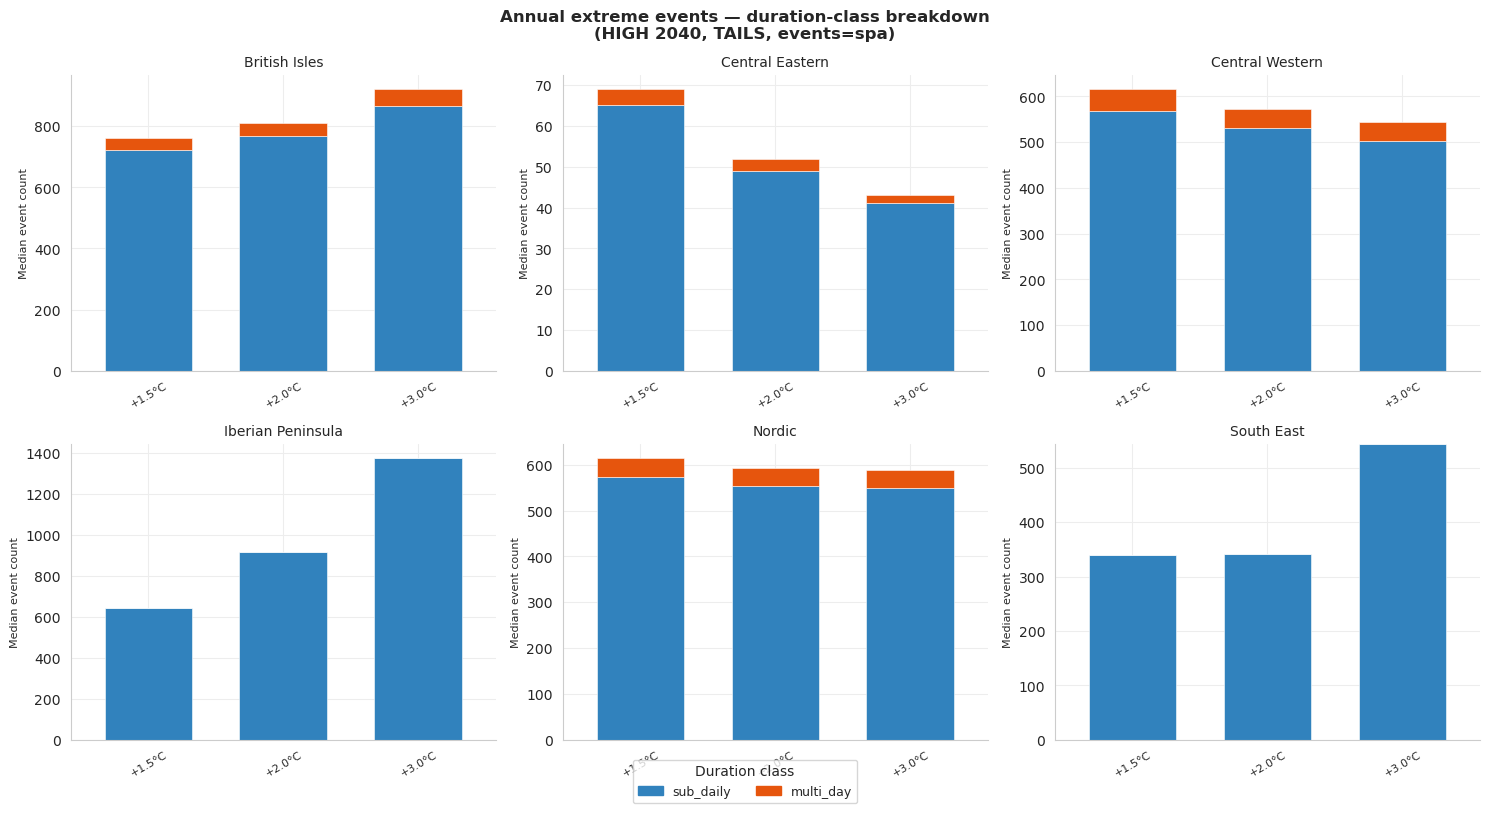

In [13]:
period_names = list(period_defs.keys())

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=False)
fig.suptitle(
    f"Annual extreme events — duration-class breakdown\n"
    f"({supply_scenario} {supply_year}, {THRESHOLD_METHOD}, events={EVENT_DETECTION_METHOD})",
    fontsize=12, fontweight="bold",
)

for ax, zone in zip(axes.flat, zones):
    df_z = df_annual[df_annual["zone"] == str(zone)]
    # ensemble median n_events per (period, duration_class)
    pivot = (
        df_z.groupby(["period", "duration_class"])["n_events"]
        .median()
        .unstack("duration_class")
        .reindex(columns=DURATION_CLASS_ORDER, fill_value=0)
        .reindex(period_names, fill_value=0)
    )
    pivot.plot(
        kind="bar", stacked=True, ax=ax,
        color=[duration_palette[dc] for dc in DURATION_CLASS_ORDER],
        legend=False, width=0.65, edgecolor="white", linewidth=0.4,
    )
    ax.set_title(str(zone).replace("_", " "), fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Median event count", fontsize=8)
    ax.tick_params(axis="x", labelsize=8, rotation=30)
    sns.despine(ax=ax)

handles = [plt.Rectangle((0, 0), 1, 1, color=duration_palette[dc]) for dc in DURATION_CLASS_ORDER]
fig.legend(handles, DURATION_CLASS_ORDER, title="Duration class",
           loc="lower center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout()
plt.show()

## A2 — Frequency per year by duration class

One panel per zone; one violin per (period, duration class).

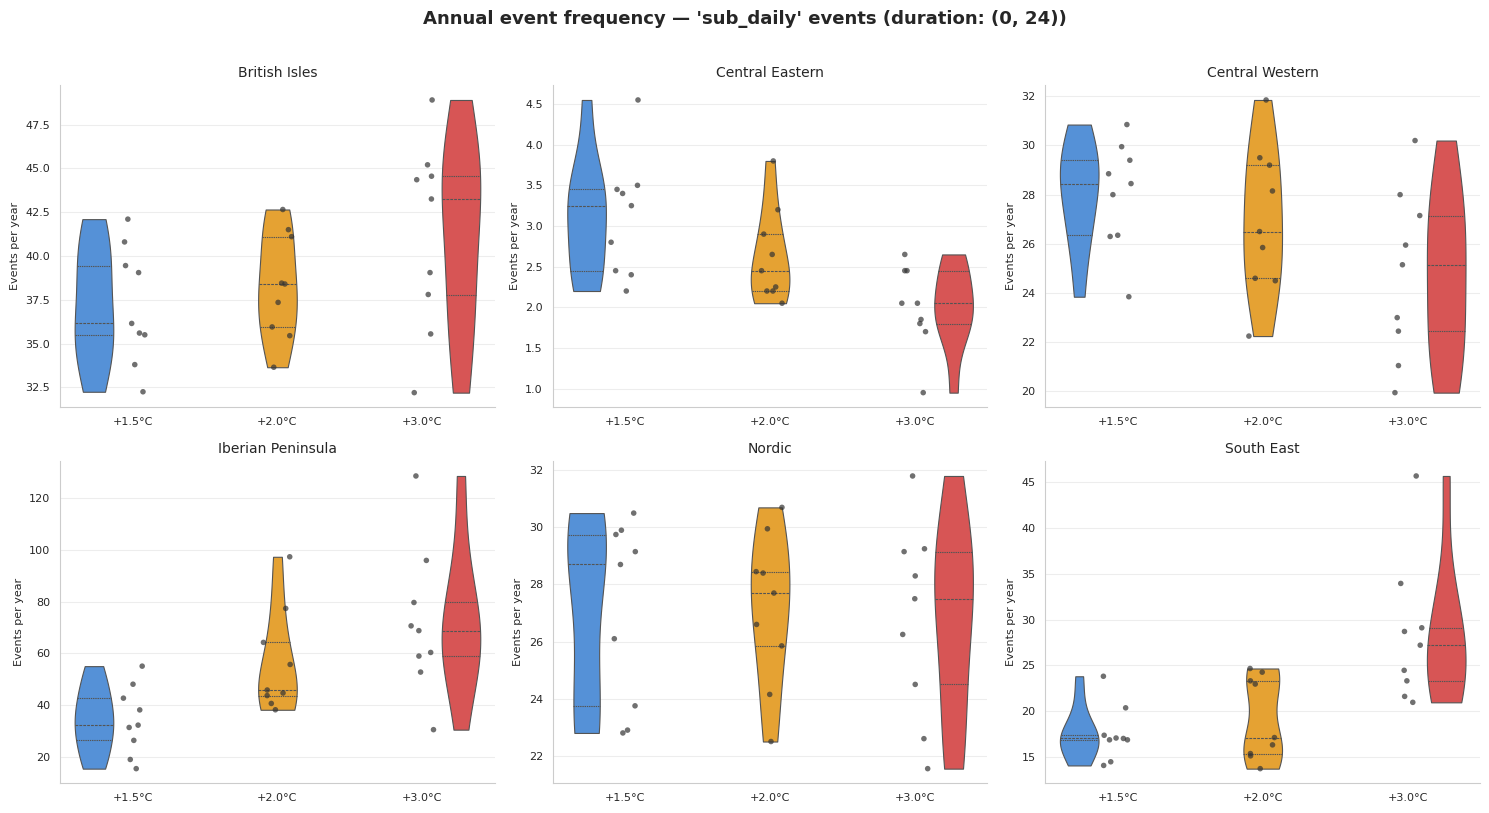

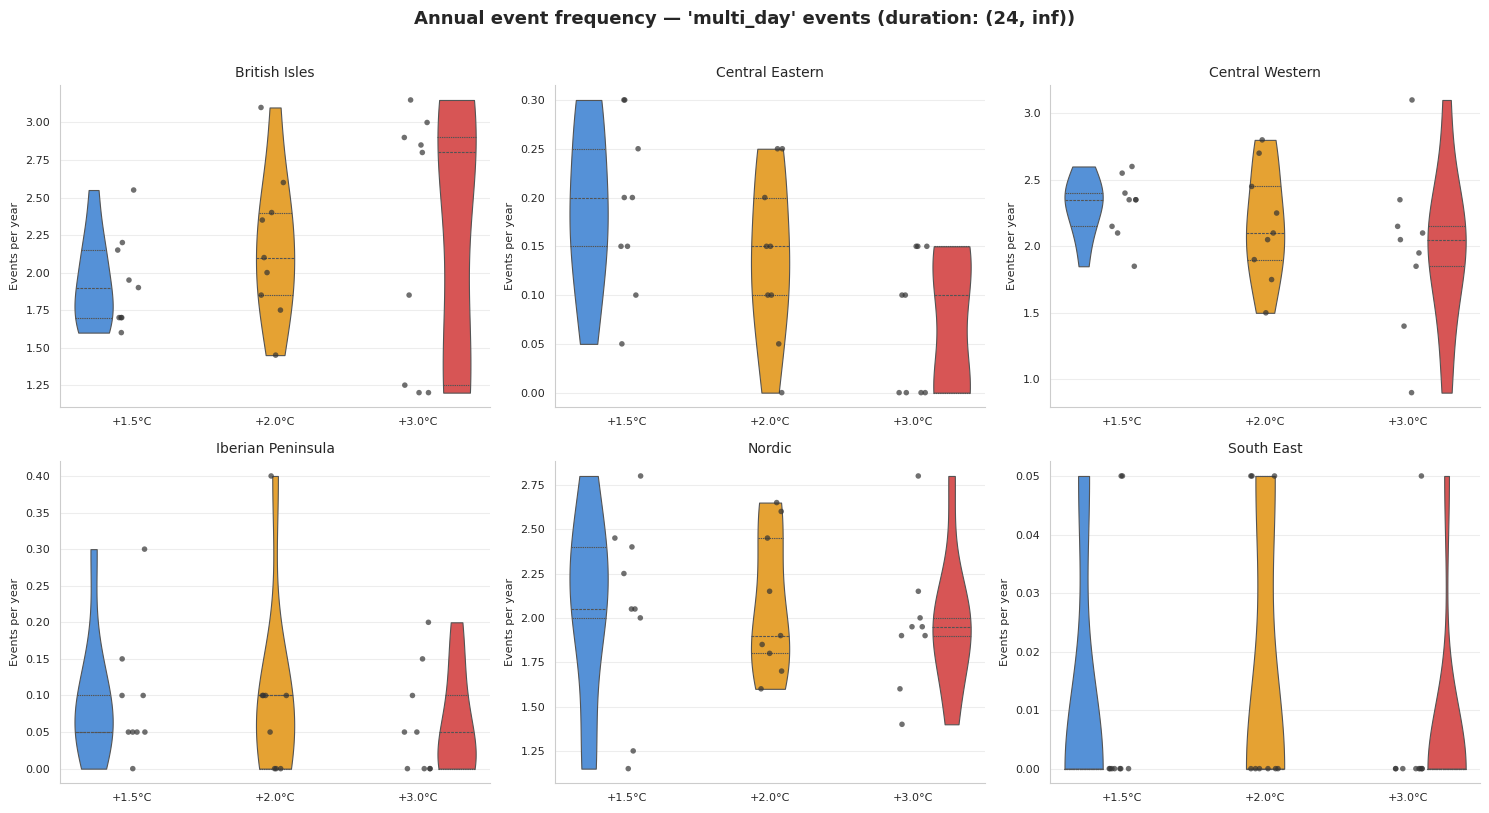

In [14]:
for dc in DURATION_CLASS_ORDER:
    df_dc = df_annual[df_annual["duration_class"] == dc].copy()
    if df_dc["n_events"].sum() == 0:
        print(f"  [skip {dc}: no events across all models/periods]")
        continue
    plot_violin_grid(
        df_dc,
        metric="freq_per_year",
        ylabel="Events per year",
        title=f"Annual event frequency — '{dc}' events (duration: {dict(list(DURATION_BINS.items()))[[*DURATION_BINS][DURATION_CLASS_ORDER.index(dc)]]})",
        period_defs=period_defs,
        zones=zones,
        period_colors=period_colors,
    )

## A3 — Energy severity by duration class

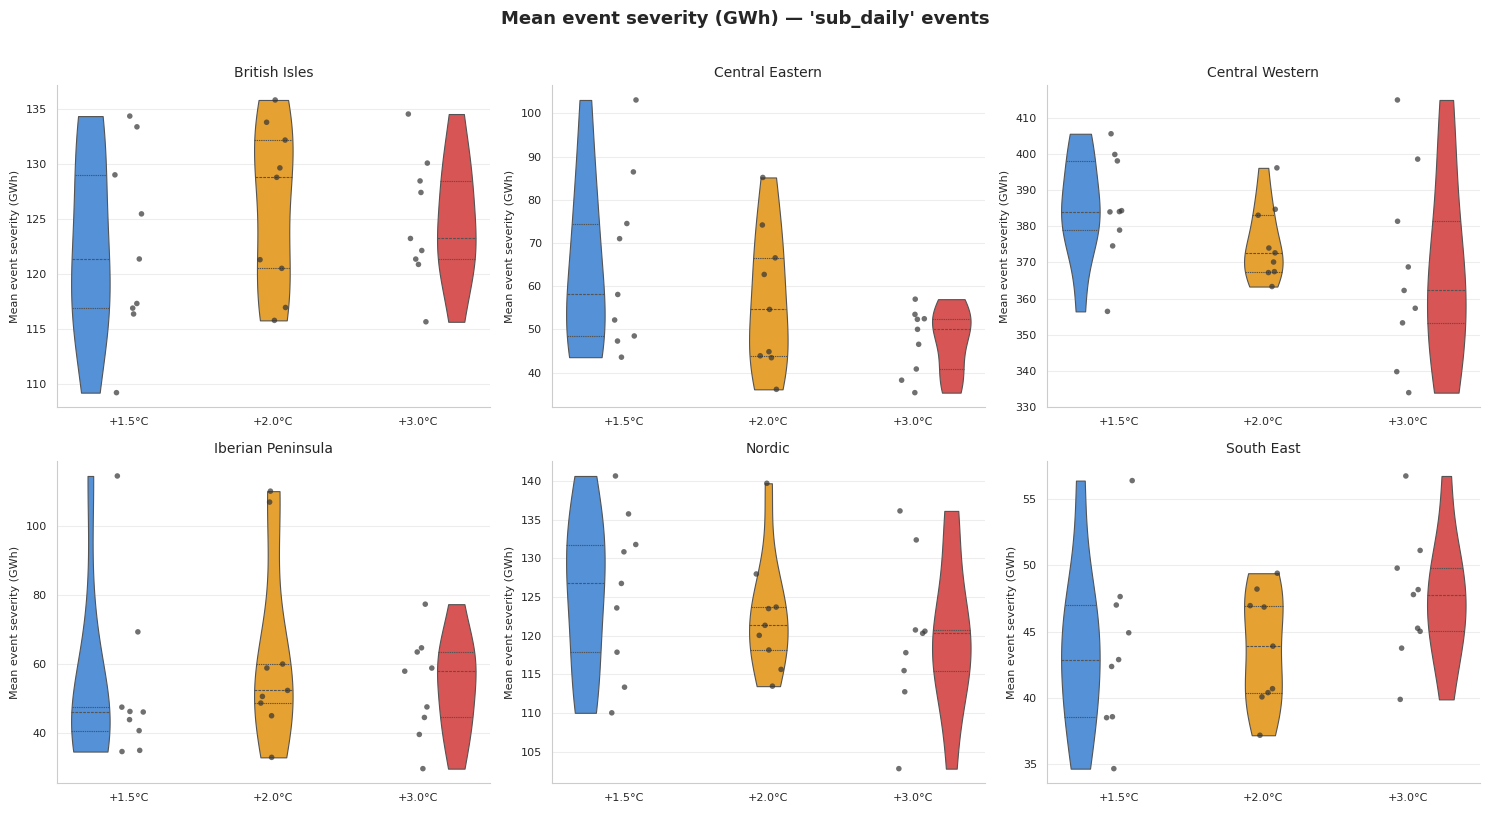

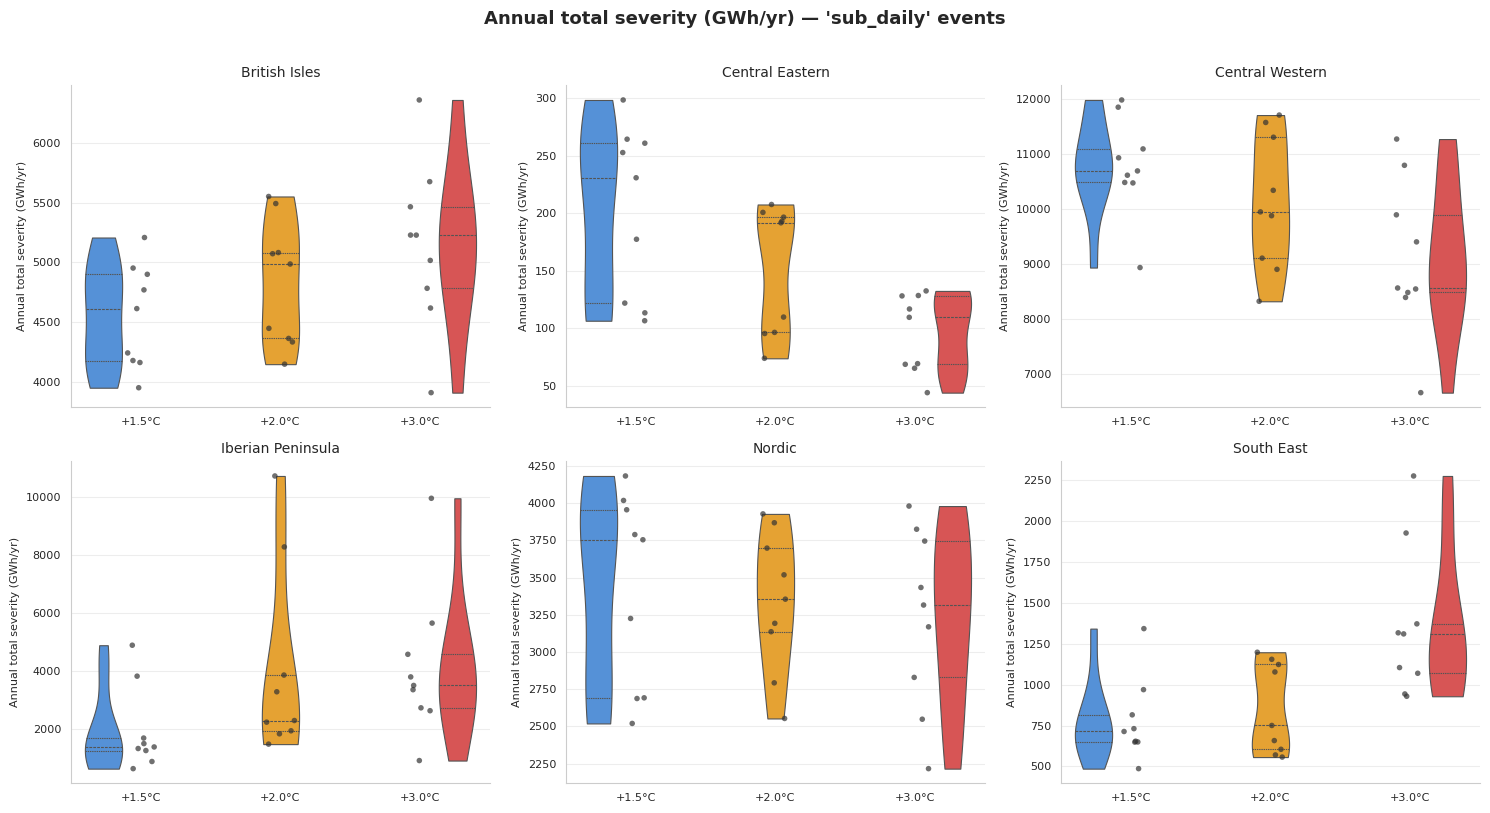

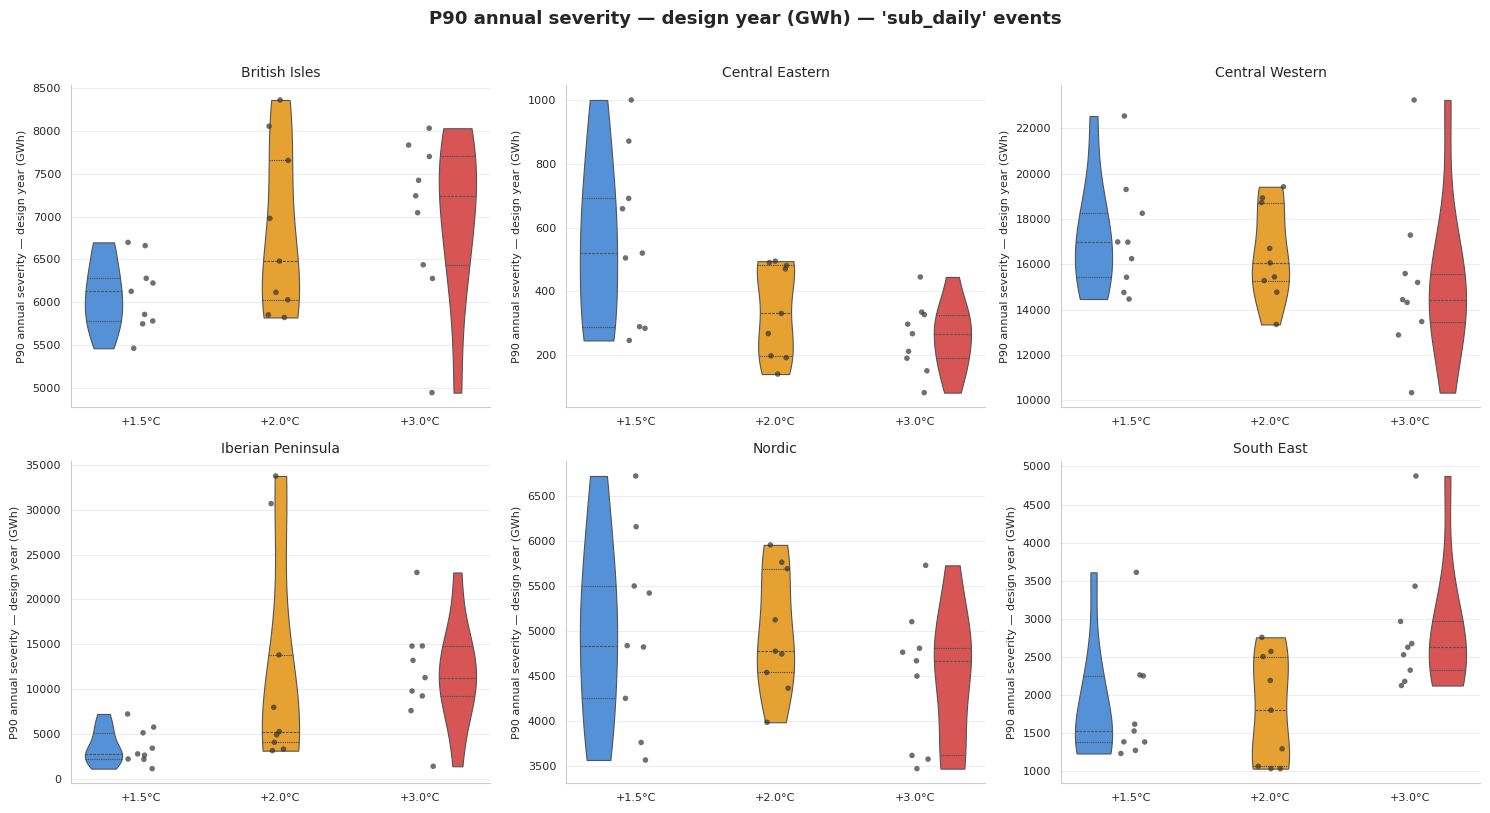

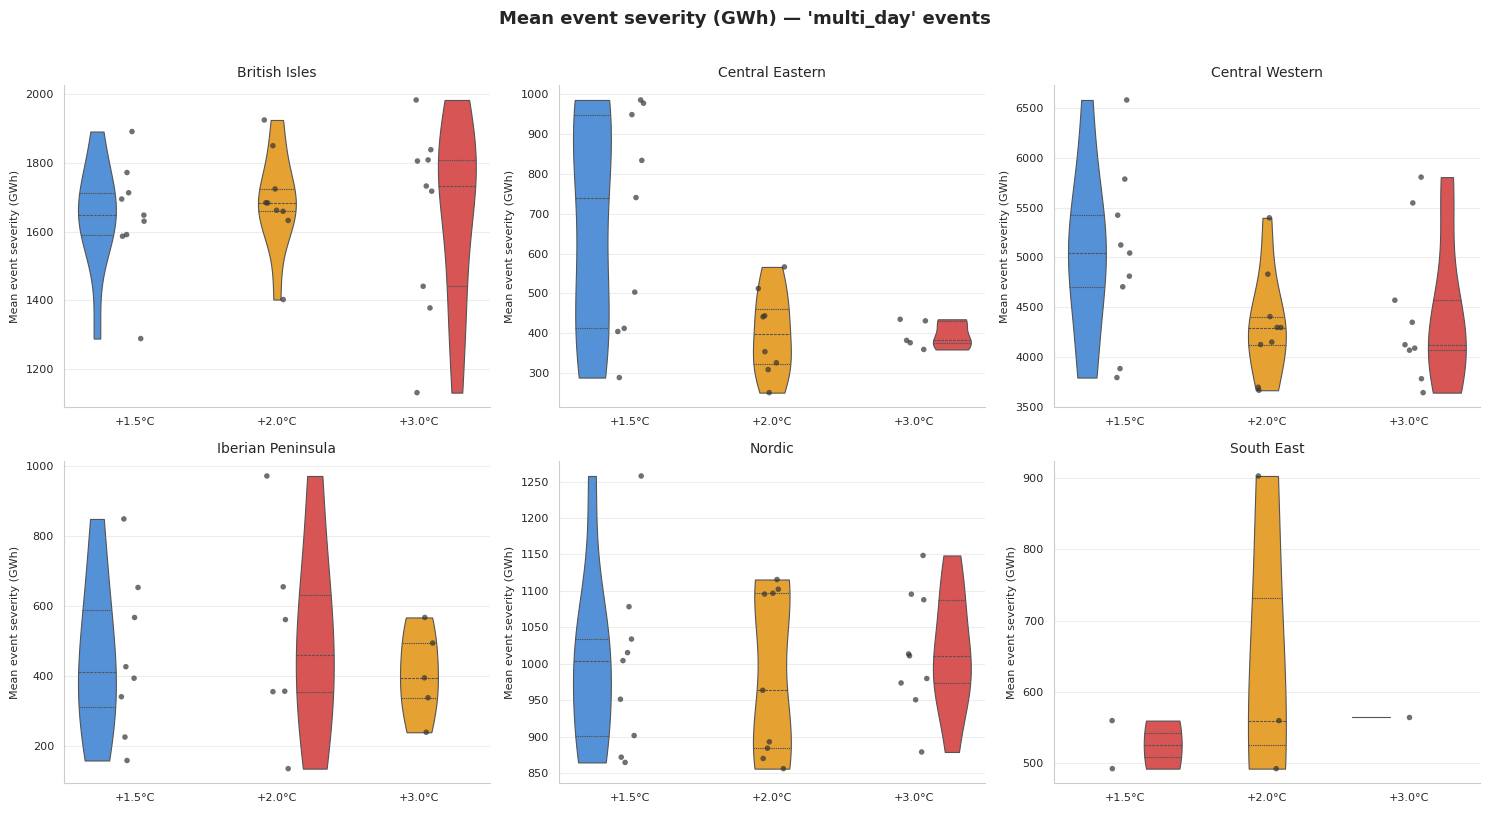

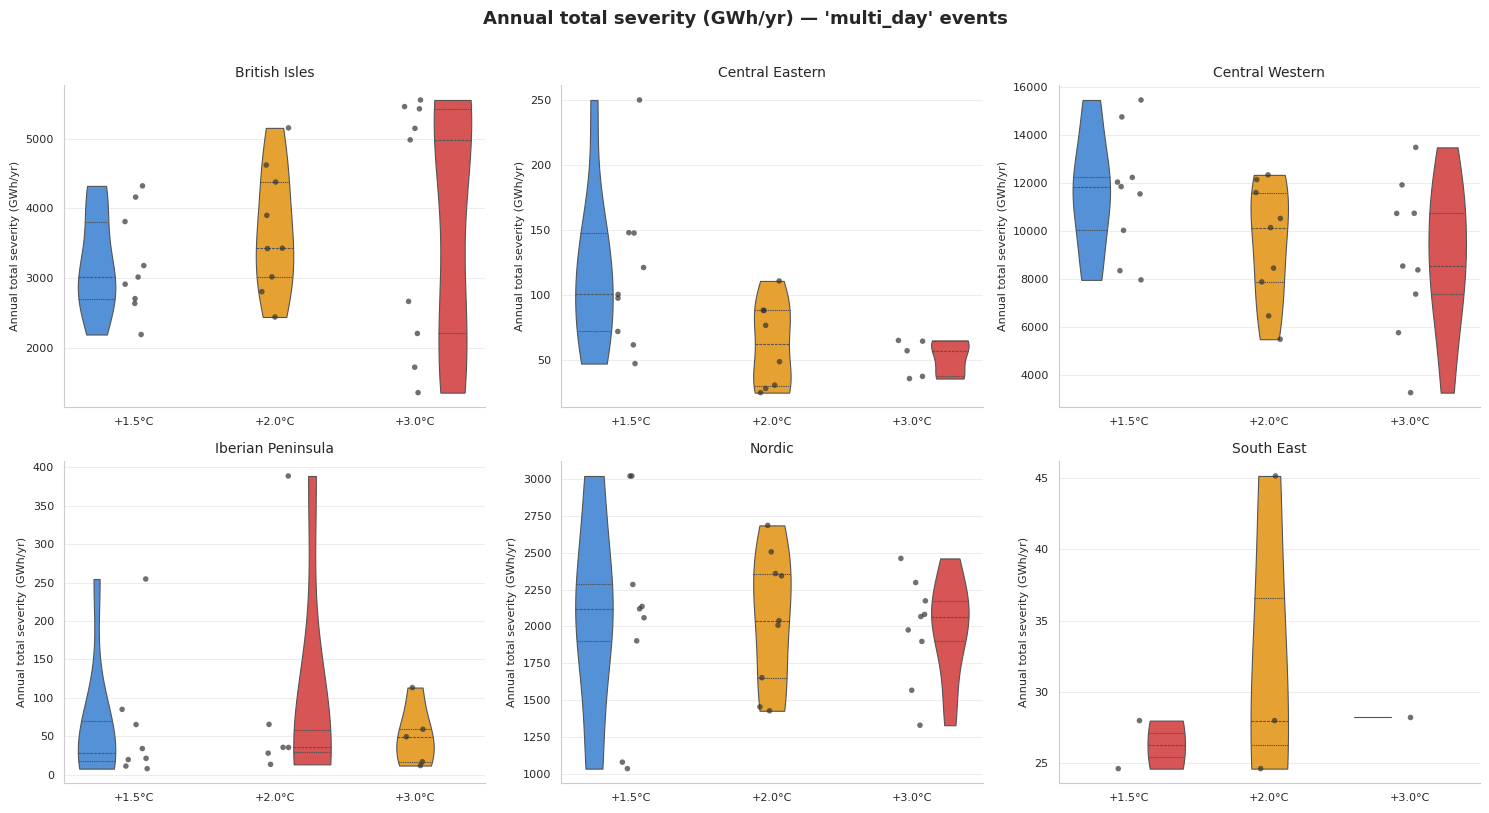

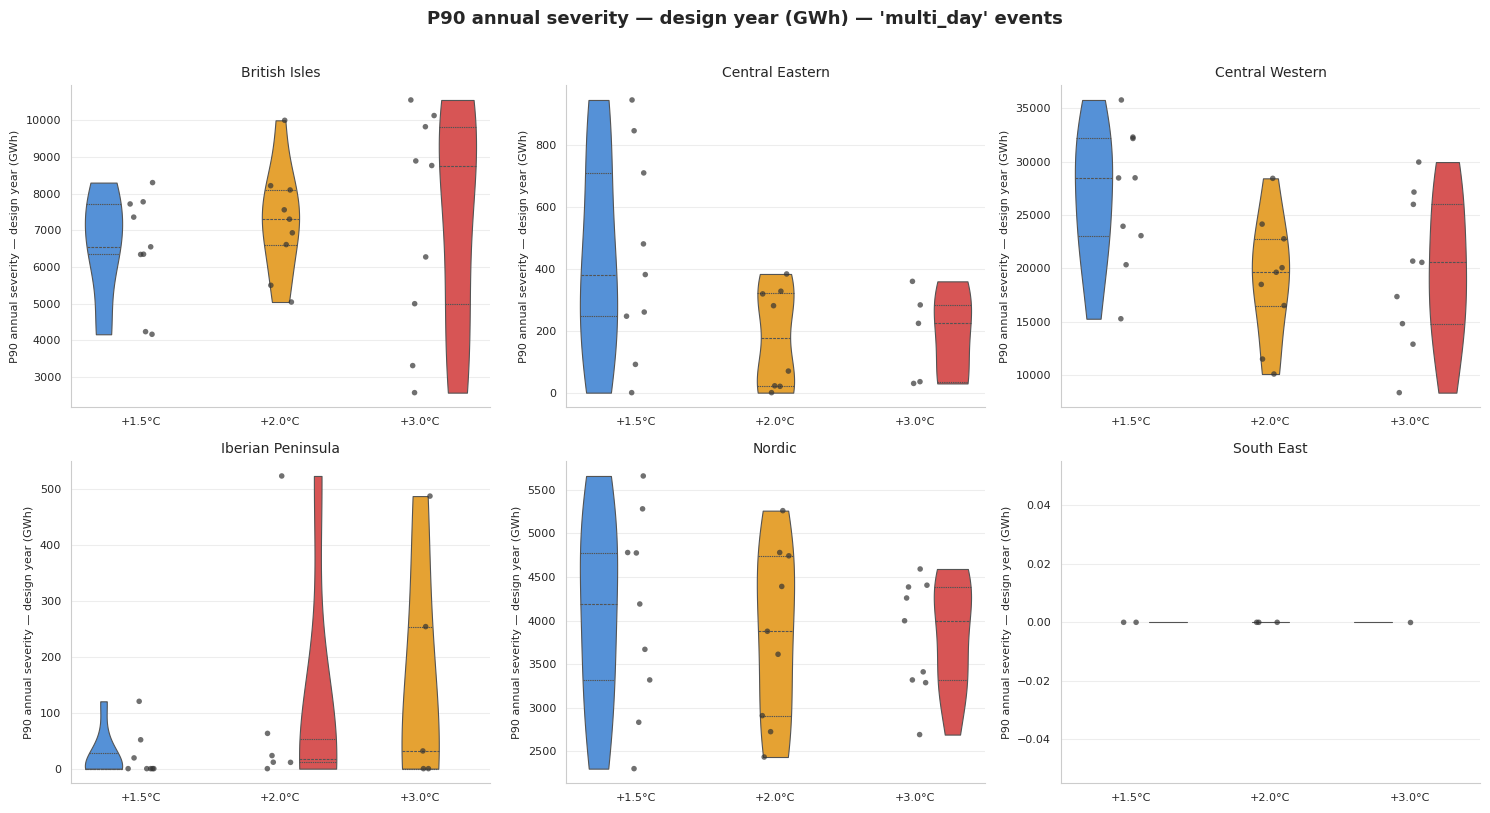

In [15]:
for dc in DURATION_CLASS_ORDER:
    df_dc = df_annual[(df_annual["duration_class"] == dc) & (df_annual["n_events"] > 0)].copy()
    if df_dc.empty:
        continue
    for metric, label in [
        ("avg_severity_gwh",          "Mean event severity (GWh)"),
        ("total_annual_severity_gwh", "Annual total severity (GWh/yr)"),
        ("p90_annual_severity_gwh",   "P90 annual severity — design year (GWh)"),
    ]:
        plot_violin_grid(
            df_dc,
            metric=metric,
            ylabel=label,
            title=f"{label} — '{dc}' events",
            period_defs=period_defs,
            zones=zones,
            period_colors=period_colors,
        )

## A4 — Driver attribution by duration class

Stacked bar charts of ensemble-median attribution shares, one figure per duration class.  
This reveals whether short events are more demand-driven while prolonged events are
generation-scarcity driven (or vice versa).


── Attribution: 'sub_daily' events


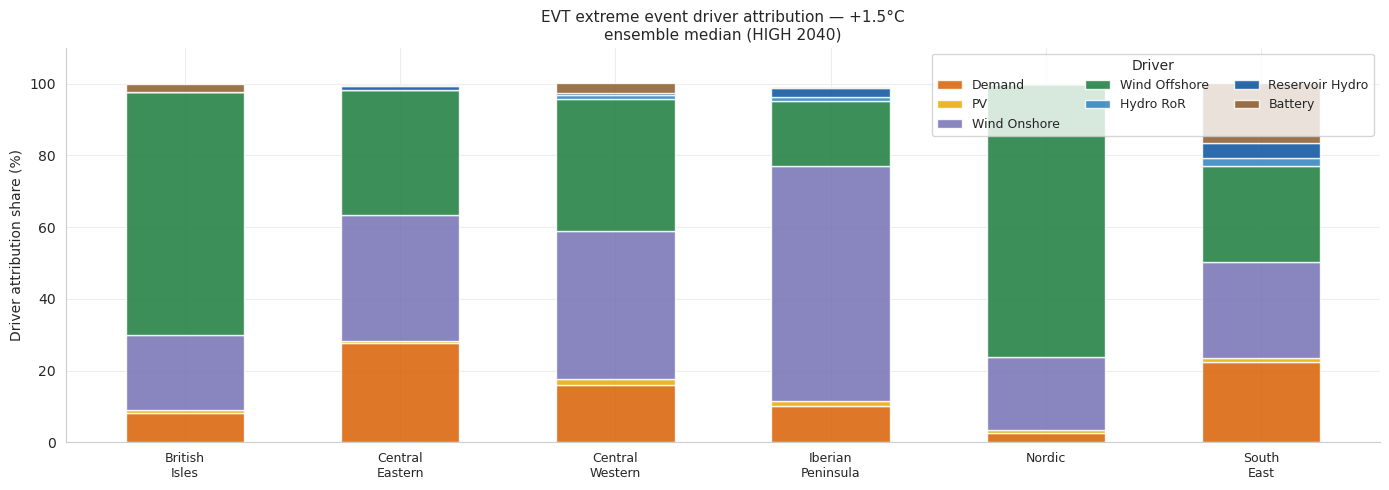

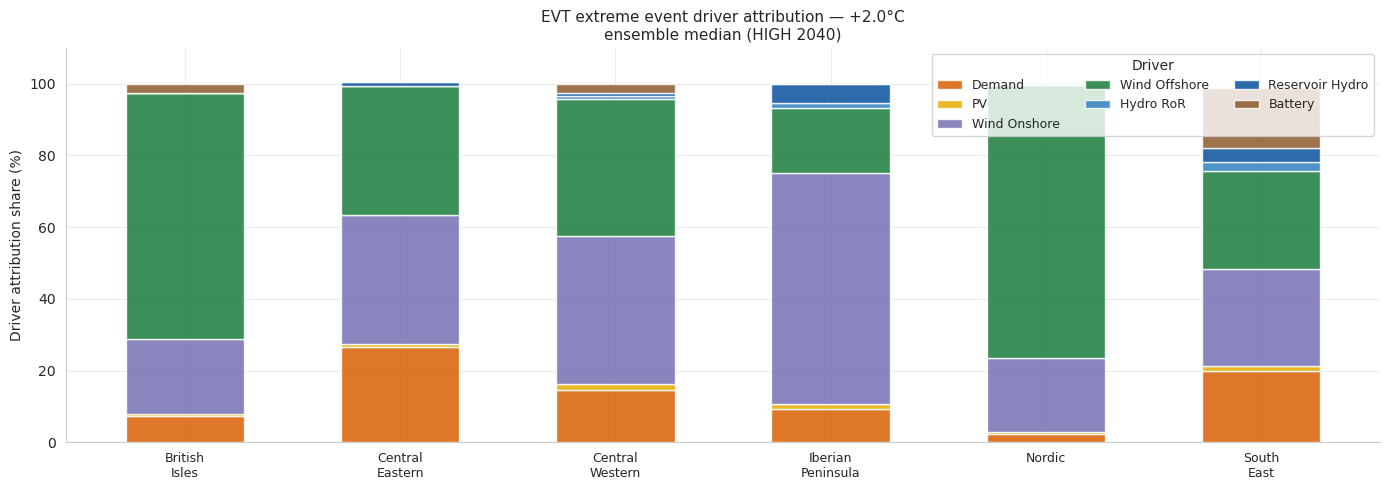

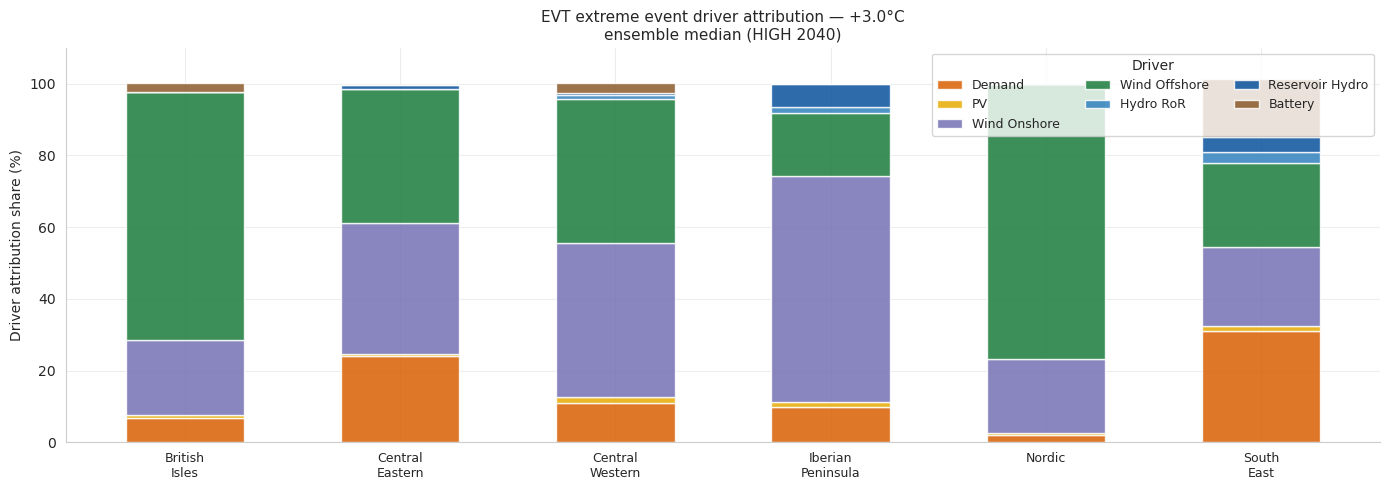


── Attribution: 'multi_day' events


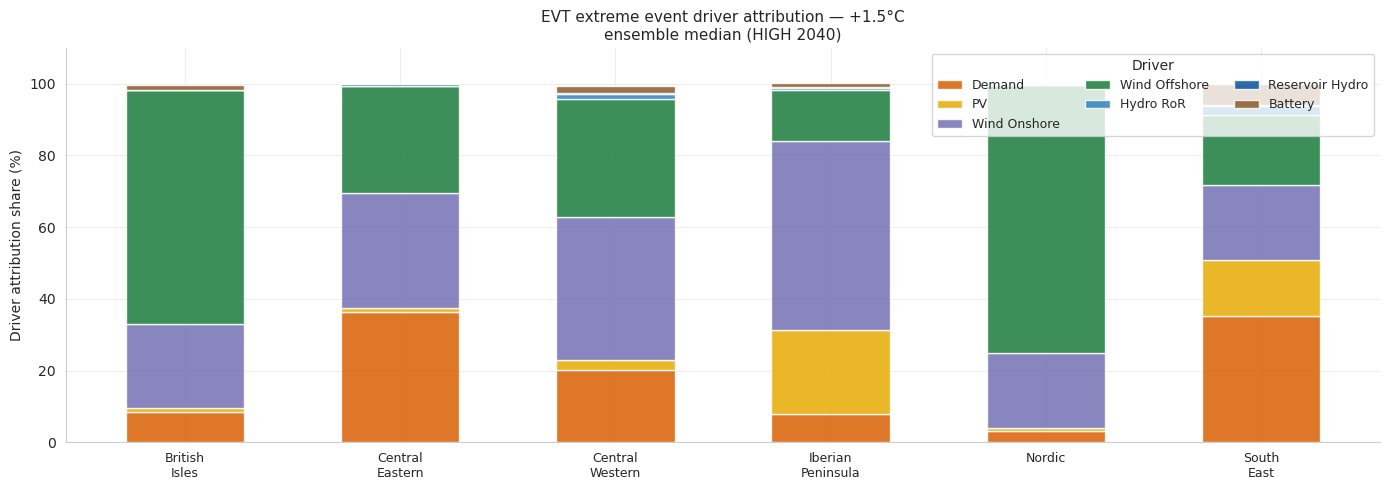

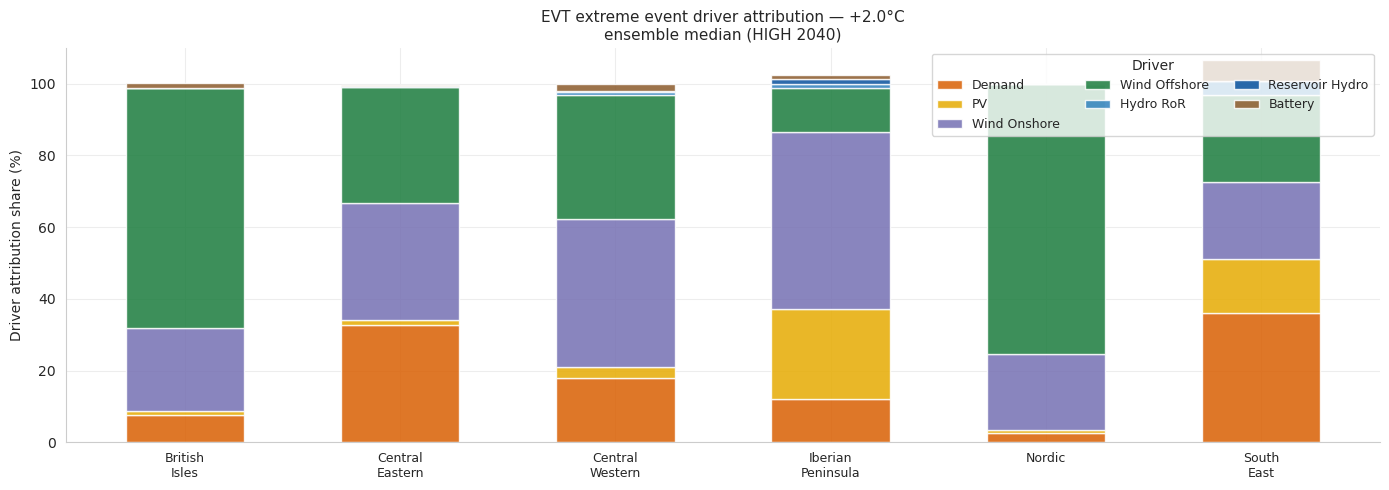

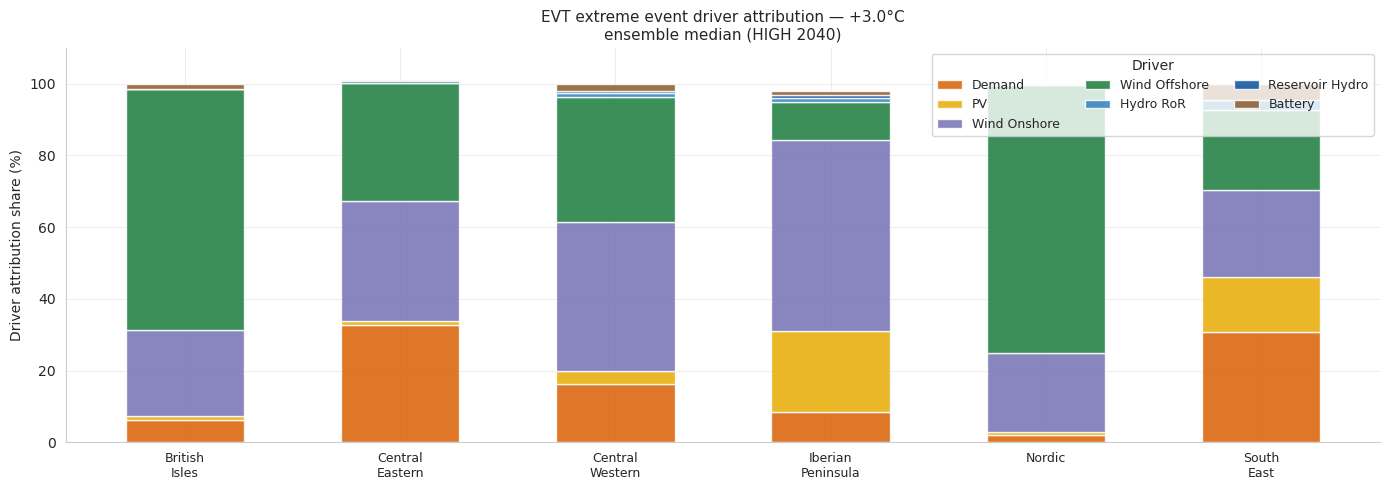

In [16]:
for dc in DURATION_CLASS_ORDER:
    df_dc = df_annual[(df_annual["duration_class"] == dc) & (df_annual["n_events"] > 0)].copy()
    if df_dc.empty:
        print(f"  [skip {dc}: no events]")
        continue
    print(f"\n── Attribution: '{dc}' events")
    plot_attribution_stacked_bars(
        df_dc,
        zones=zones,
        period_defs=period_defs,
        driver_cols=driver_cols,
        driver_palette=driver_palette,
        supply_scenario=supply_scenario,
        supply_year=supply_year,
    )

## A5 — Driver anomaly distributions (annual)

Signed mean anomaly per event (GWh) for each component.  
**Demand anomaly positive** (excess demand above baseline); **generation and flexibility anomalies negative** (shortfall / under-dispatch).

One figure set per duration class; within each set:
- *Per-period* figures: all components side by side, coloured by component, individual model dots shown.
- *Period-comparison* figure: grouped boxplots per component, coloured by warming level.


── Driver anomaly distributions (annual): 'sub_daily' events


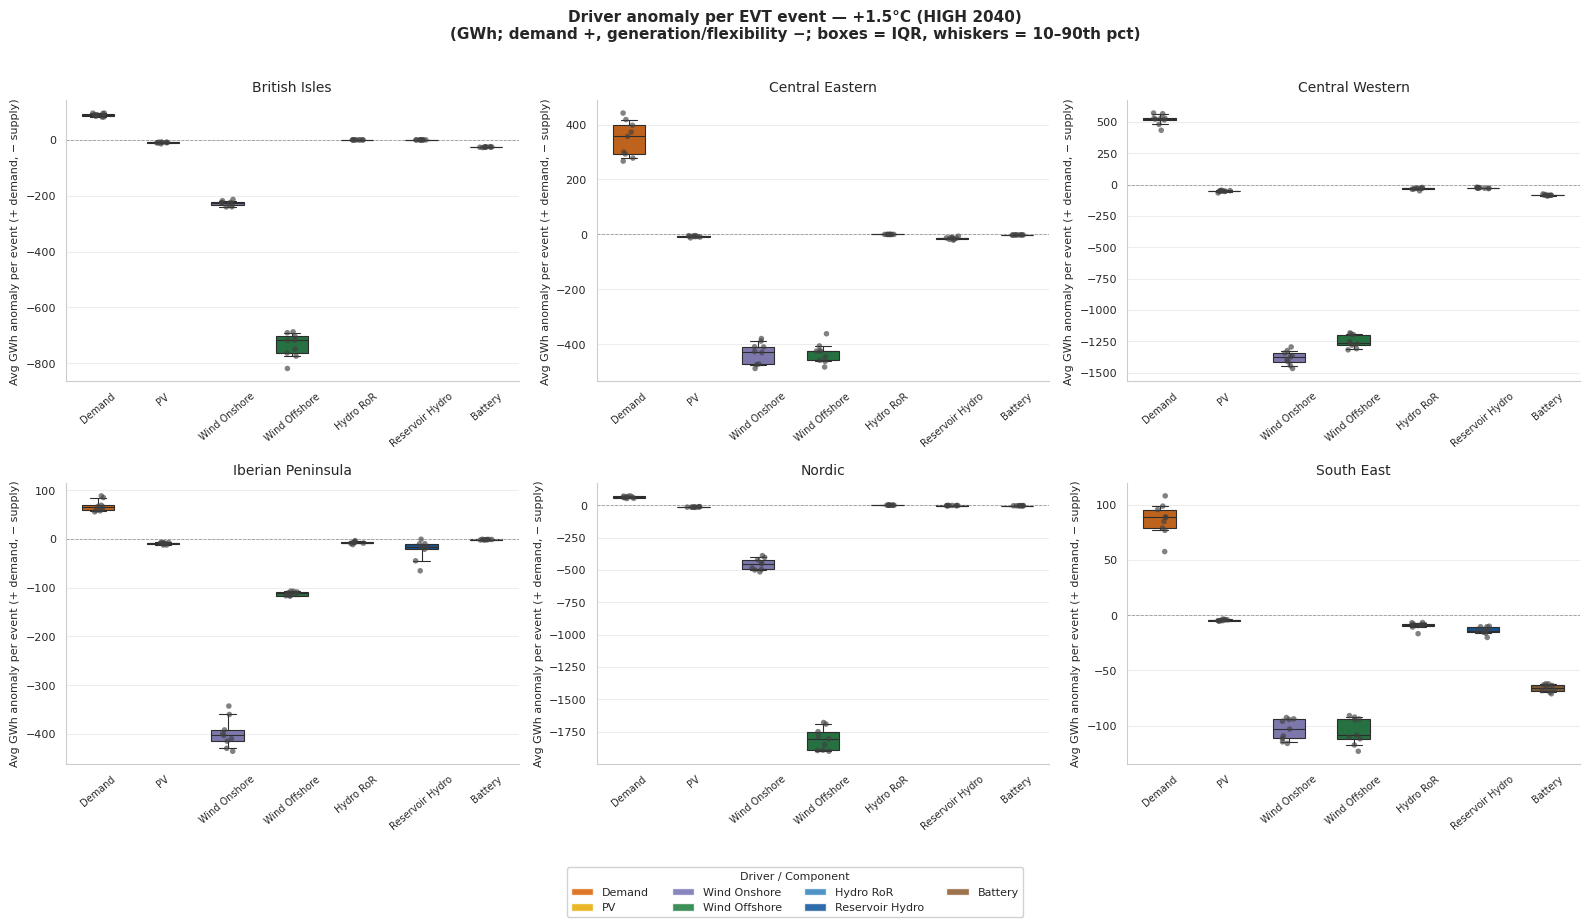

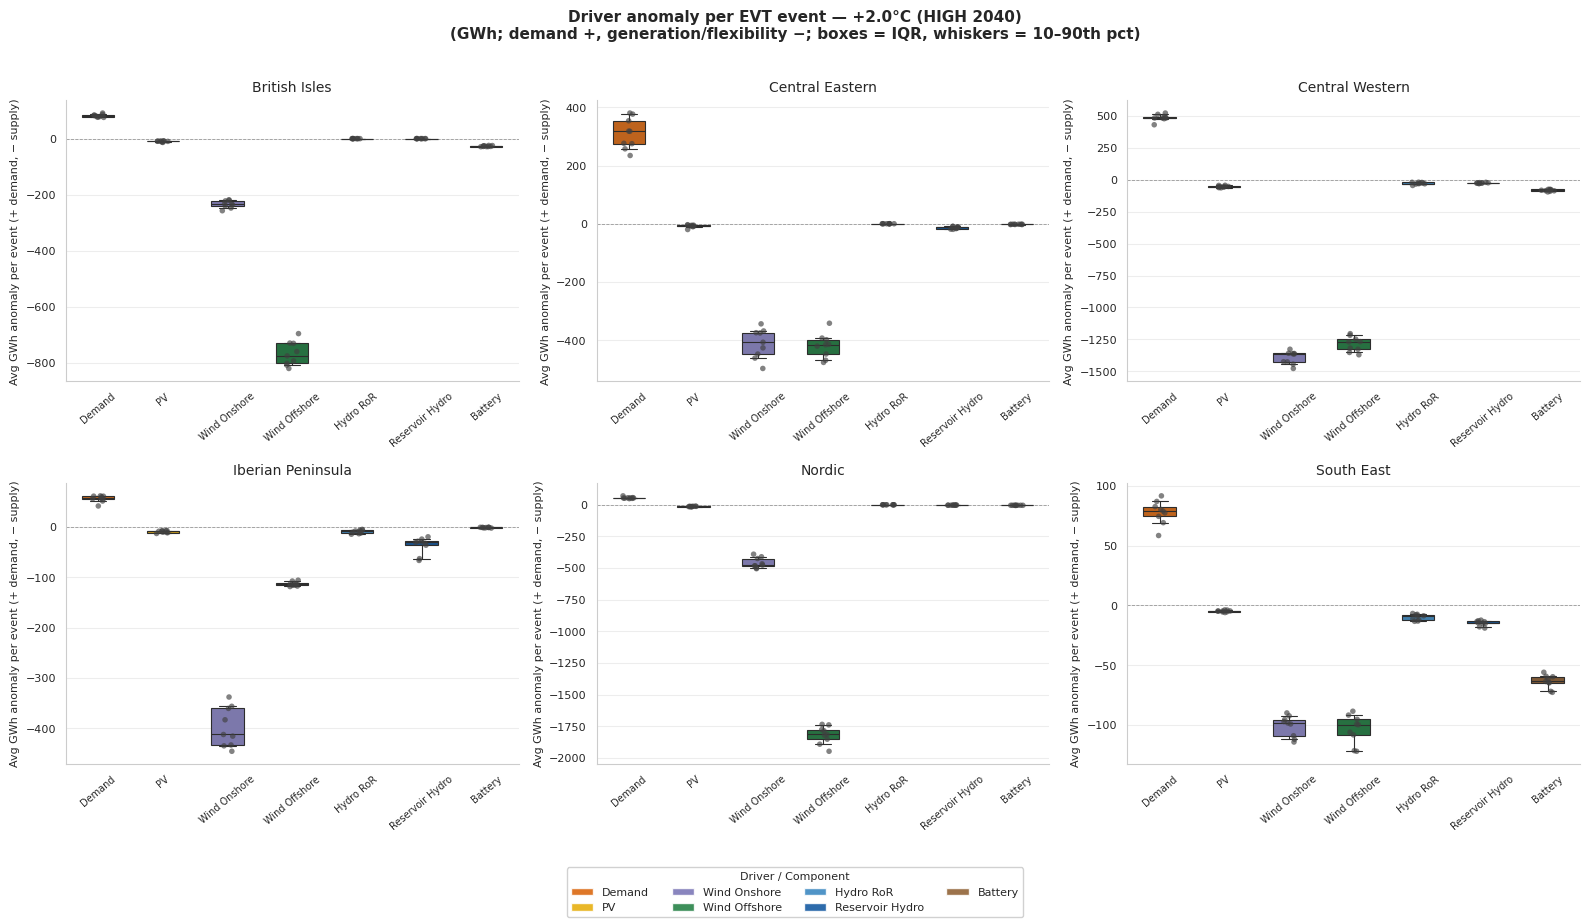

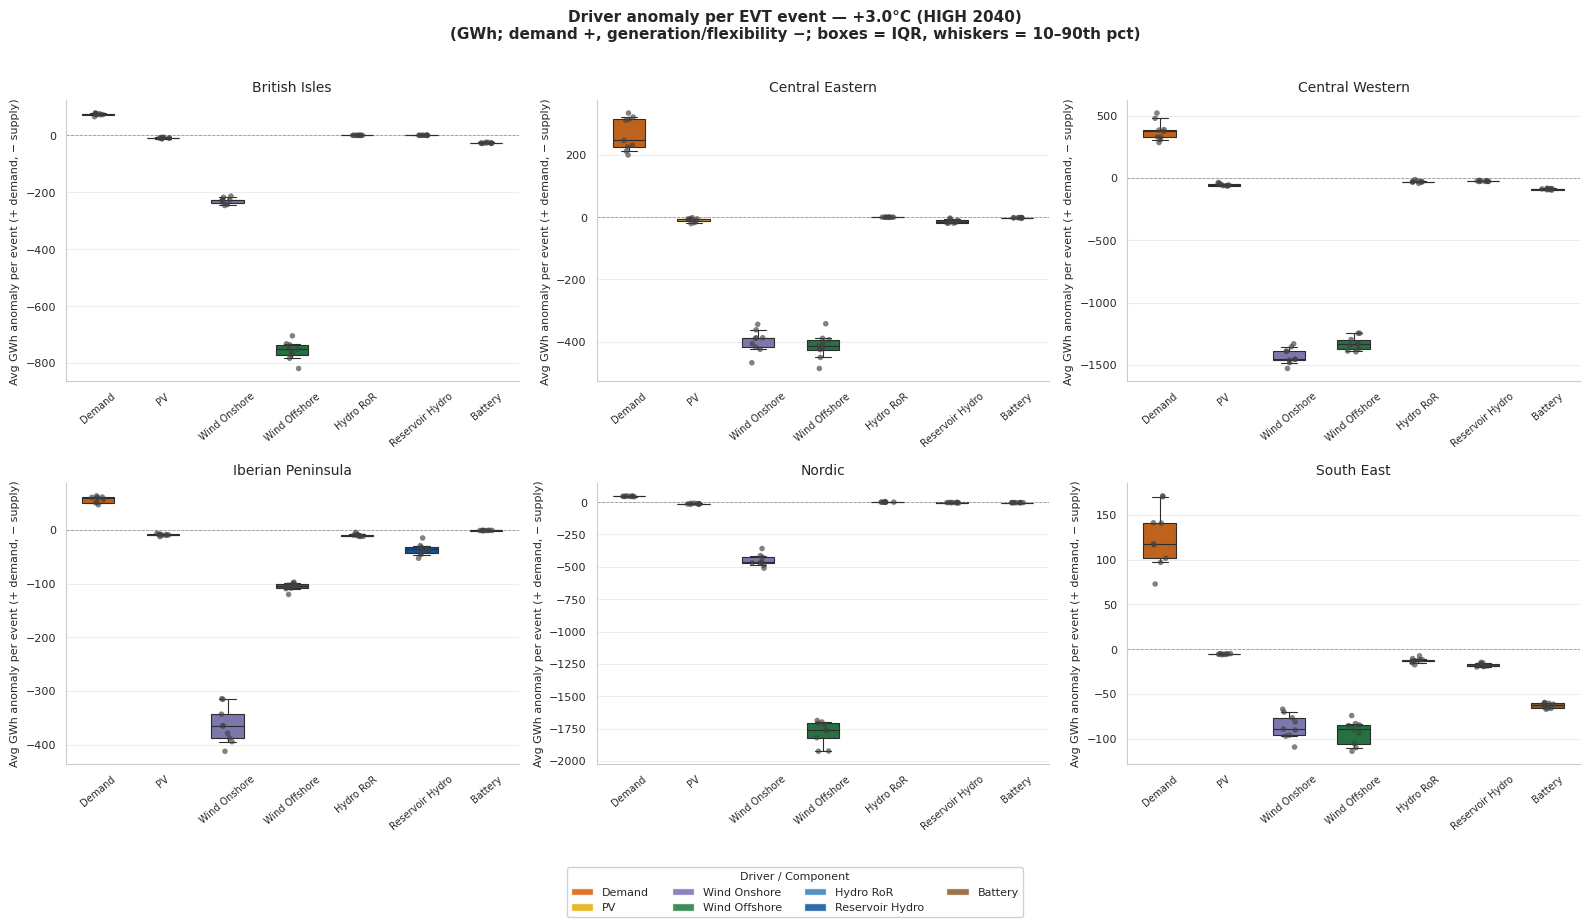

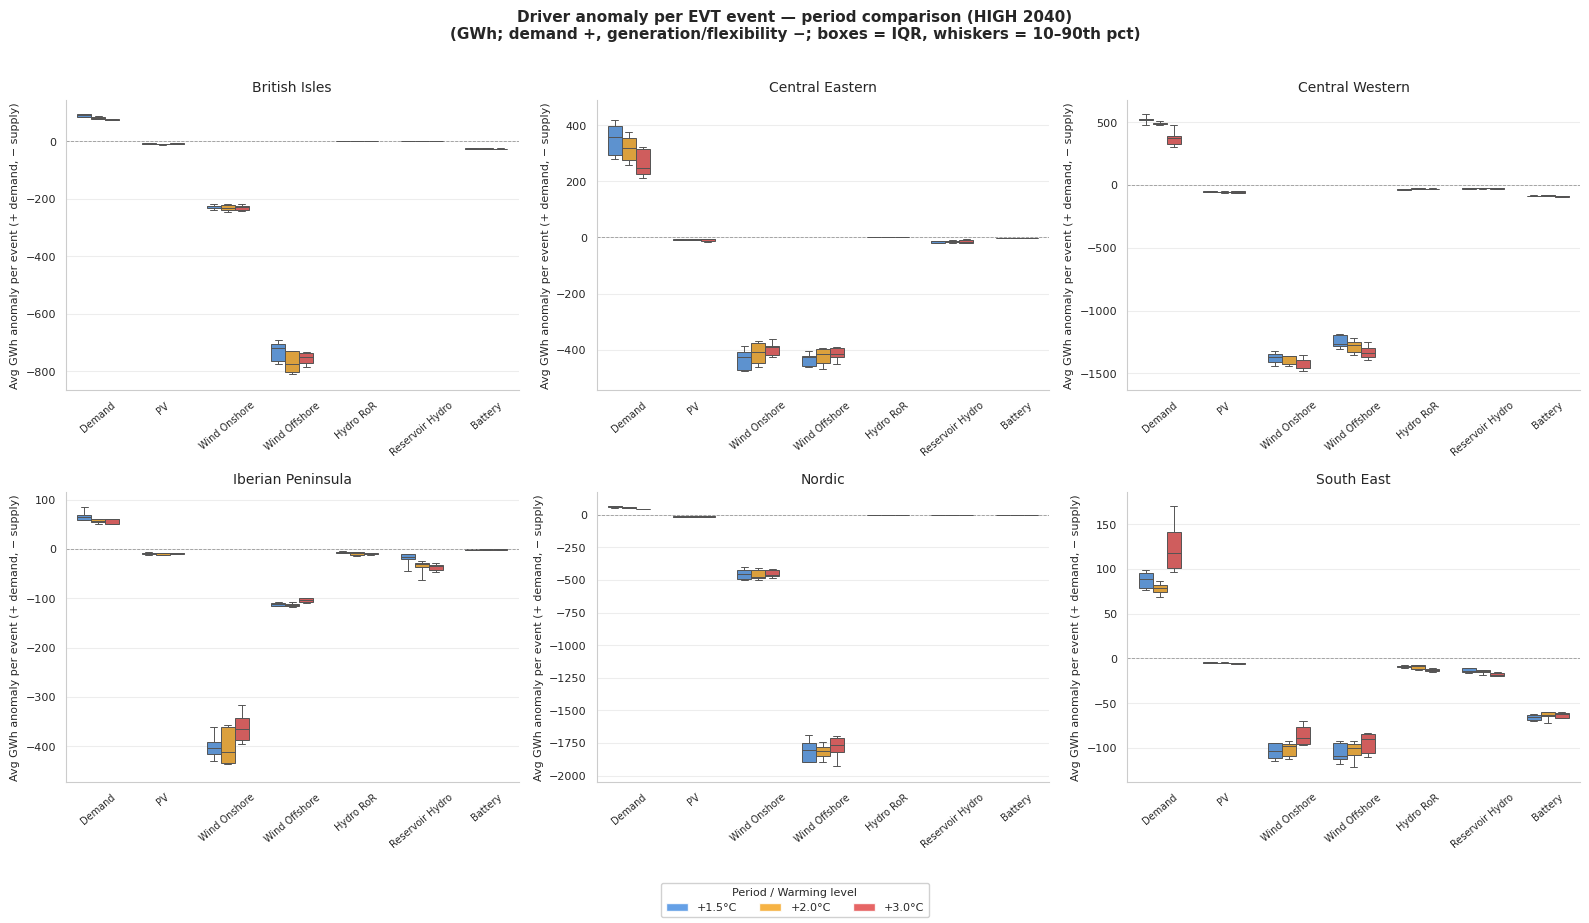


── Driver anomaly distributions (annual): 'multi_day' events


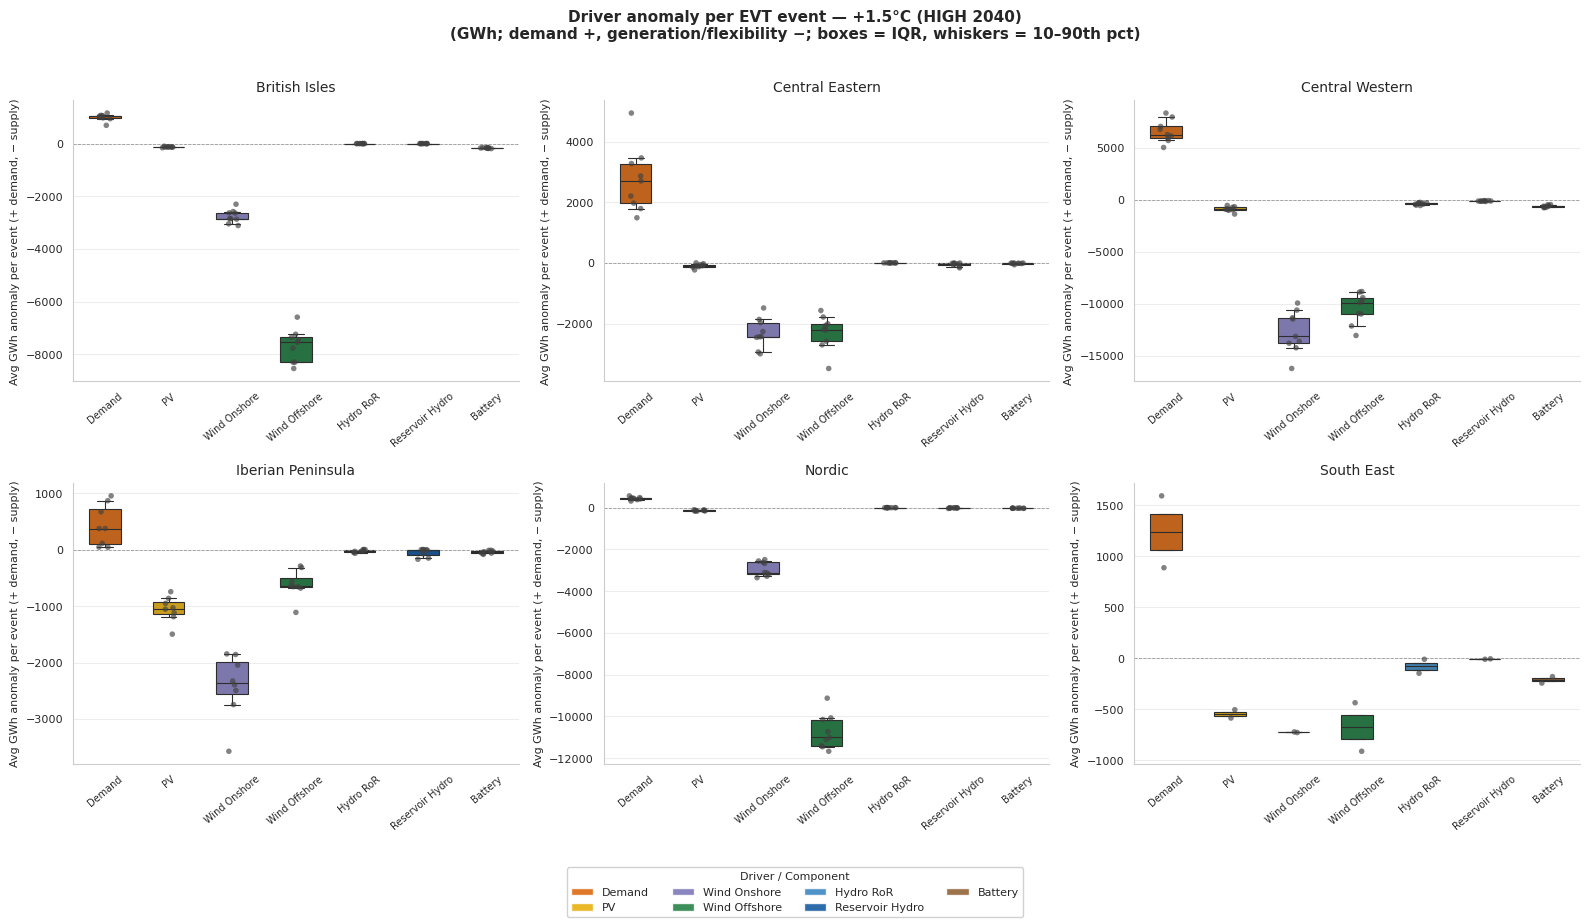

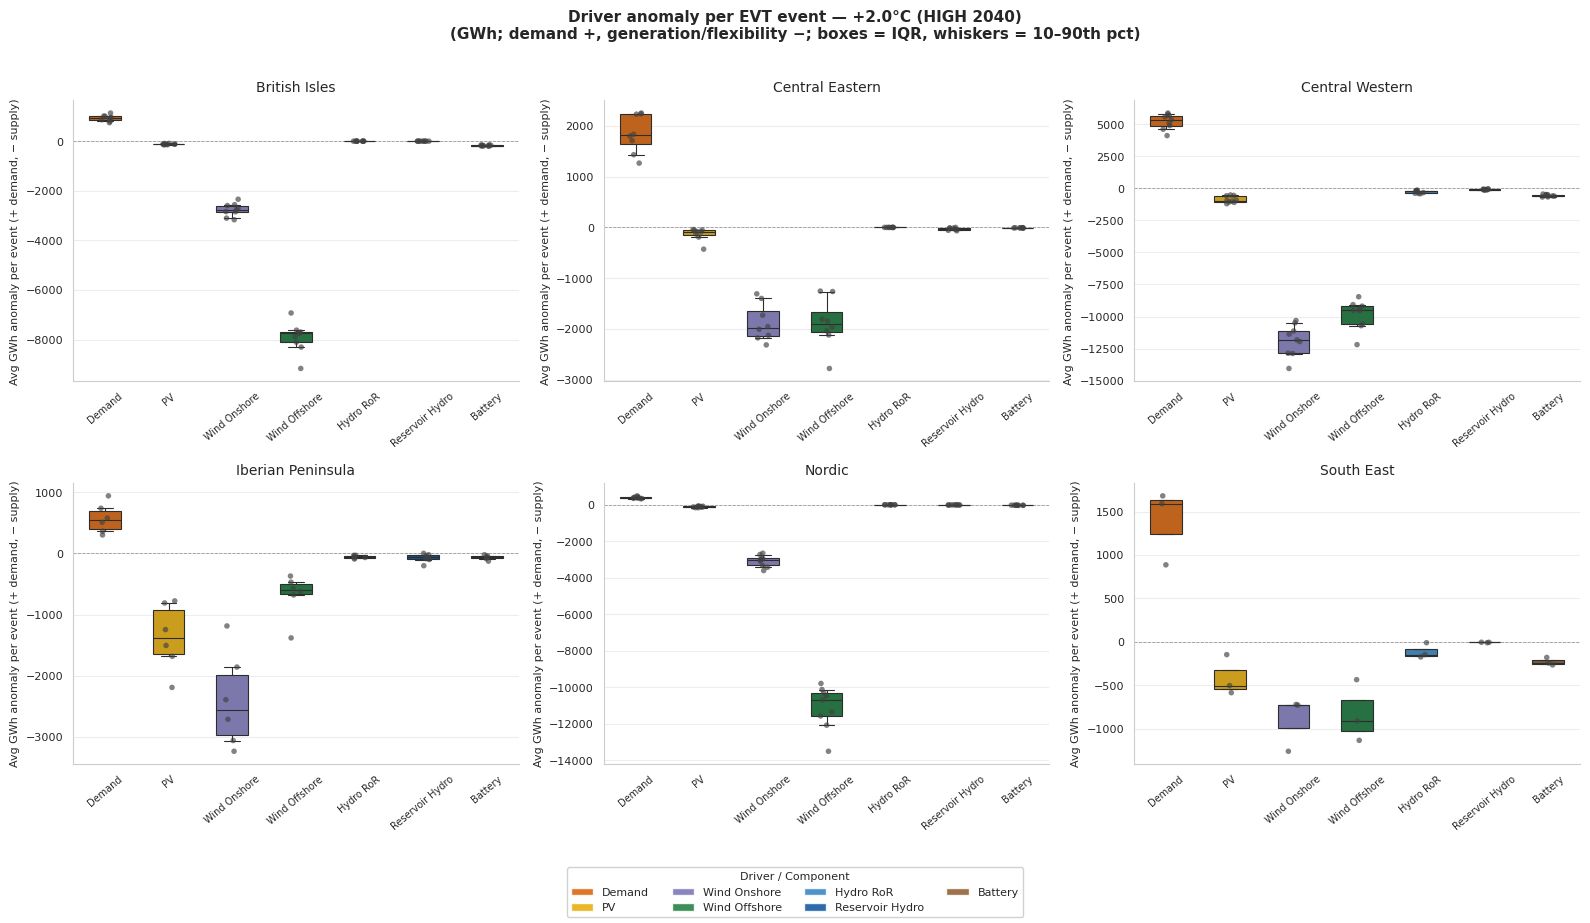

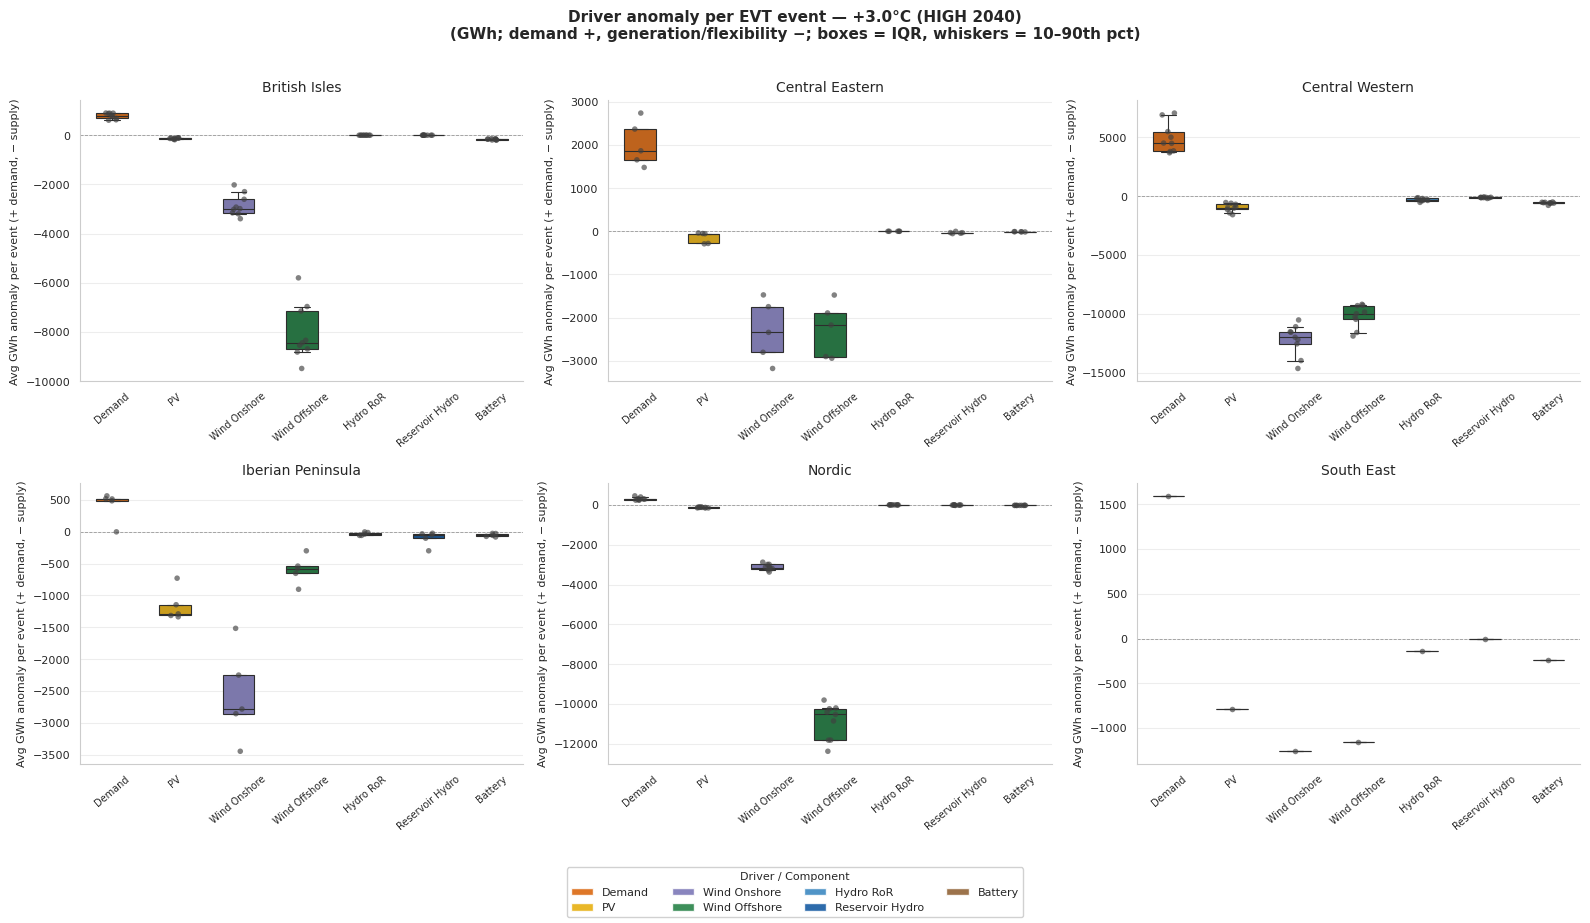

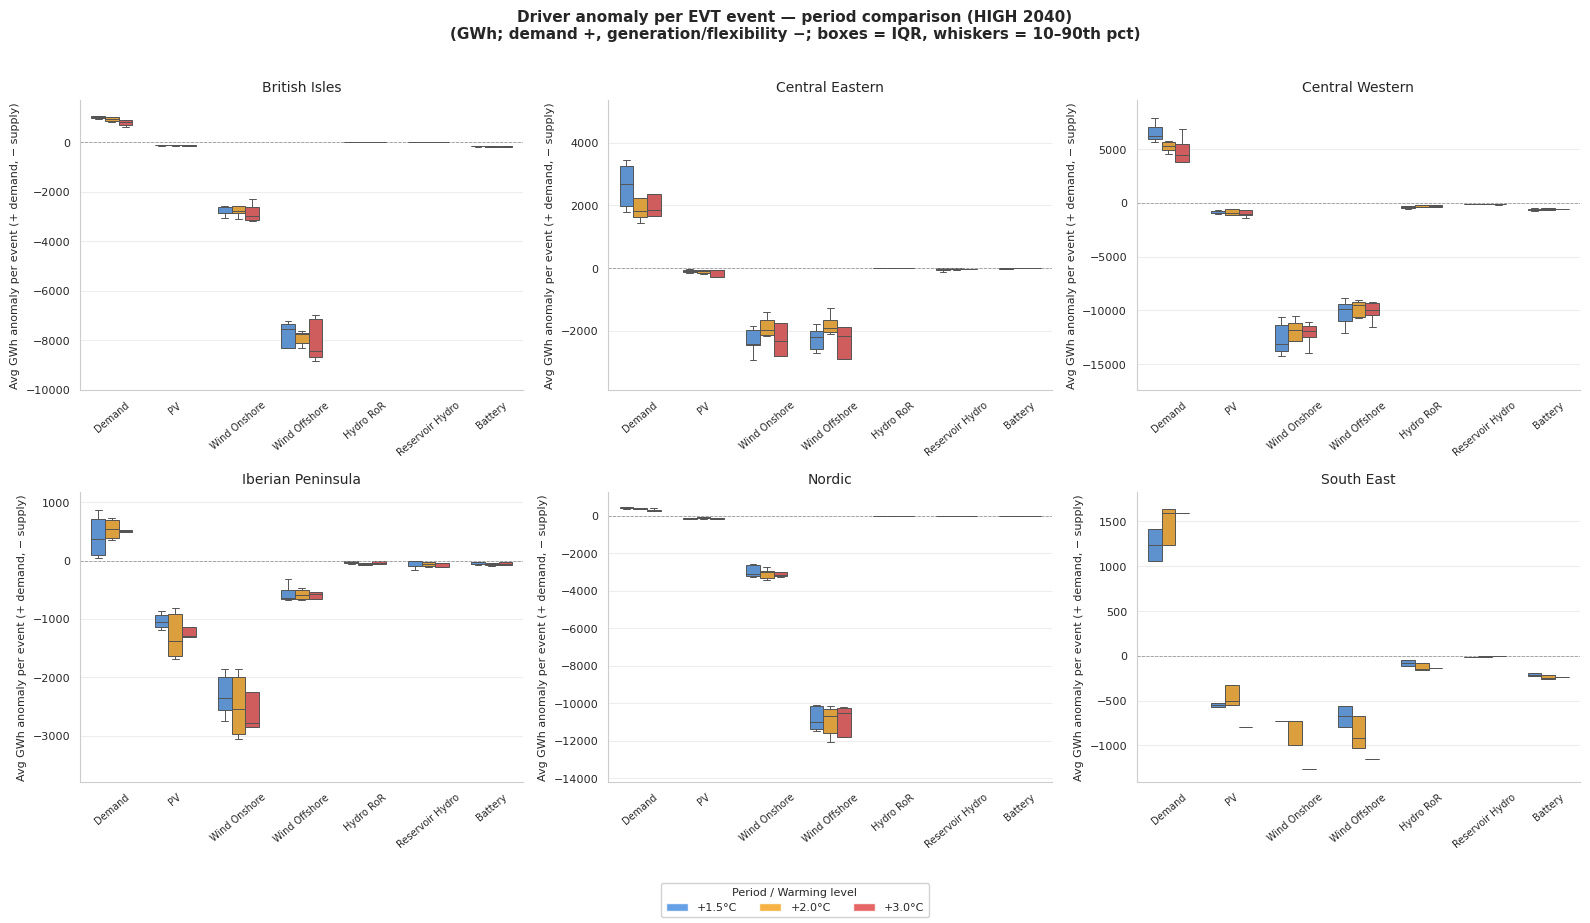

In [17]:
for dc in DURATION_CLASS_ORDER:
    df_dc = df_annual[(df_annual["duration_class"] == dc) & (df_annual["n_events"] > 0)].copy()
    if df_dc.empty:
        print(f"  [skip {dc}: no events]")
        continue
    print(f"\n── Driver anomaly distributions (annual): '{dc}' events")
    plot_component_anomaly_distributions(
        df_dc,
        zones=zones,
        period_defs=period_defs,
        component_cols=anomaly_component_cols,
        component_palette=driver_palette,
        period_palette=period_colors,
        supply_scenario=supply_scenario,
        supply_year=supply_year,
    )

---
# Section B — Seasonal scale

Events detected on **season-specific thresholds** (DJF/MAM/JJA/SON independently),
then split by duration class.  Using season-specific thresholds removes the seasonal
mean from the exceedance criterion and isolates *anomalous* events within each season.

**Critical review insight:** the two duration classes separate along the main seasonal
axes of physical variability:

- **`sub_daily` + JJA** → photovoltaic droughts and heatwave demand peaks:
  high frequency, short duration, driven by cloudiness / temperature anomalies.
- **`multi_day` + DJF** → cold-spell + wind-drought coincidences:
  low frequency, very high severity per event, driven by anticyclonic blocking.
- **`sub_daily` + DJF** → morning demand ramps under low solar and battery-depleted
  conditions: frequency expected to *decrease* with warming (milder winters).
- **`multi_day` + JJA** → rare prolonged anticyclonic blocking in summer:
  few events but potentially catastrophic; ensemble agreement likely low.

**Key questions — seasonal scale:**
1. Does the DJF `multi_day` regime (cold-spell blocking) weaken or strengthen under RCP8.5?
2. Does JJA `sub_daily` frequency rise faster in Mediterranean zones (Iberian Peninsula,
   South East) than in northern zones?
3. Does warming shift the *season × duration* composition of total energy at risk (B4/B5)?
4. Where is the warming signal **not robust** (B1b stippling)?

In [31]:
df_seasonal = compute_seasonal_duration_stratified_metrics(
    _cache_rl,
    _cache_met,
    season_active_thresholds,
    period_defs,
    models,
    zones,
    season_order,
    season_months,
    method=EVENT_DETECTION_METHOD,
    duration_bins=DURATION_BINS,
)

# Column aliases for compatibility with plot_seasonal_* functions
df_seasonal["Period"]    = df_seasonal["period"]
df_seasonal["Frequency"] = df_seasonal["n_events"]

print(f"df_seasonal: {df_seasonal.shape[0]} rows × {df_seasonal.shape[1]} columns")
print(f"  duration classes: {df_seasonal['duration_class'].unique().tolist()}")
df_seasonal.groupby(["season", "duration_class", "period"])["n_events"].median().unstack("period").round(0)

df_seasonal: 1296 rows × 29 columns
  duration classes: ['sub_daily', 'multi_day']


period                 +1.5°C  +2.0°C  +3.0°C
season duration_class                        
DJF    multi_day          5.0     6.0     4.0
       sub_daily        152.0   156.0   138.0
JJA    multi_day          0.0     0.0     0.0
       sub_daily        160.0   173.0   230.0
MAM    multi_day          2.0     2.0     1.0
       sub_daily        140.0   177.0   172.0
SON    multi_day          3.0     2.0     2.0
       sub_daily        150.0   180.0   166.0

## B1 — Duration-class breakdown per season

Stacked bar chart: for each zone, what fraction of seasonal events fall in each duration class,
shown for each warming level.

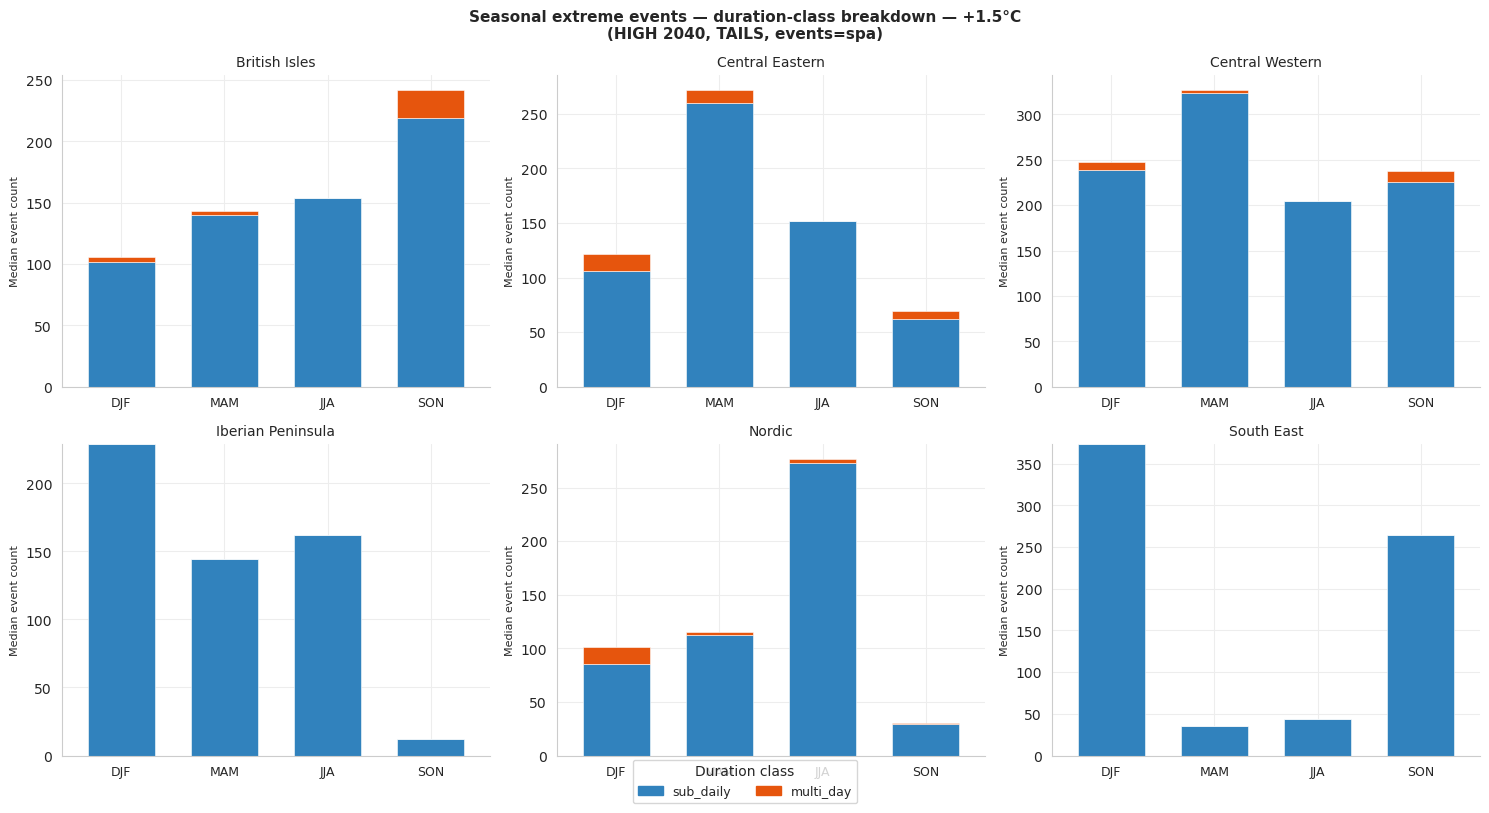

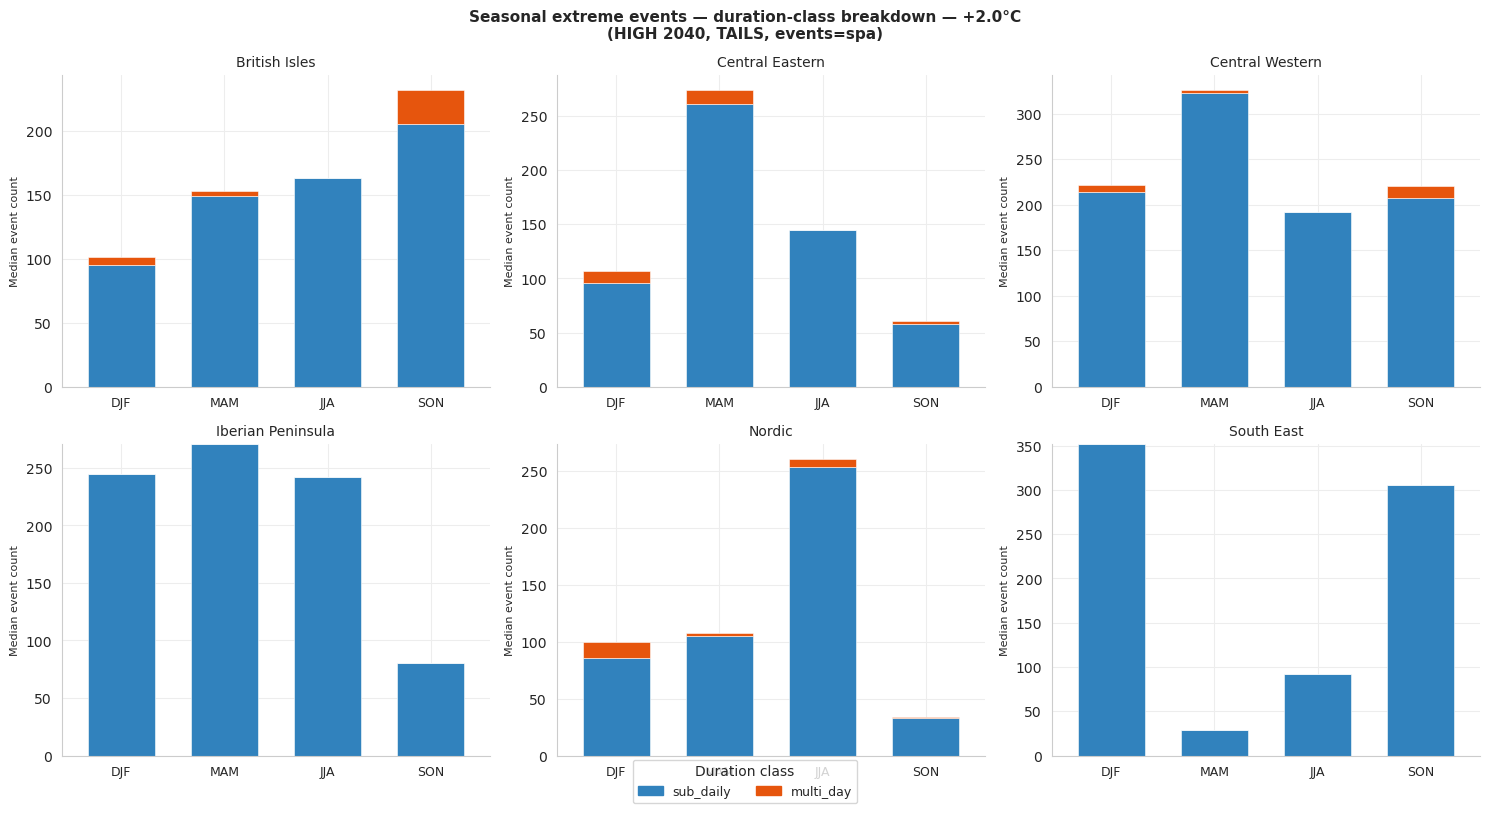

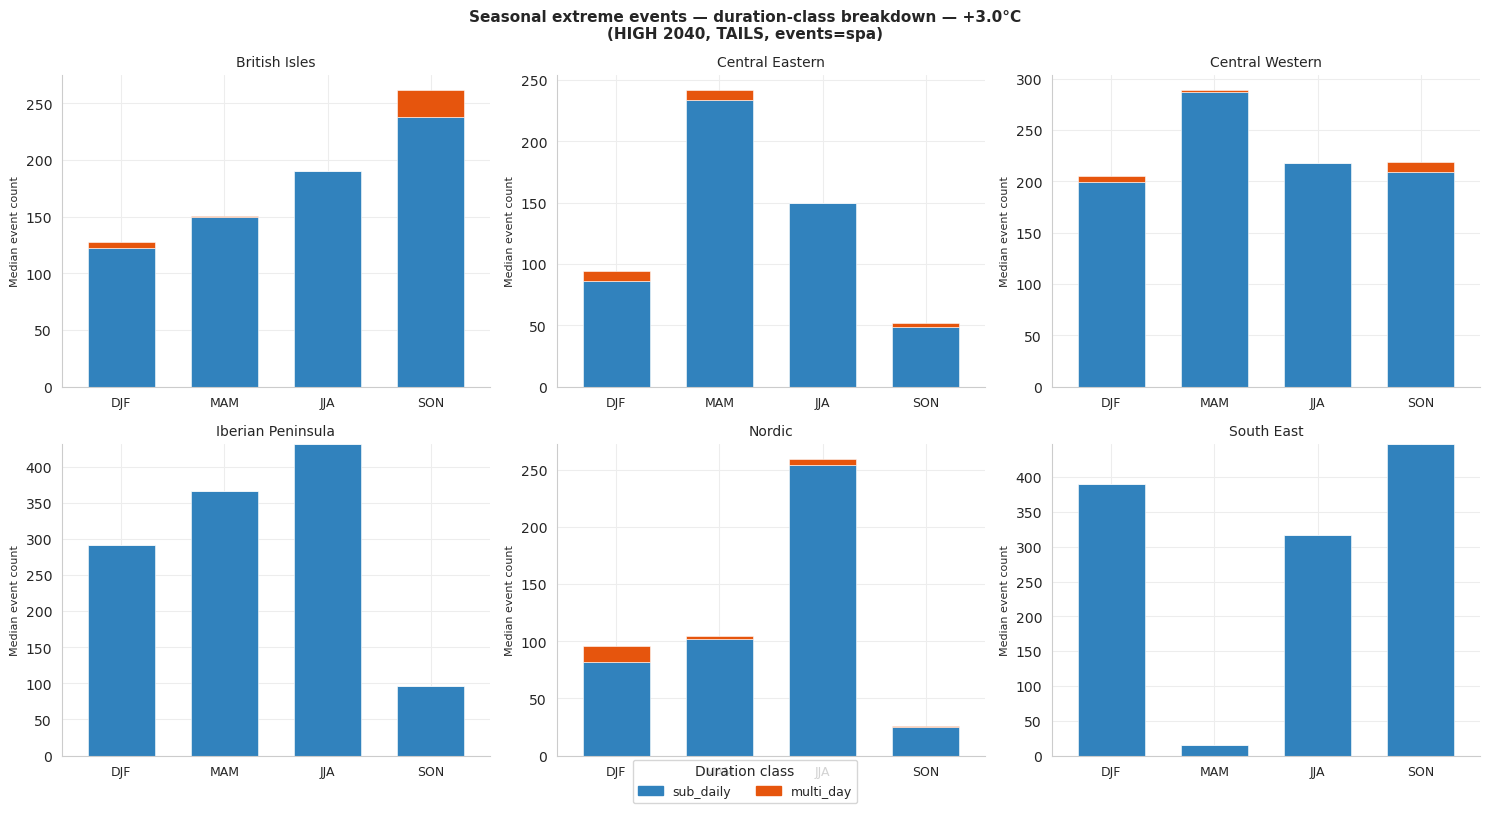

In [32]:
for period_name in list(period_defs.keys()):
    df_p = df_seasonal[df_seasonal["period"] == period_name]

    fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=False)
    fig.suptitle(
        f"Seasonal extreme events — duration-class breakdown — {period_name}\n"
        f"({supply_scenario} {supply_year}, {THRESHOLD_METHOD}, events={EVENT_DETECTION_METHOD})",
        fontsize=11, fontweight="bold",
    )

    for ax, zone in zip(axes.flat, zones):
        df_z = df_p[df_p["zone"] == str(zone)]
        pivot = (
            df_z.groupby(["season", "duration_class"])["n_events"]
            .median()
            .unstack("duration_class")
            .reindex(columns=DURATION_CLASS_ORDER, fill_value=0)
            .reindex(season_order, fill_value=0)
        )
        pivot.plot(
            kind="bar", stacked=True, ax=ax,
            color=[duration_palette[dc] for dc in DURATION_CLASS_ORDER],
            legend=False, width=0.65, edgecolor="white", linewidth=0.4,
        )
        ax.set_title(str(zone).replace("_", " "), fontsize=10)
        ax.set_xlabel("")
        ax.set_ylabel("Median event count", fontsize=8)
        ax.tick_params(axis="x", labelsize=9, rotation=0)
        sns.despine(ax=ax)

    handles = [plt.Rectangle((0, 0), 1, 1, color=duration_palette[dc]) for dc in DURATION_CLASS_ORDER]
    fig.legend(handles, DURATION_CLASS_ORDER, title="Duration class",
               loc="lower center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.02))
    plt.tight_layout()
    plt.show()

## B1b — Zone × season heatmap: % change in event count across warming levels

For each duration class, one figure per warming-level comparison showing how the
ensemble-median event count changes relative to the +1.5 °C baseline.

Rows = zones, columns = seasons; colour + annotation = % change.  
**×** markers denote cells where fewer than 6 of 9 models agree on the sign of change
(i.e. the direction of the signal is not robust across the ensemble).

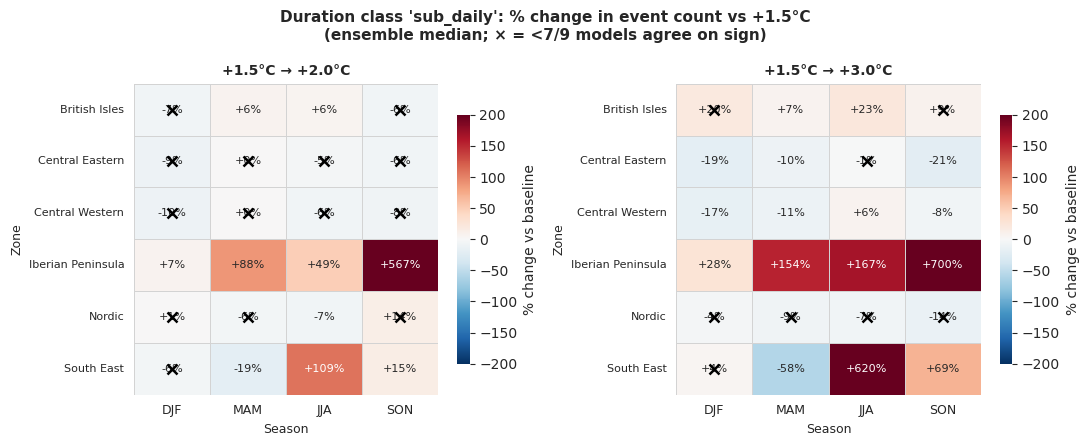

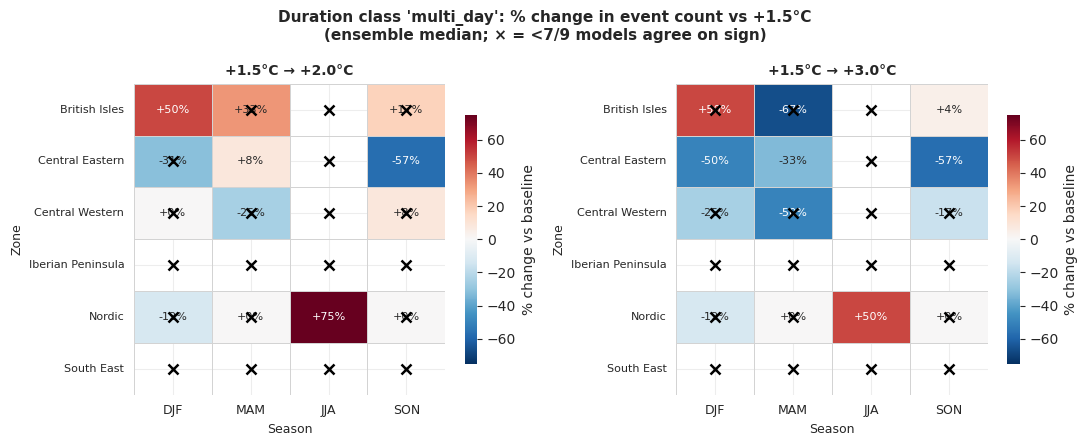

In [ ]:
_period_names    = list(period_defs.keys())
_ref_period      = _period_names[0]
_compare_periods = [p for p in _period_names if p != _ref_period]
_n_comp          = len(_compare_periods)
_zone_labels     = [str(z) for z in zones]
_ROBUST_N        = 7   # min models that must agree on sign of change


def _pct_annot(df_pct: pd.DataFrame) -> pd.DataFrame:
    """Annotation strings; NaN cells become '—'."""
    out = df_pct.copy().astype(object)
    for r in out.index:
        for c in out.columns:
            v = df_pct.loc[r, c]
            out.loc[r, c] = f"{v:+.0f}%" if np.isfinite(v) else "—"
    return out


def _agreement_matrix(df_dc, ref_period, comp_period, zone_labels, season_order):
    """Count of models agreeing on the dominant sign of change per (zone, season)."""
    agree = pd.DataFrame(np.nan, index=zone_labels, columns=season_order)
    for z in zone_labels:
        for s in season_order:
            ref_s = (
                df_dc[(df_dc["zone"] == z) & (df_dc["season"] == s) & (df_dc["period"] == ref_period)]
                .set_index("model")["n_events"]
            )
            cmp_s = (
                df_dc[(df_dc["zone"] == z) & (df_dc["season"] == s) & (df_dc["period"] == comp_period)]
                .set_index("model")["n_events"]
            )
            common = ref_s.index.intersection(cmp_s.index)
            if len(common) == 0:
                continue
            diffs = cmp_s.loc[common] - ref_s.loc[common]
            agree.loc[z, s] = float(max(int((diffs > 0).sum()), int((diffs < 0).sum())))
    return agree.astype(float)


for dc in DURATION_CLASS_ORDER:
    df_dc = df_seasonal[df_seasonal["duration_class"] == dc]

    med = (
        df_dc.groupby(["zone", "season", "period"])["n_events"]
        .median()
        .reset_index()
    )
    ref_pivot = (
        med[med["period"] == _ref_period]
        .pivot(index="zone", columns="season", values="n_events")
        .reindex(index=_zone_labels, columns=season_order, fill_value=np.nan)
    )

    pct_maps   = {}
    agree_maps = {}
    for comp in _compare_periods:
        comp_pivot = (
            med[med["period"] == comp]
            .pivot(index="zone", columns="season", values="n_events")
            .reindex(index=_zone_labels, columns=season_order, fill_value=np.nan)
        )
        pct_maps[comp]   = (comp_pivot - ref_pivot) / ref_pivot.replace(0, np.nan) * 100
        agree_maps[comp] = _agreement_matrix(df_dc, _ref_period, comp, _zone_labels, season_order)

    all_finite = np.concatenate([pct.values[np.isfinite(pct.values)] for pct in pct_maps.values()])
    vlim = min(max(float(np.max(np.abs(all_finite))), 10), 200) if all_finite.size > 0 else 50

    fig, axes = plt.subplots(1, _n_comp, figsize=(5.5 * _n_comp, 4.5))
    if _n_comp == 1:
        axes = [axes]
    fig.suptitle(
        f"Duration class '{dc}': % change in event count vs {_ref_period}\n"
        f"(ensemble median; × = <{_ROBUST_N}/{len(models)} models agree on sign)",
        fontsize=11, fontweight="bold",
    )

    for ax, comp in zip(axes, _compare_periods):
        pct   = pct_maps[comp]
        agree = agree_maps[comp]

        sns.heatmap(
            pct, ax=ax,
            annot=_pct_annot(pct), fmt="",
            cmap="RdBu_r", center=0, vmin=-vlim, vmax=vlim,
            cbar_kws={"label": "% change vs baseline", "shrink": 0.8},
            linewidths=0.5, linecolor="lightgray",
            annot_kws={"size": 8},
        )
        # Stipple low-agreement cells
        for i, z in enumerate(pct.index):
            for j, s in enumerate(pct.columns):
                n_agree = agree.loc[z, s]
                if not np.isfinite(n_agree) or n_agree < _ROBUST_N:
                    ax.plot(j + 0.5, i + 0.5, "x",
                            color="black", markersize=7, markeredgewidth=1.8, zorder=5)

        ax.set_title(f"{_ref_period} → {comp}", fontsize=10, fontweight="bold")
        ax.set_xlabel("Season", fontsize=9)
        ax.set_ylabel("Zone", fontsize=9)
        ax.set_yticklabels([z.replace("_", " ") for z in _zone_labels], rotation=0, fontsize=8)
        ax.set_xticklabels(season_order, rotation=0, fontsize=9)

    plt.tight_layout()
    plt.show()

## B2 — Seasonal frequency and severity by duration class

Reuses `plot_seasonal_conditional_metrics()` — one figure per metric per duration class.


── Seasonal metrics: 'sub_daily' events  (total n_events=120018)


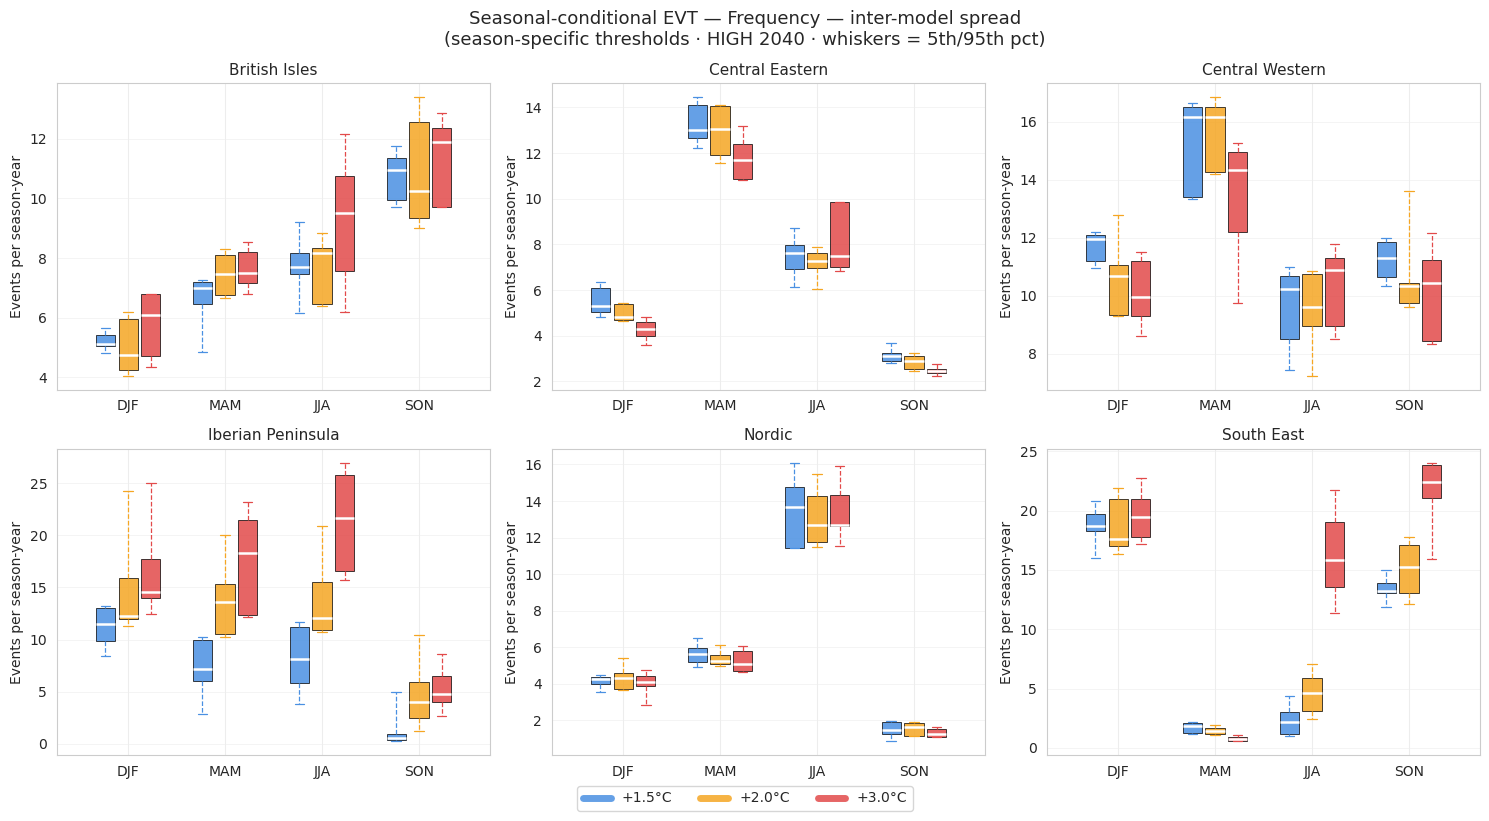

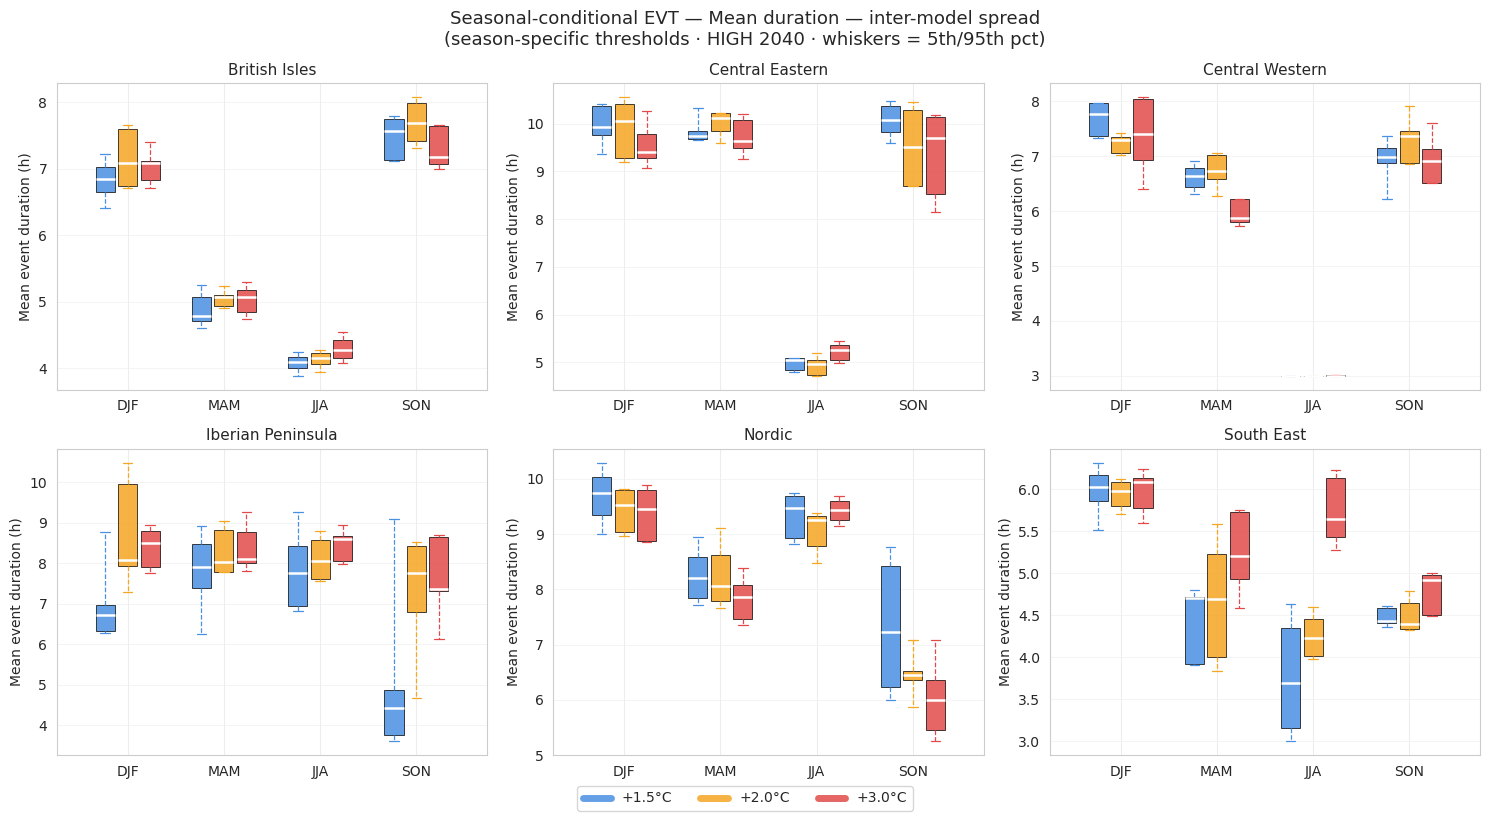

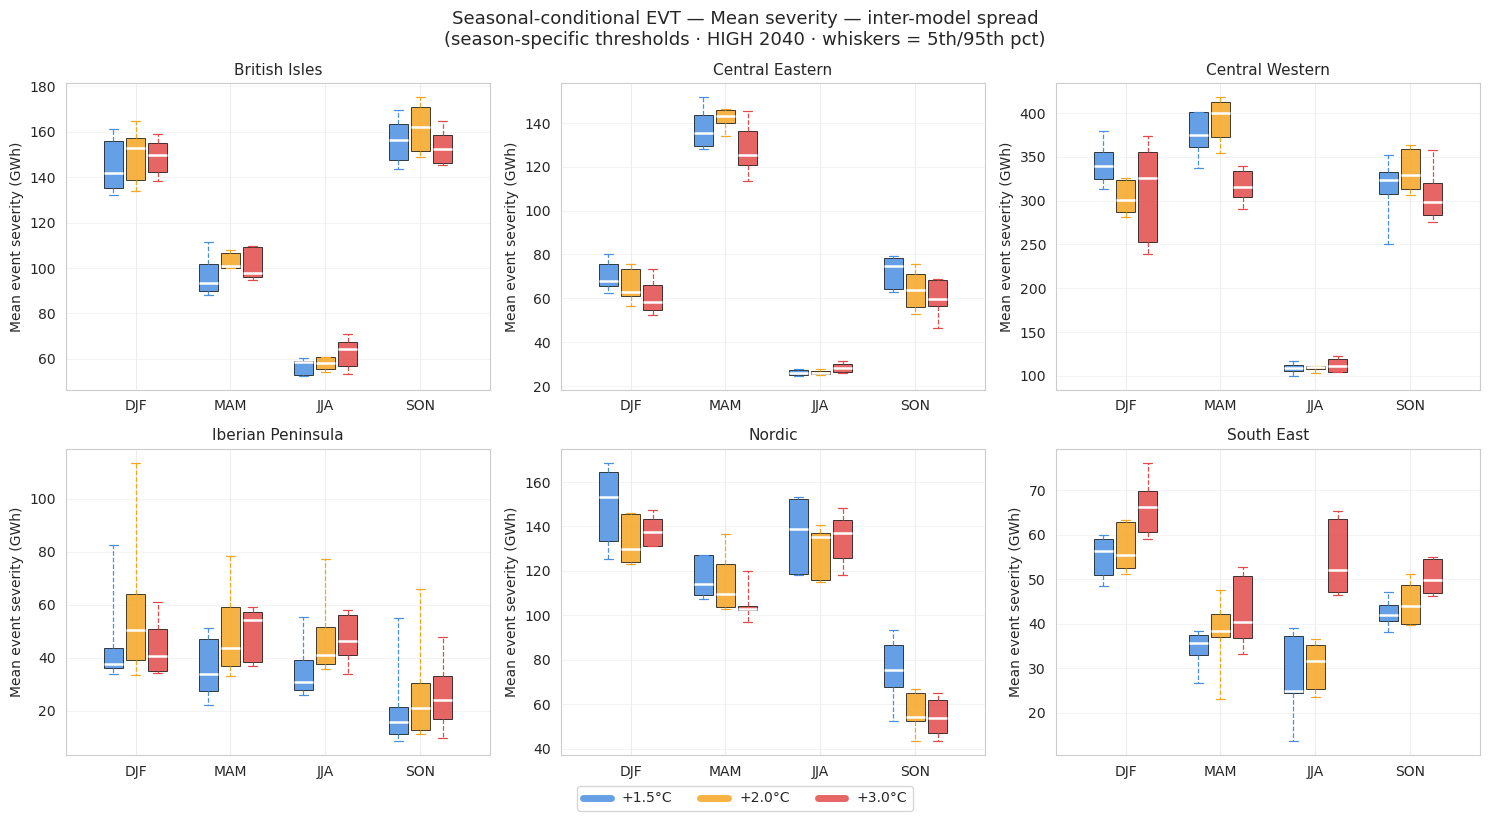

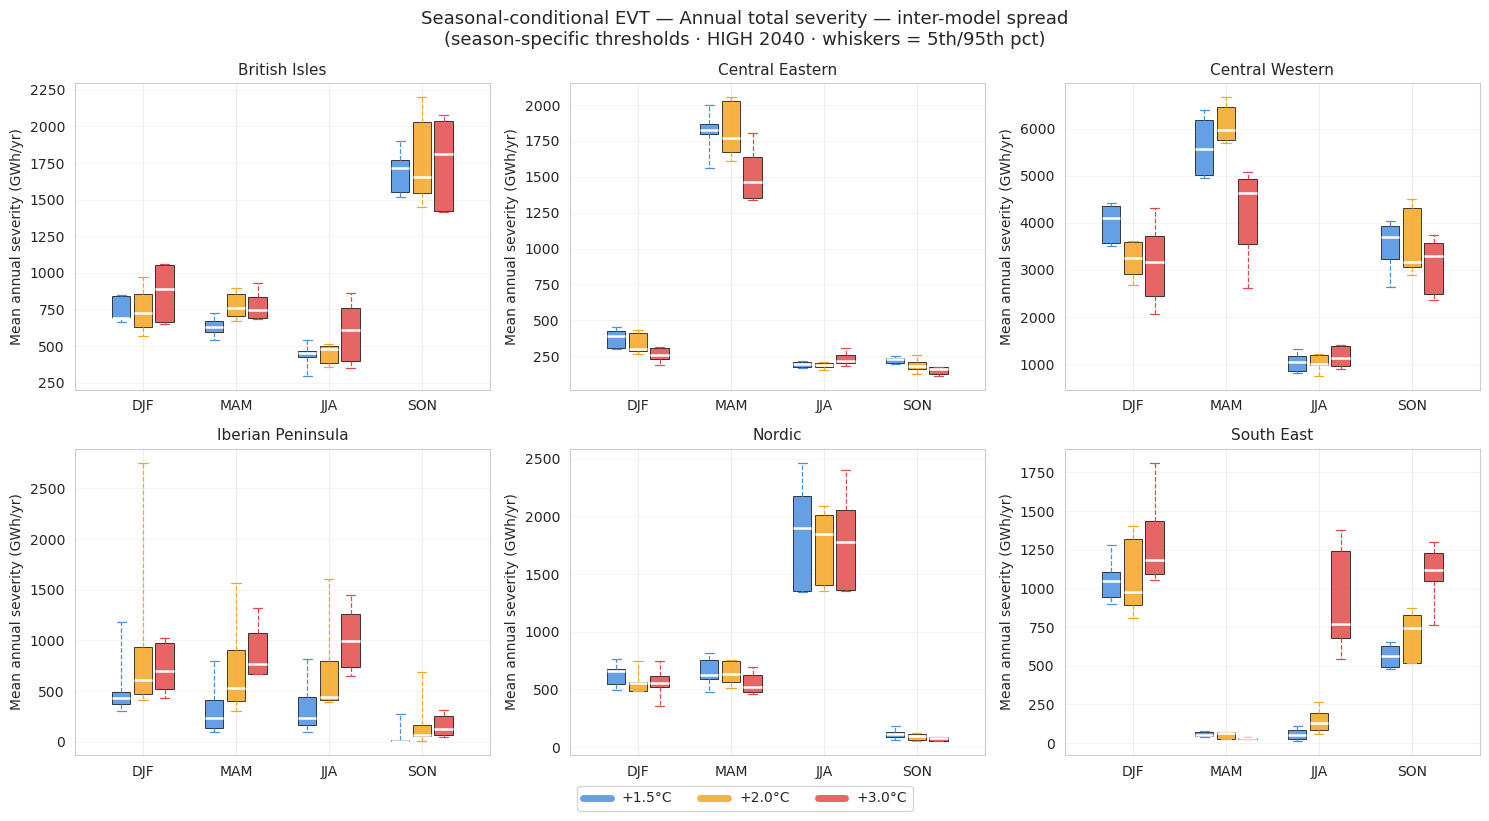

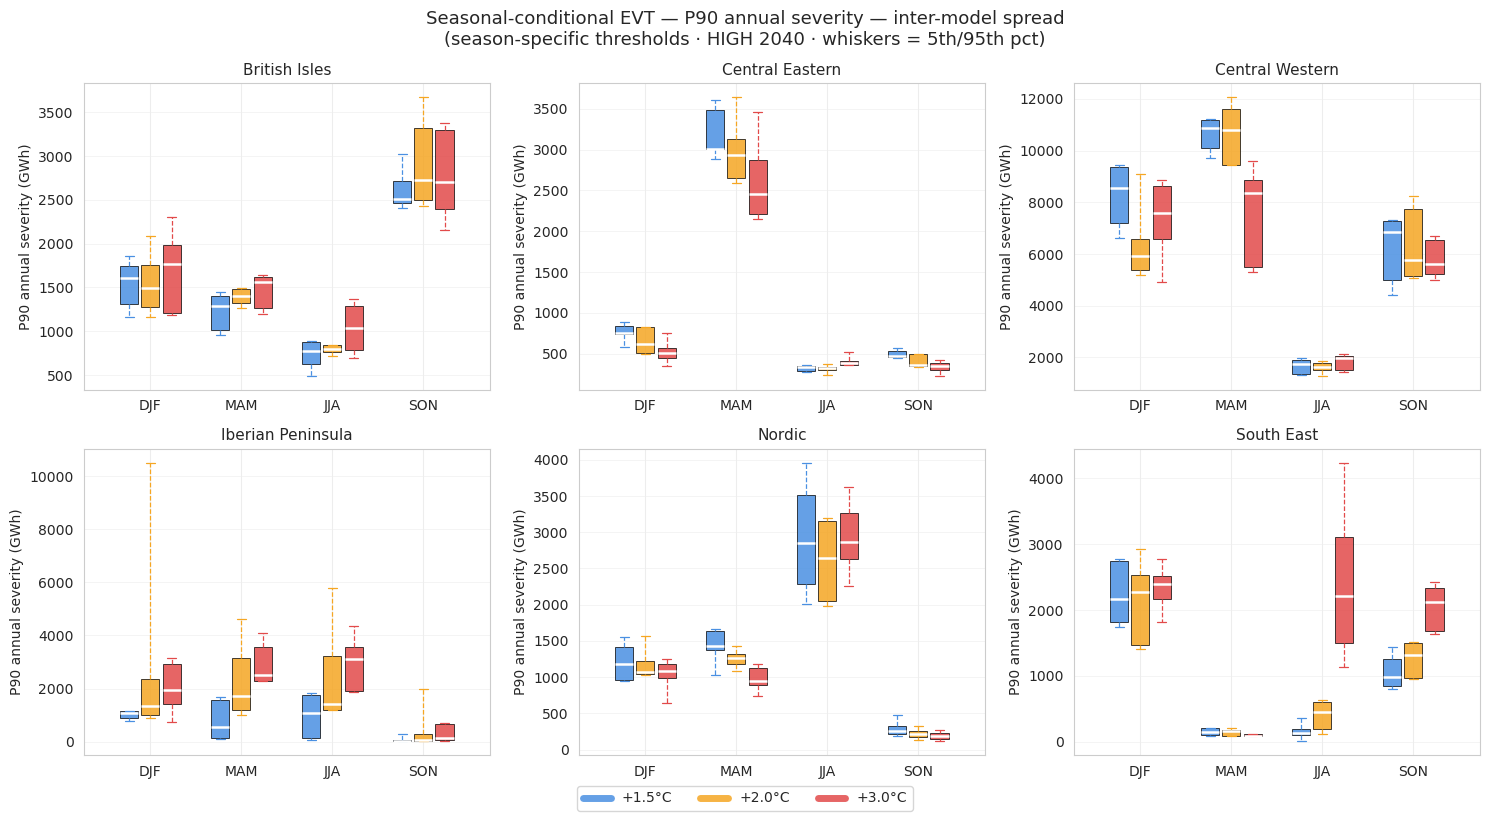


── Seasonal metrics: 'multi_day' events  (total n_events=2899)


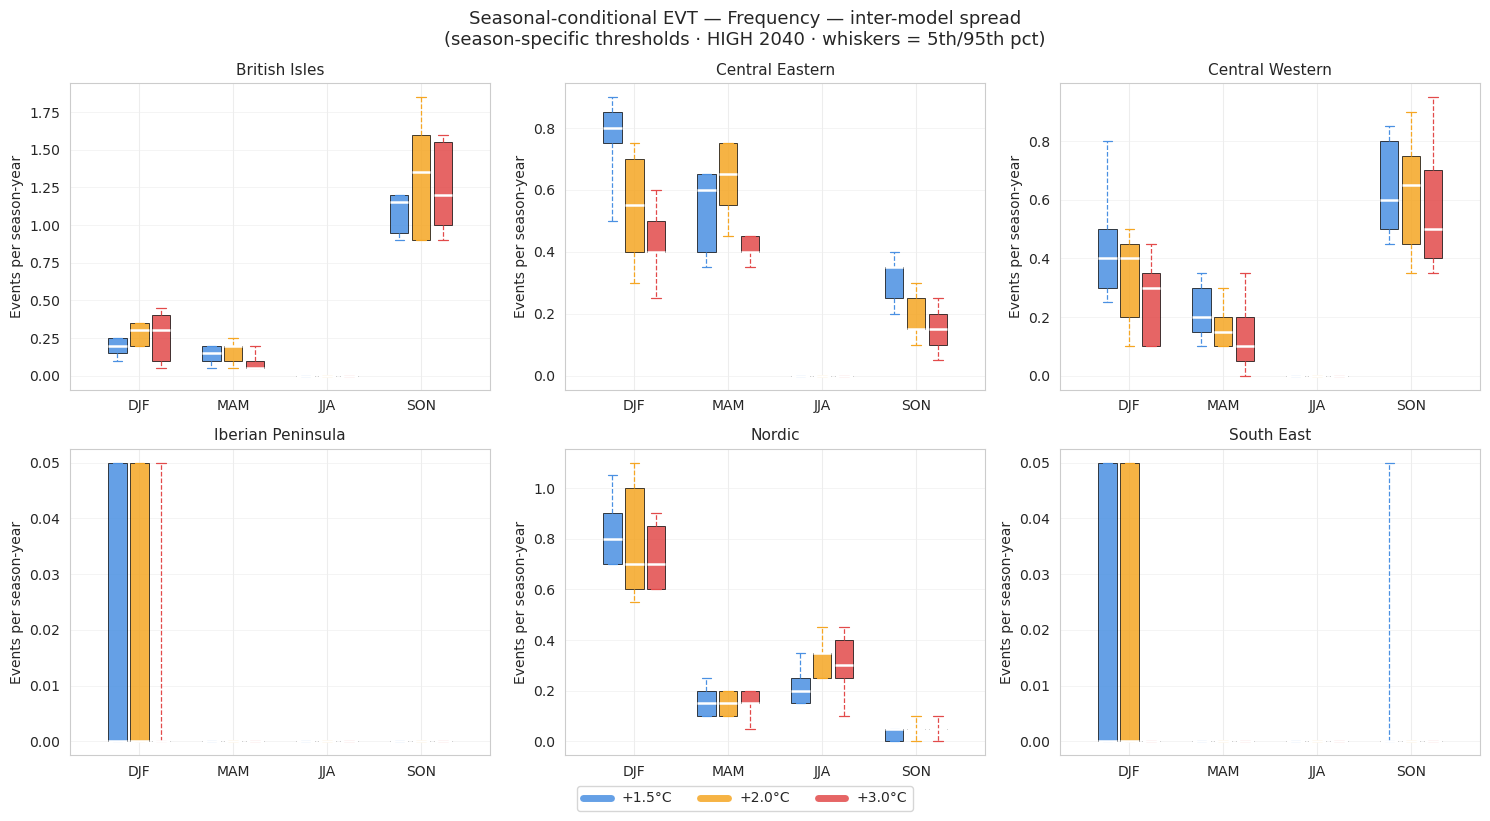

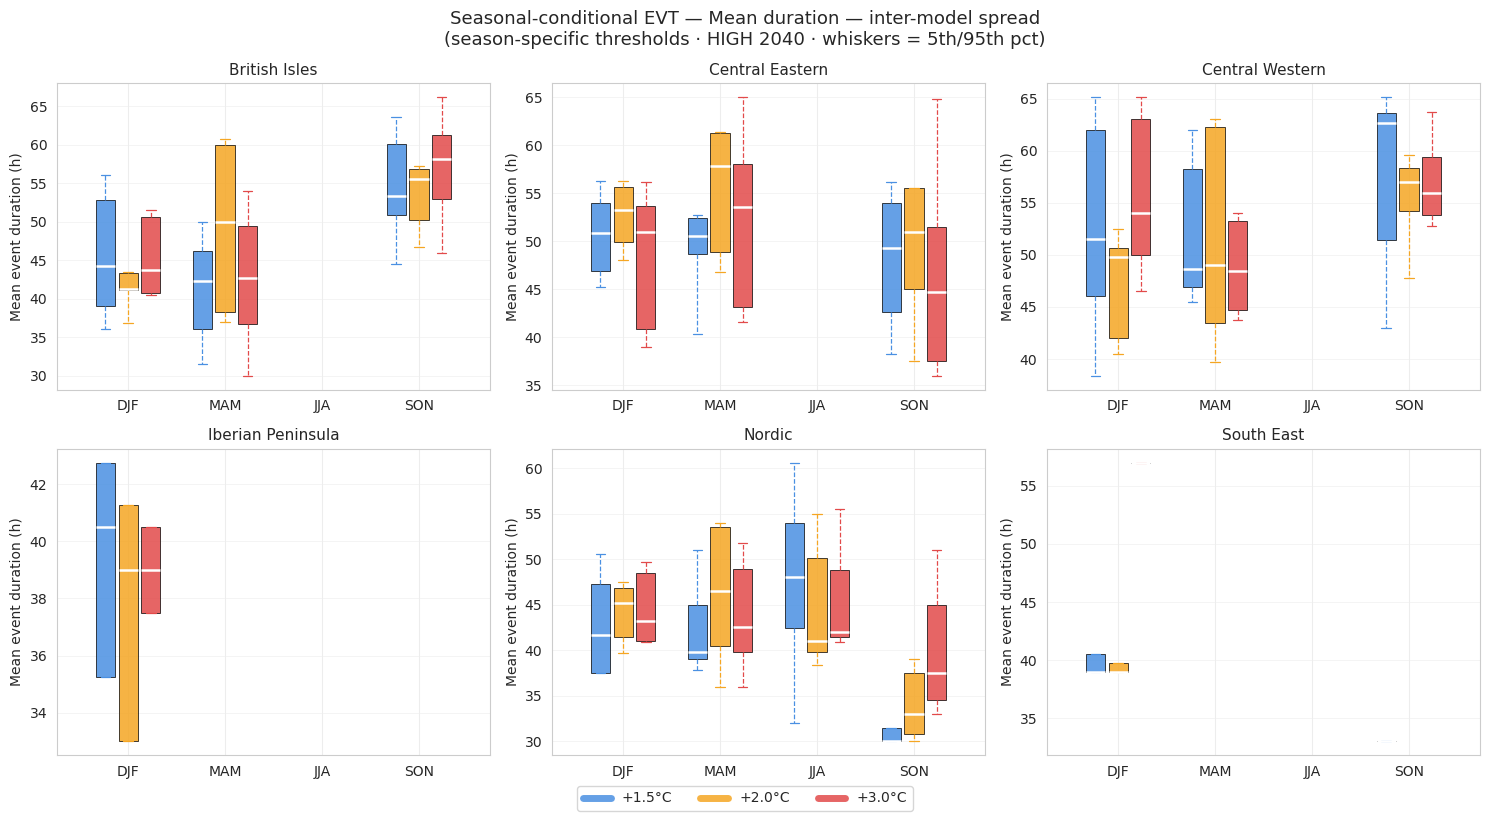

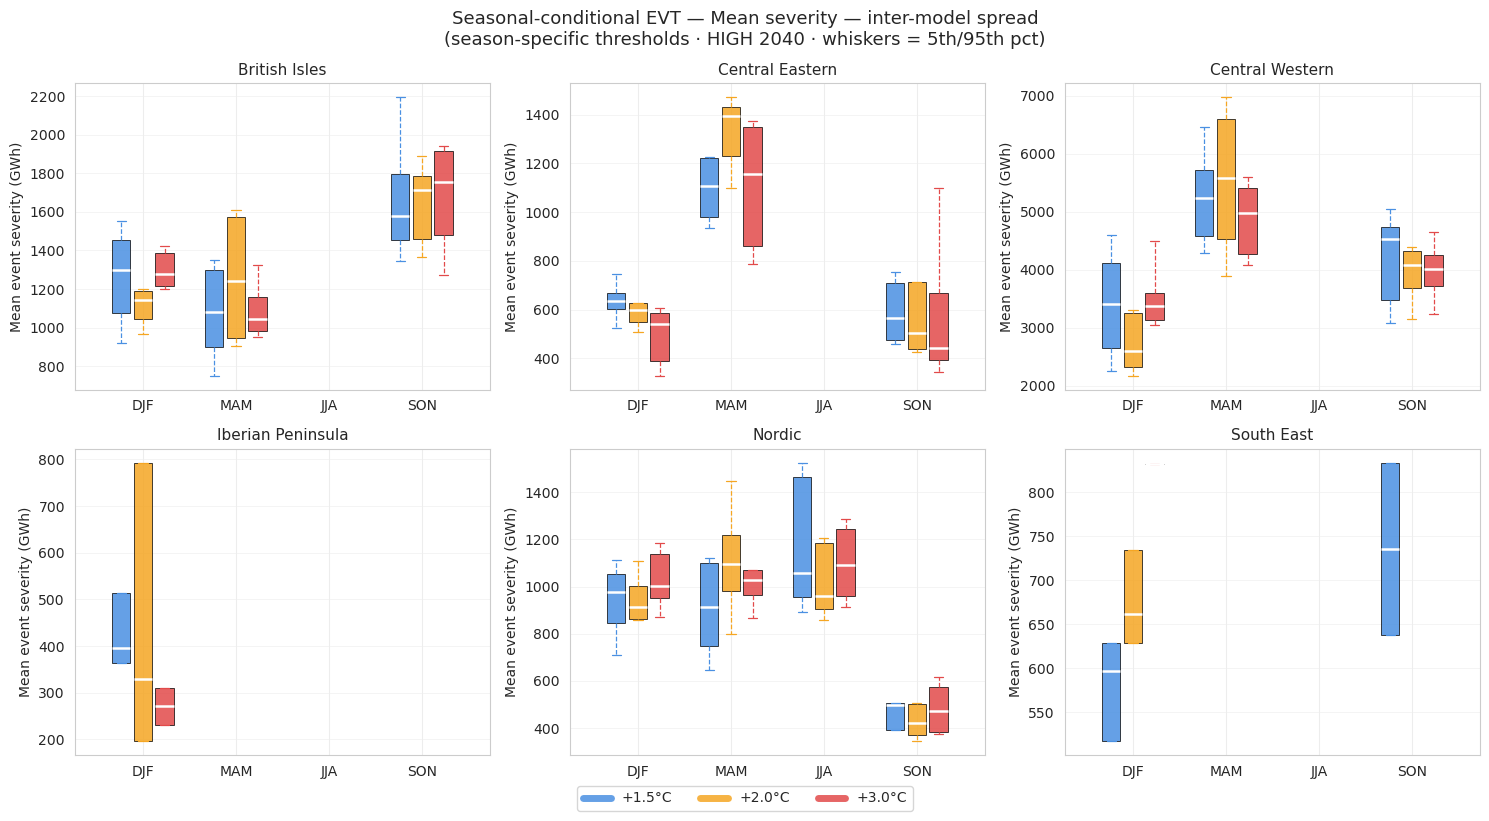

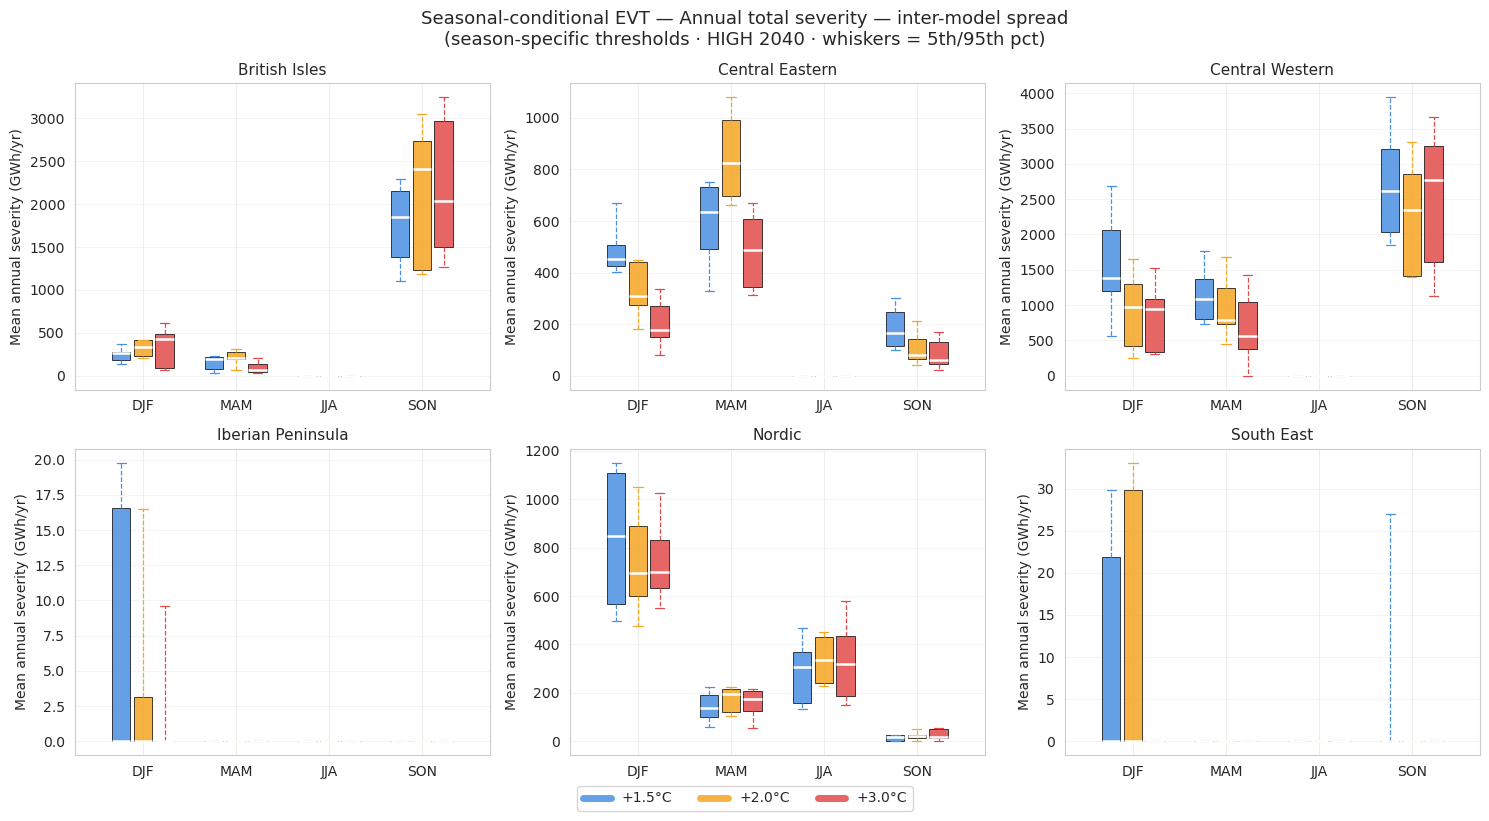

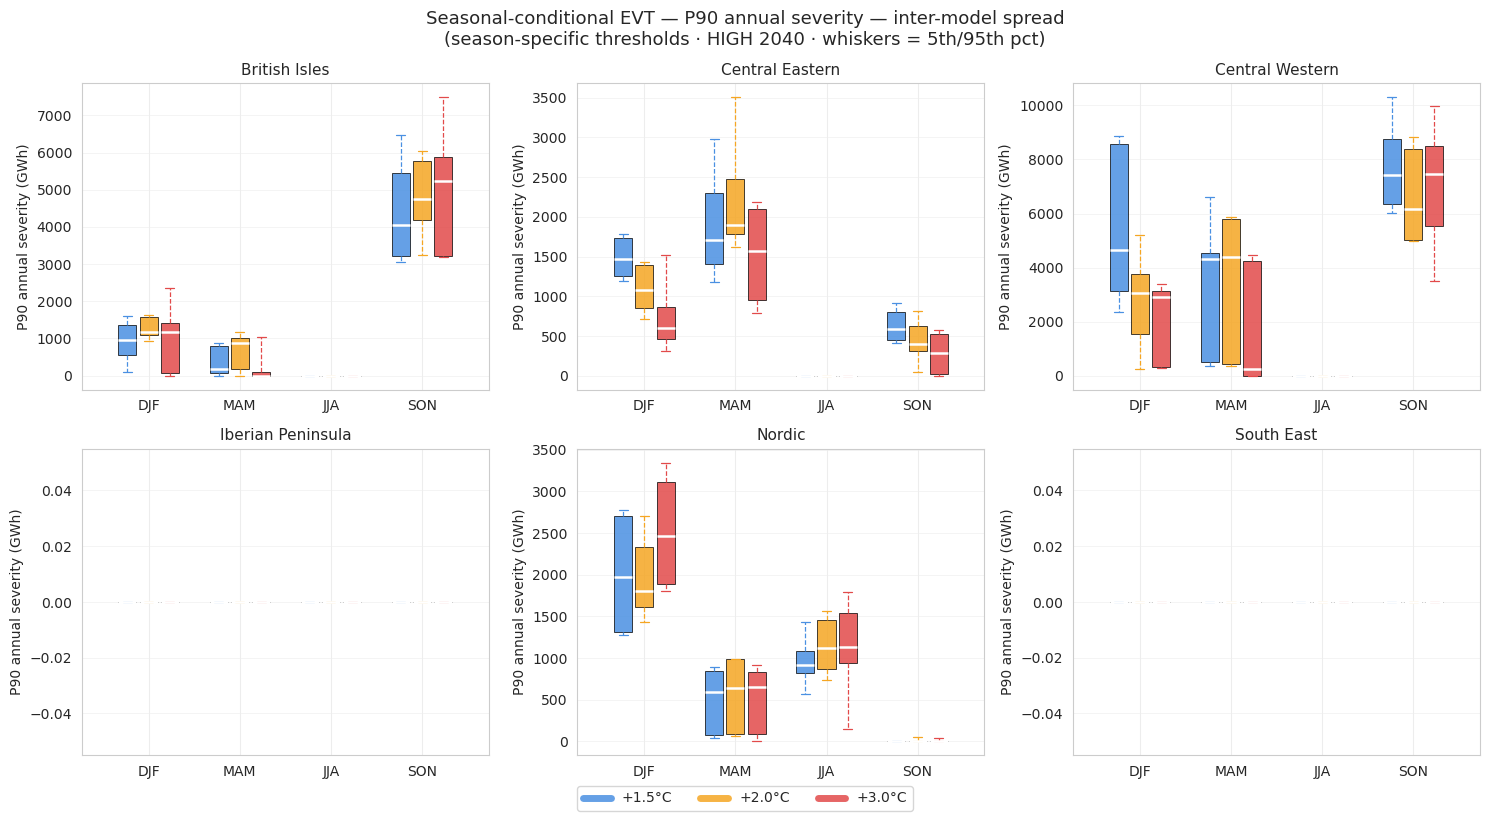

In [34]:
seasonal_metrics = [
    ("freq_per_year",              "Events per season-year",         "Frequency"),
    ("avg_duration_h",             "Mean event duration (h)",         "Mean duration"),
    ("avg_severity_gwh",           "Mean event severity (GWh)",       "Mean severity"),
    ("total_annual_severity_gwh",  "Mean annual severity (GWh/yr)",   "Annual total severity"),
    ("p90_annual_severity_gwh",    "P90 annual severity (GWh)",       "P90 annual severity"),
]

for dc in DURATION_CLASS_ORDER:
    df_dc = df_seasonal[df_seasonal["duration_class"] == dc].copy()
    n_total = df_dc["n_events"].sum()
    if n_total == 0:
        print(f"  [skip {dc}: no events]")
        continue
    print(f"\n── Seasonal metrics: '{dc}' events  (total n_events={n_total:.0f})")
    plot_seasonal_conditional_metrics(
        df_dc,
        metrics=seasonal_metrics,
        zones=zones,
        period_defs=period_defs,
        season_order=season_order,
        period_colors=period_colors,
        supply_scenario=supply_scenario,
        supply_year=supply_year,
    )

## B3 — Driver attribution by season and duration class

Reuses `plot_seasonal_attribution()` — one figure per duration class.


── Seasonal attribution: 'sub_daily' events


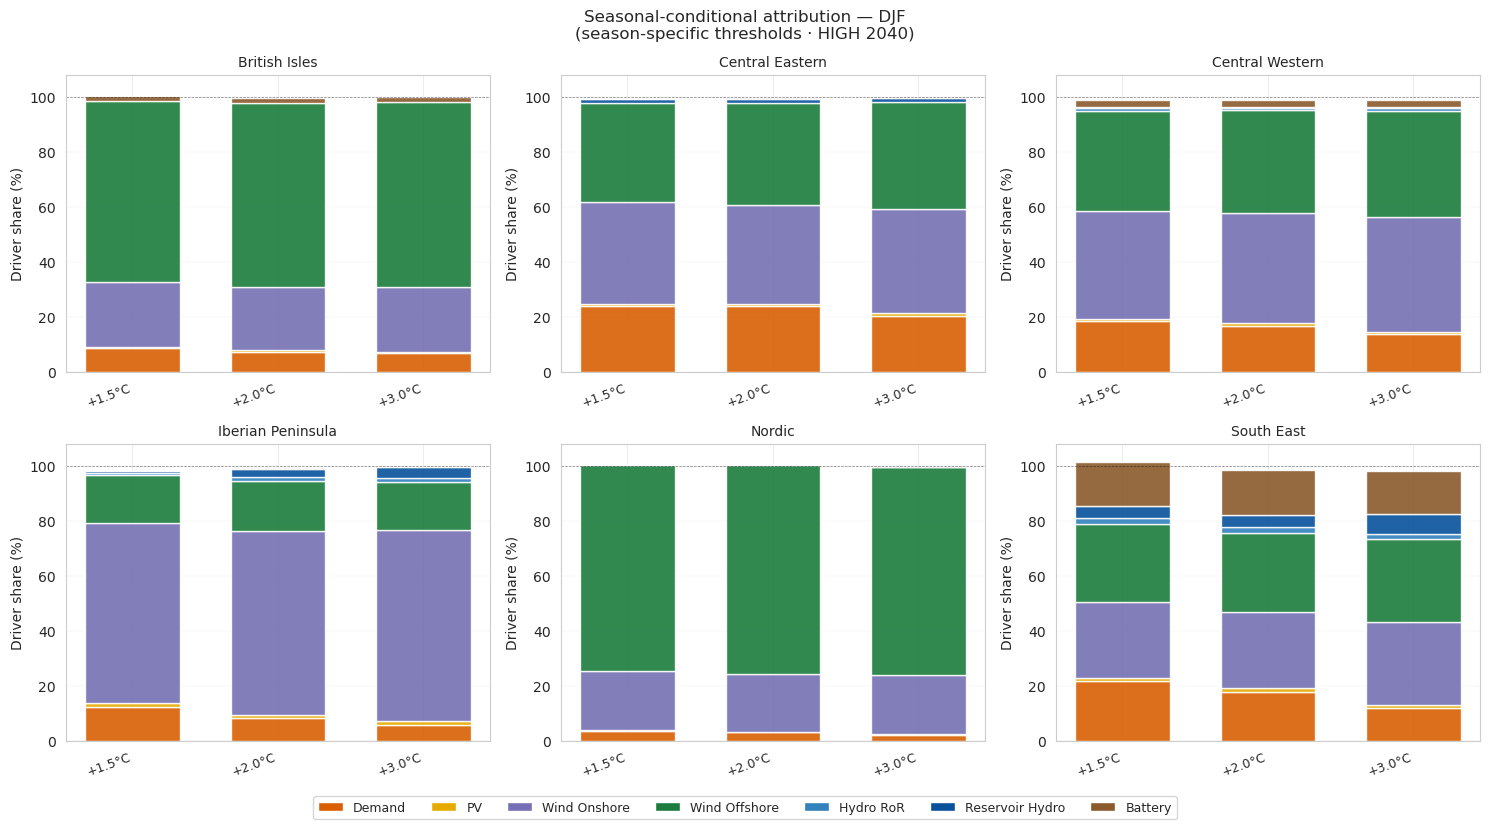

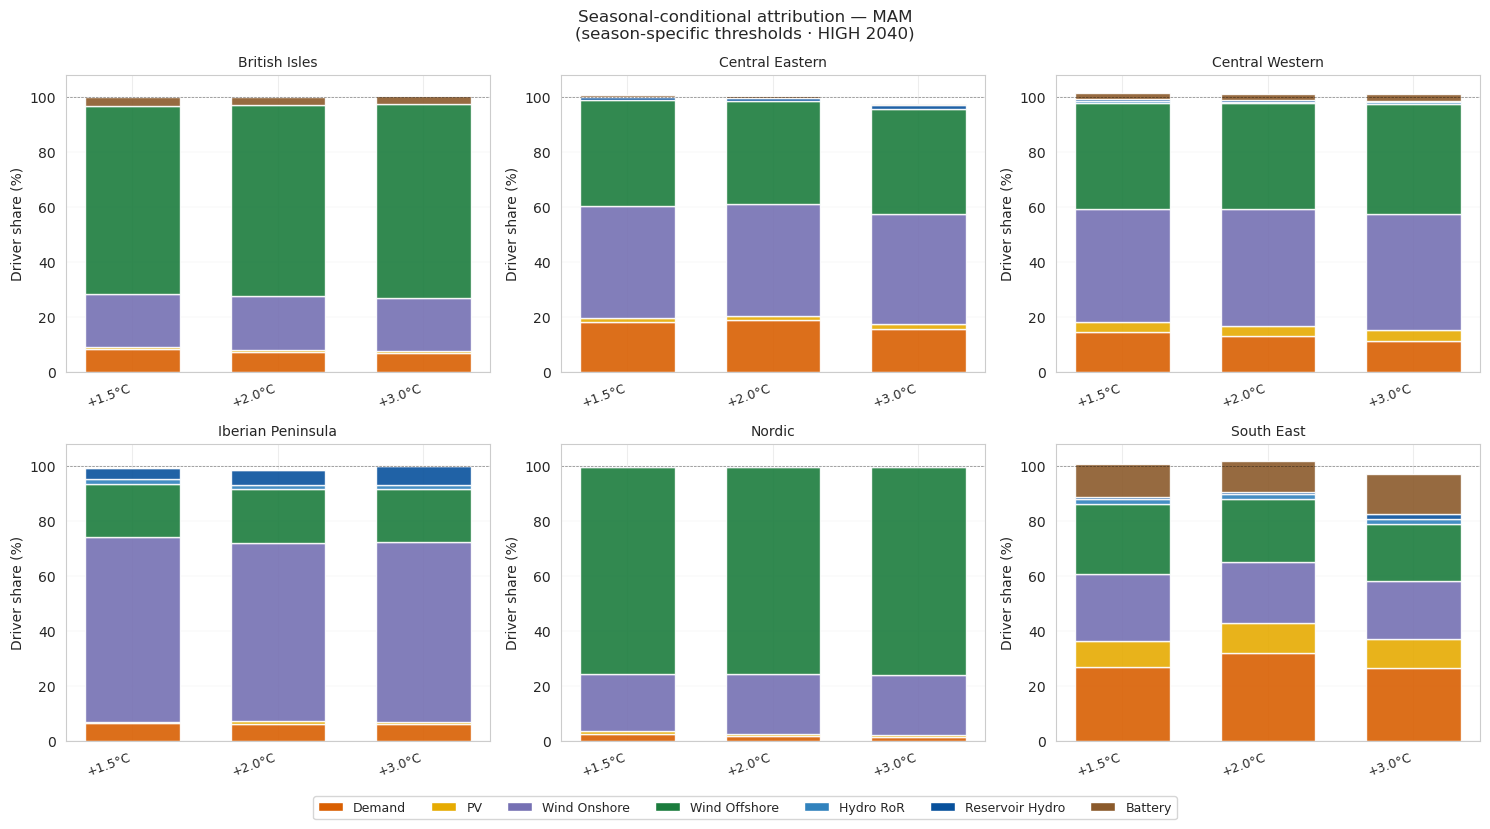

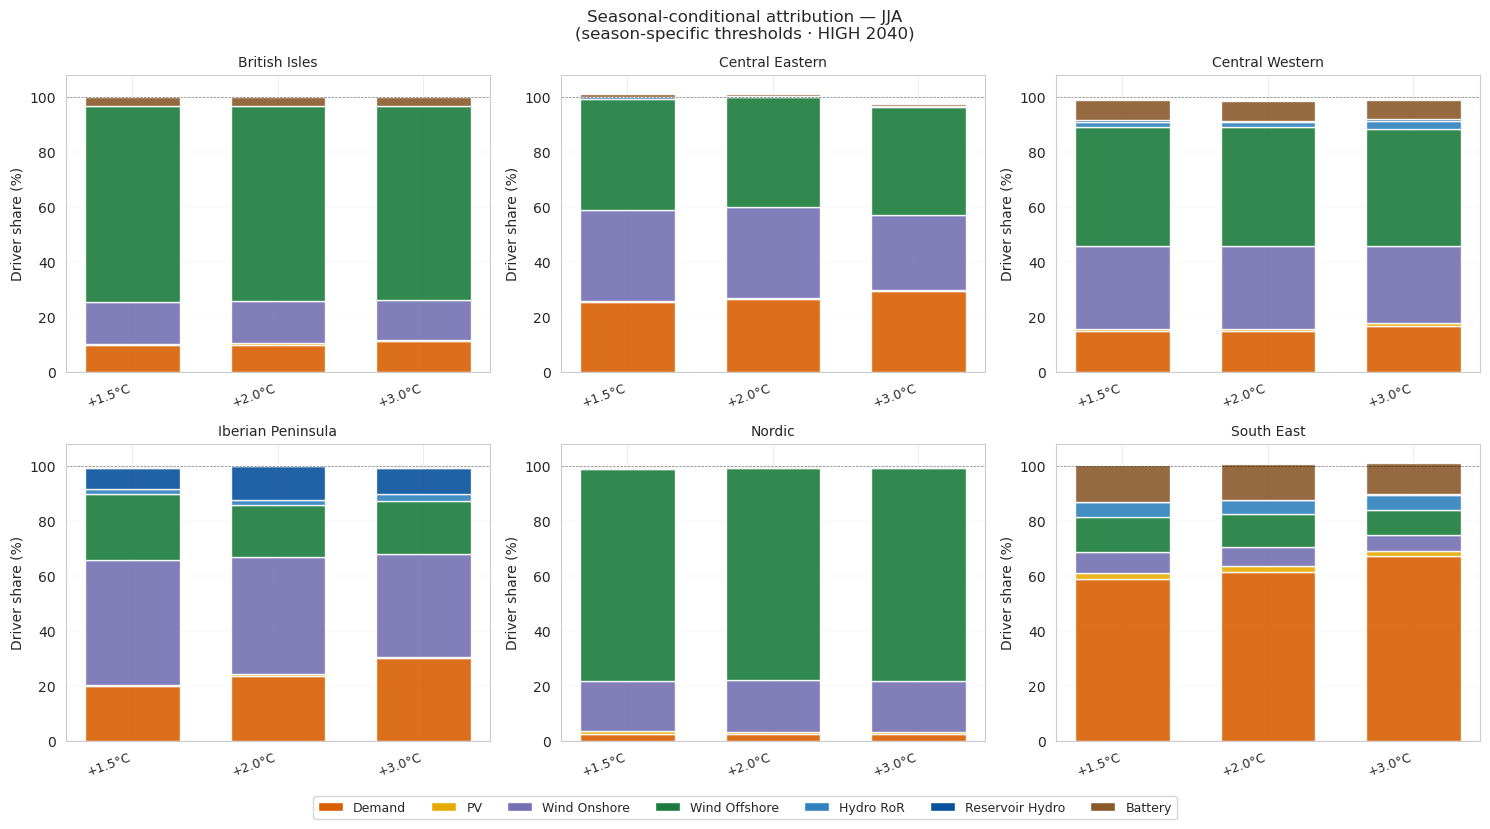

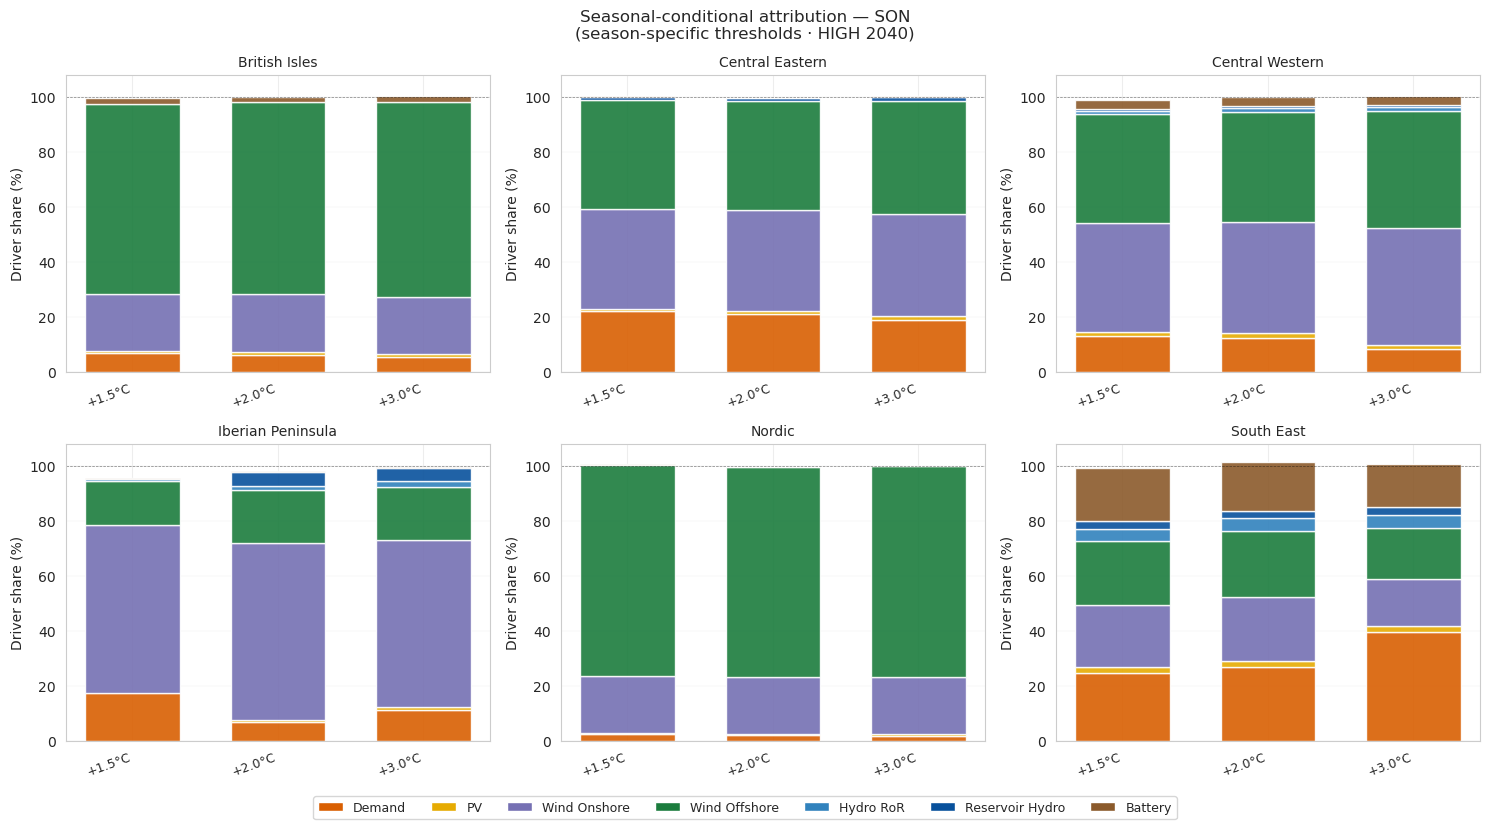


── Seasonal attribution: 'multi_day' events


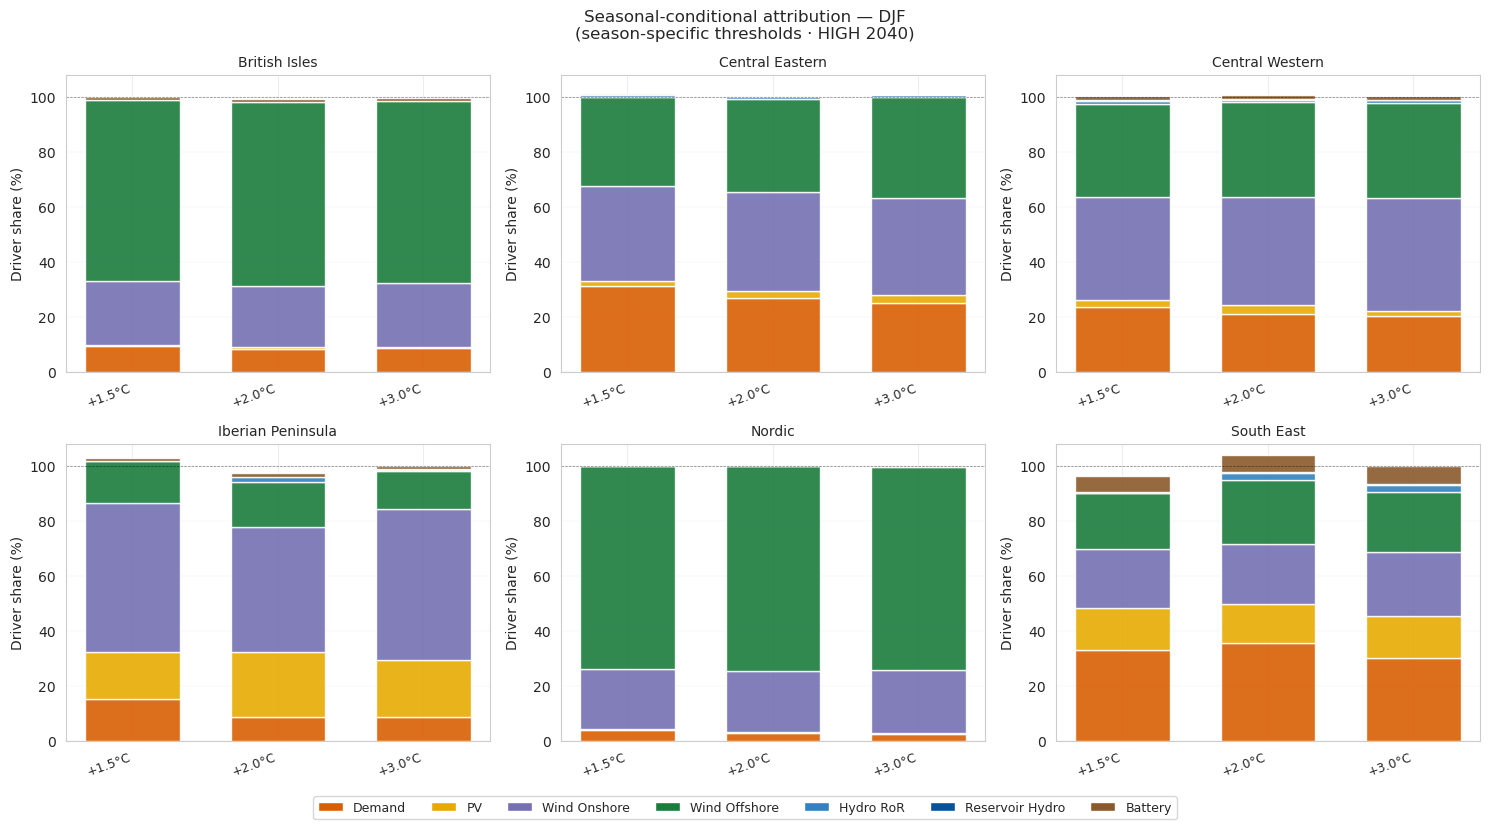

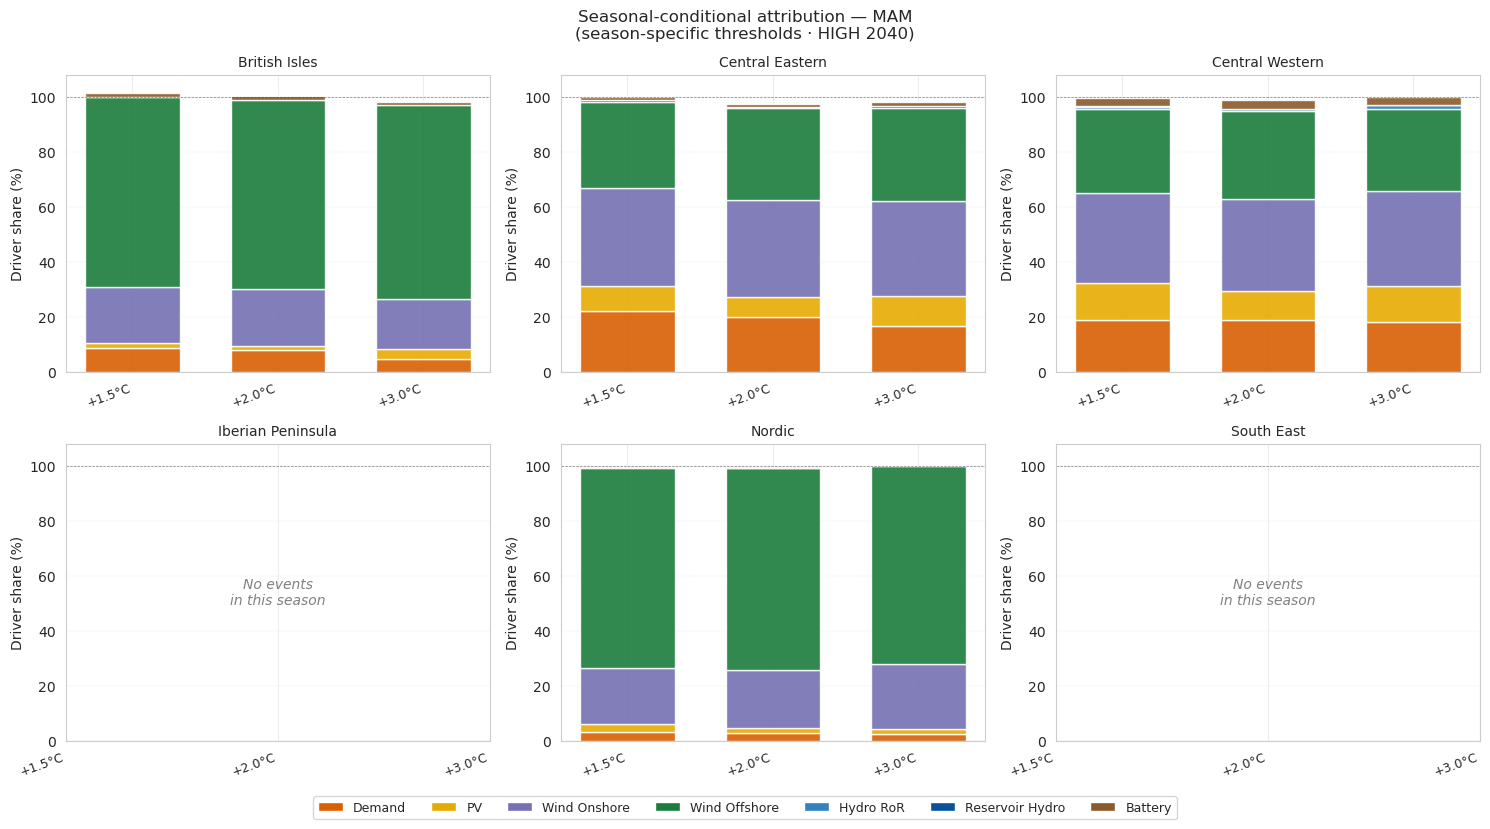

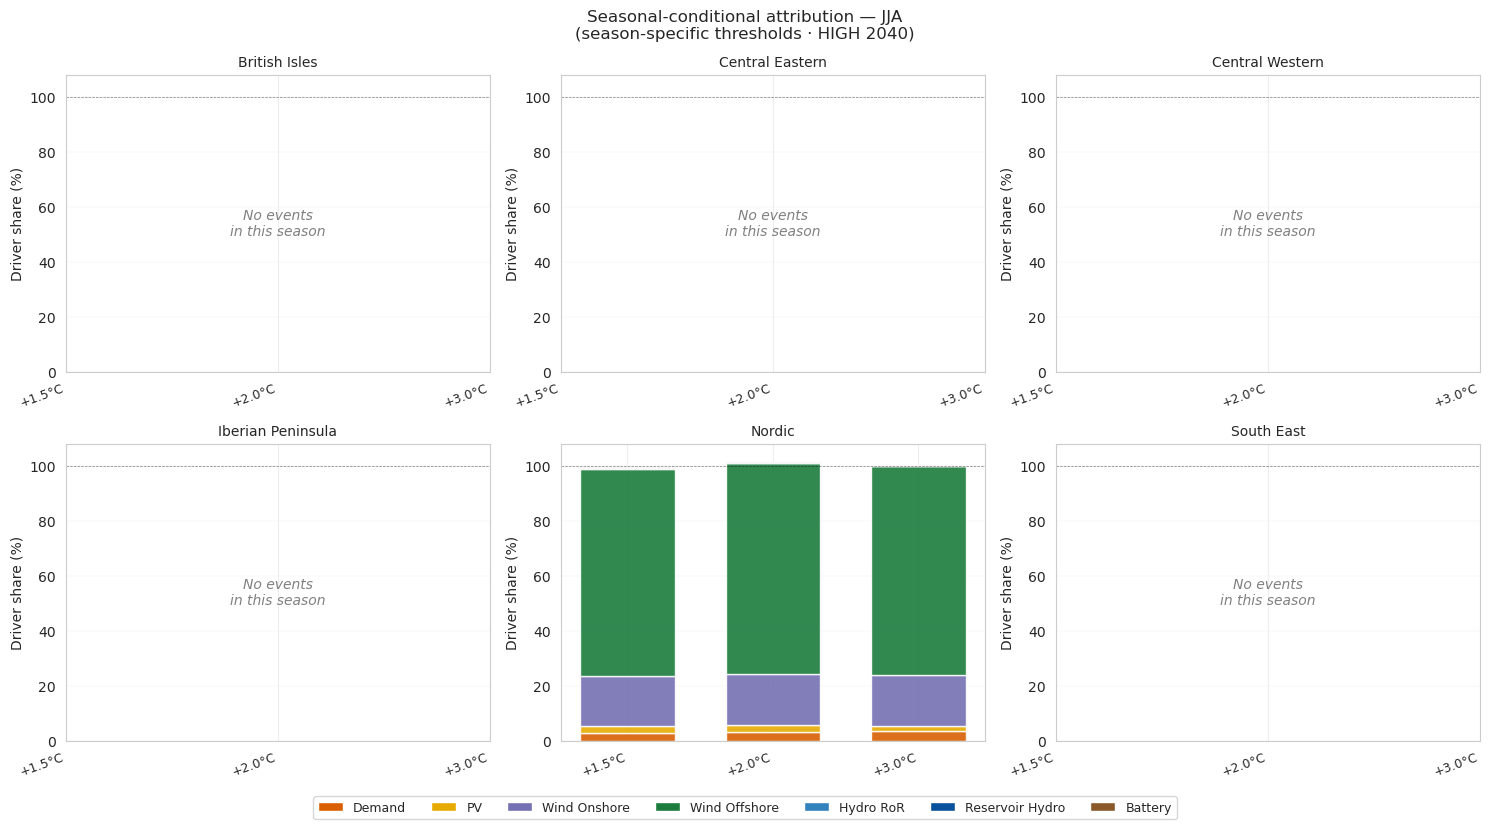

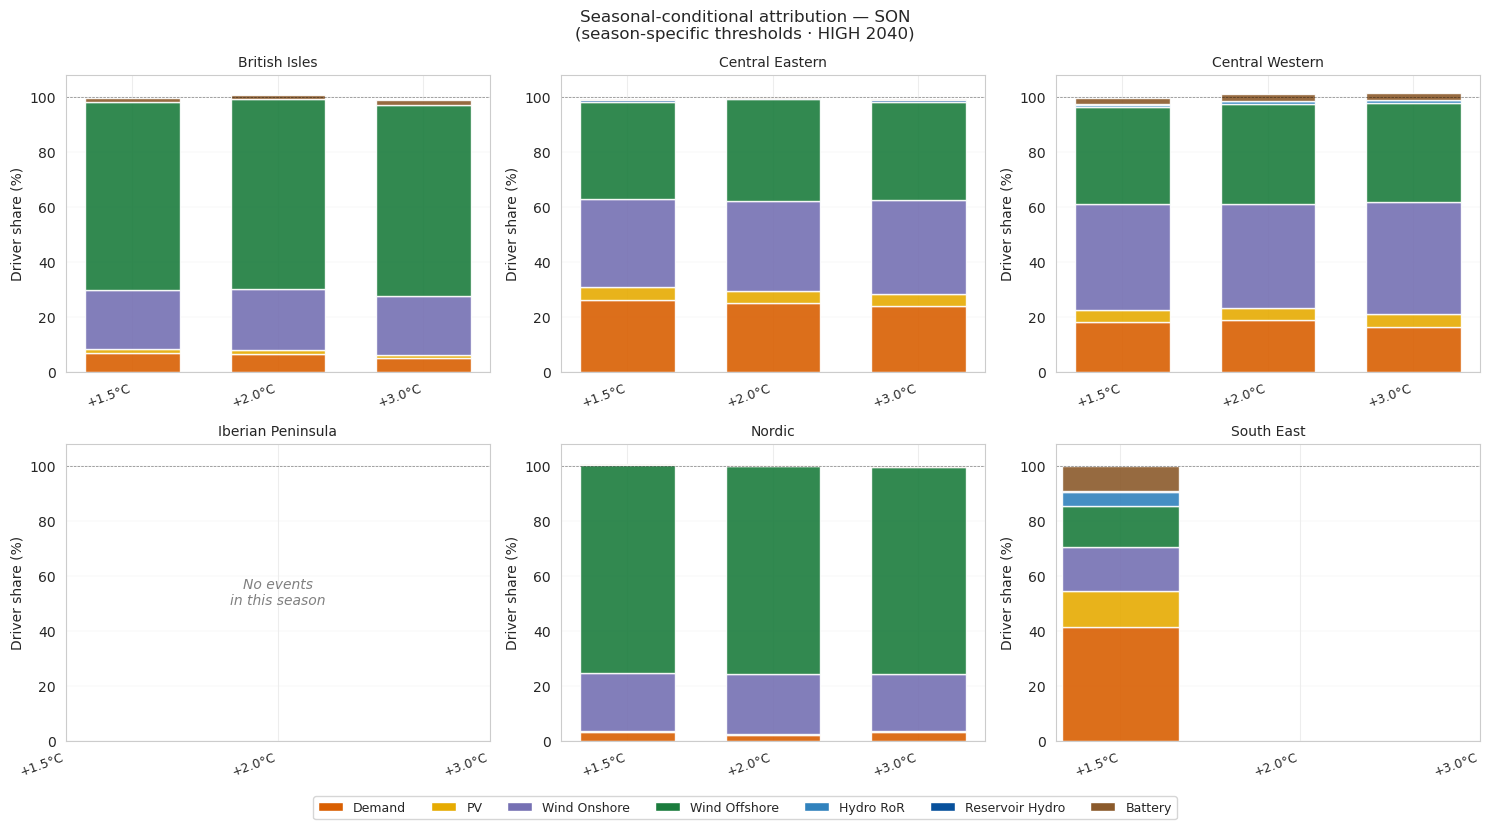

In [35]:
for dc in DURATION_CLASS_ORDER:
    df_dc = df_seasonal[
        (df_seasonal["duration_class"] == dc) & (df_seasonal["n_events"] > 0)
    ].copy()
    if df_dc.empty:
        continue
    print(f"\n── Seasonal attribution: '{dc}' events")
    plot_seasonal_attribution(
        df_dc,
        zones=zones,
        season_order=season_order,
        period_defs=period_defs,
        driver_cols=driver_cols,
        driver_palette=driver_palette,
        supply_scenario=supply_scenario,
        supply_year=supply_year,
    )

## B4 — Driver anomaly distributions (seasonal)

Same signed anomaly view as A5, but using the seasonal DataFrame — so each plot
reflects events detected with **season-specific thresholds**, constrained to that season.

One figure set per duration class; within each set:
- *Per-period* figures: `x=Component, hue=Season` — how driver anomalies vary across seasons at a given warming level.
- *Per-season* figures: `x=Component, hue=Period` — how warming shifts each driver's anomaly within a season.


── Driver anomaly distributions (seasonal): 'sub_daily' events


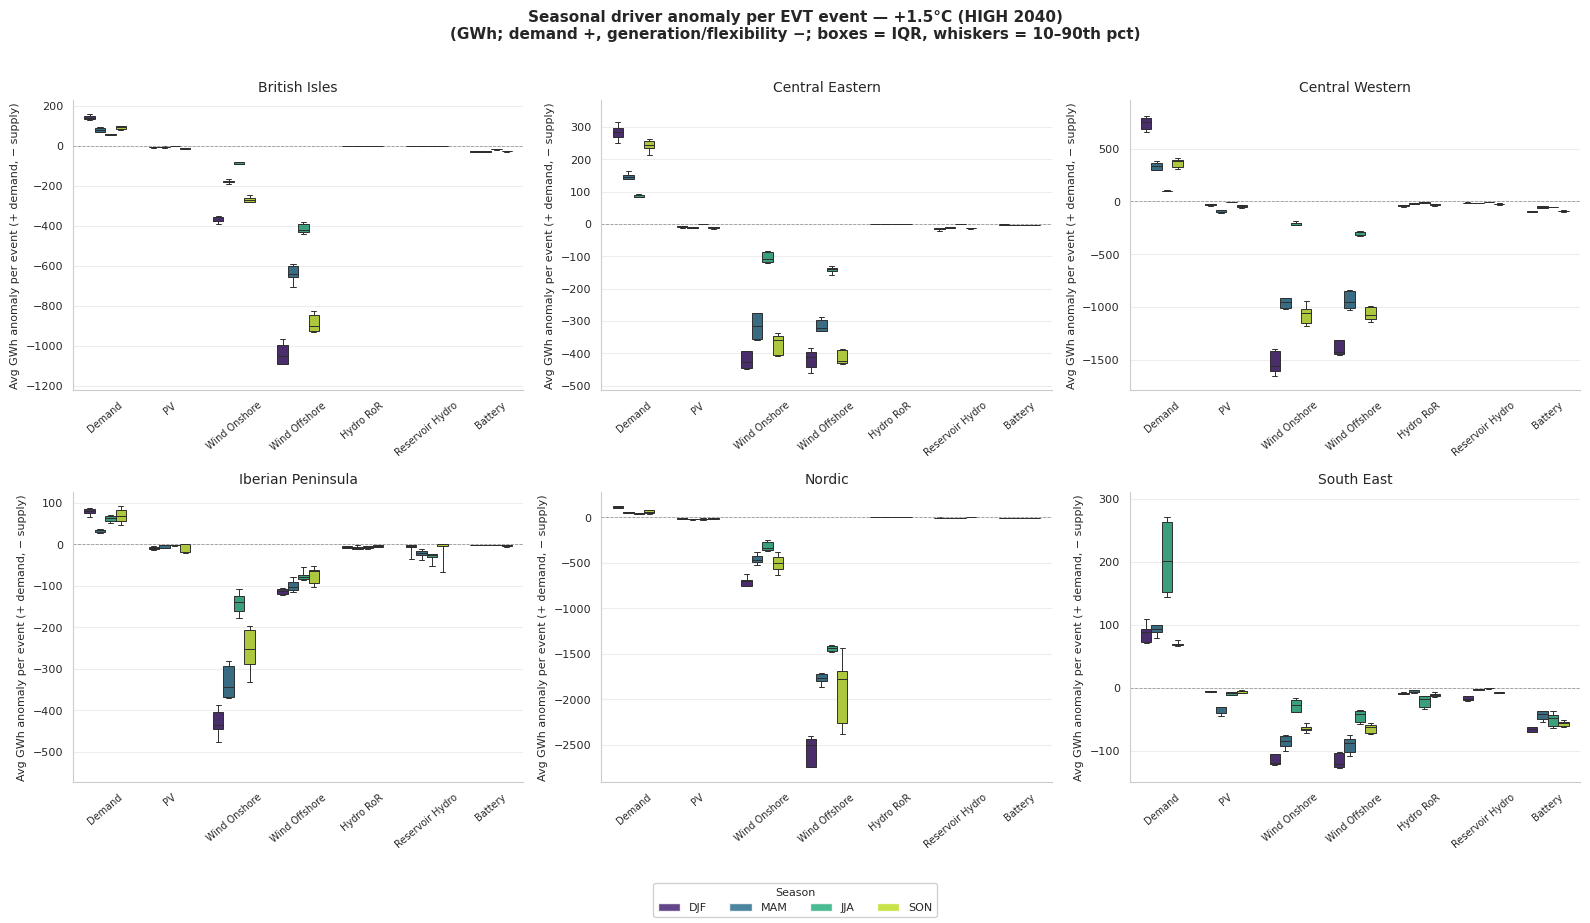

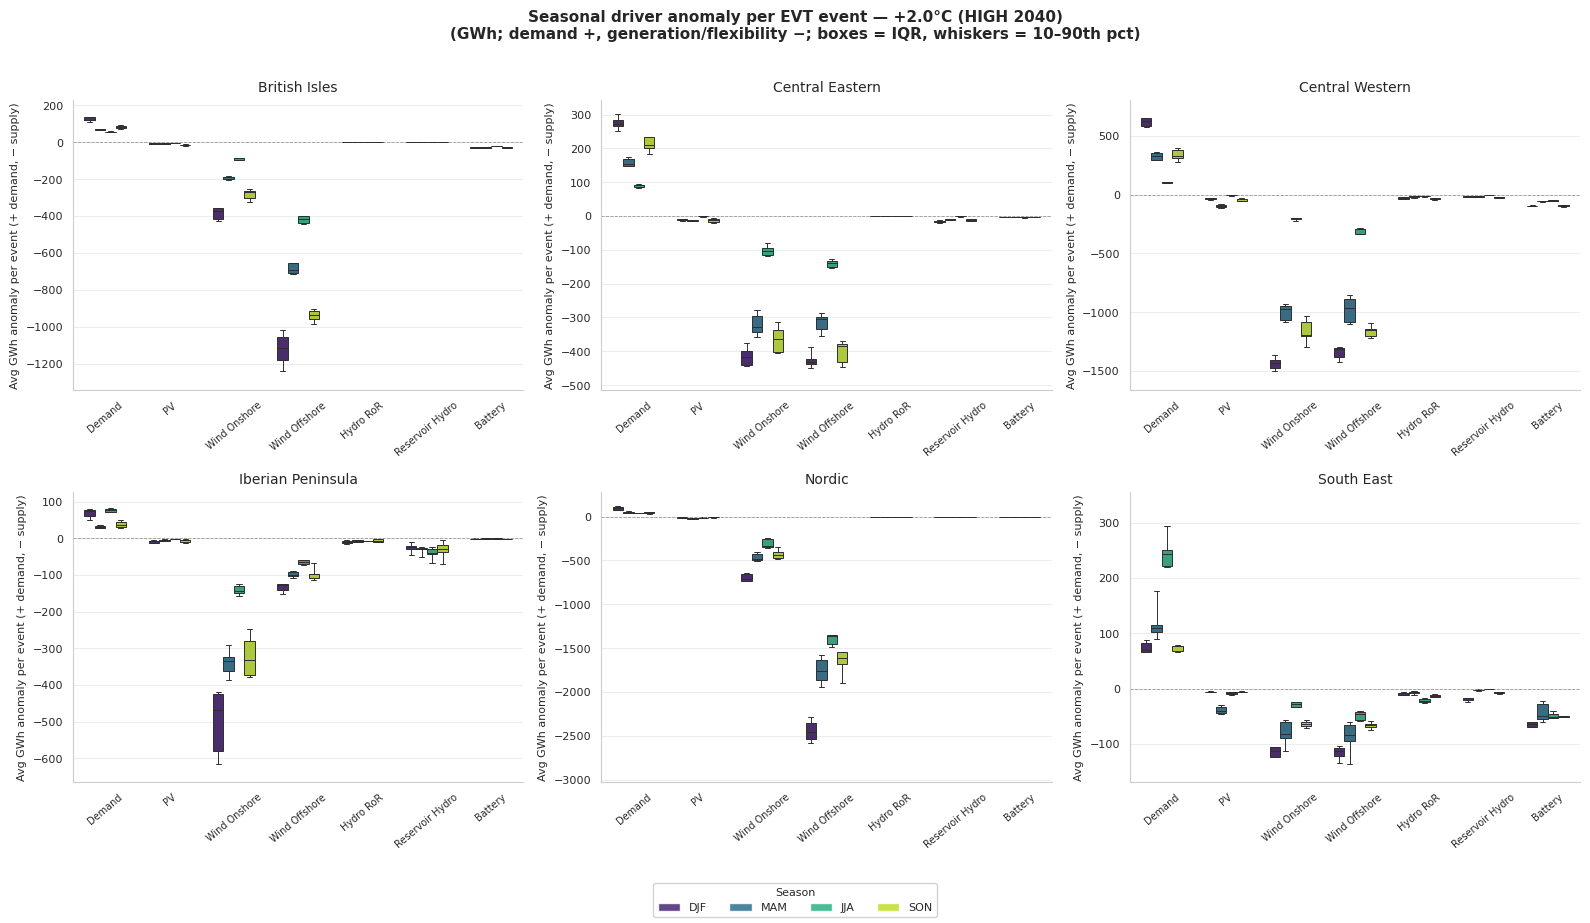

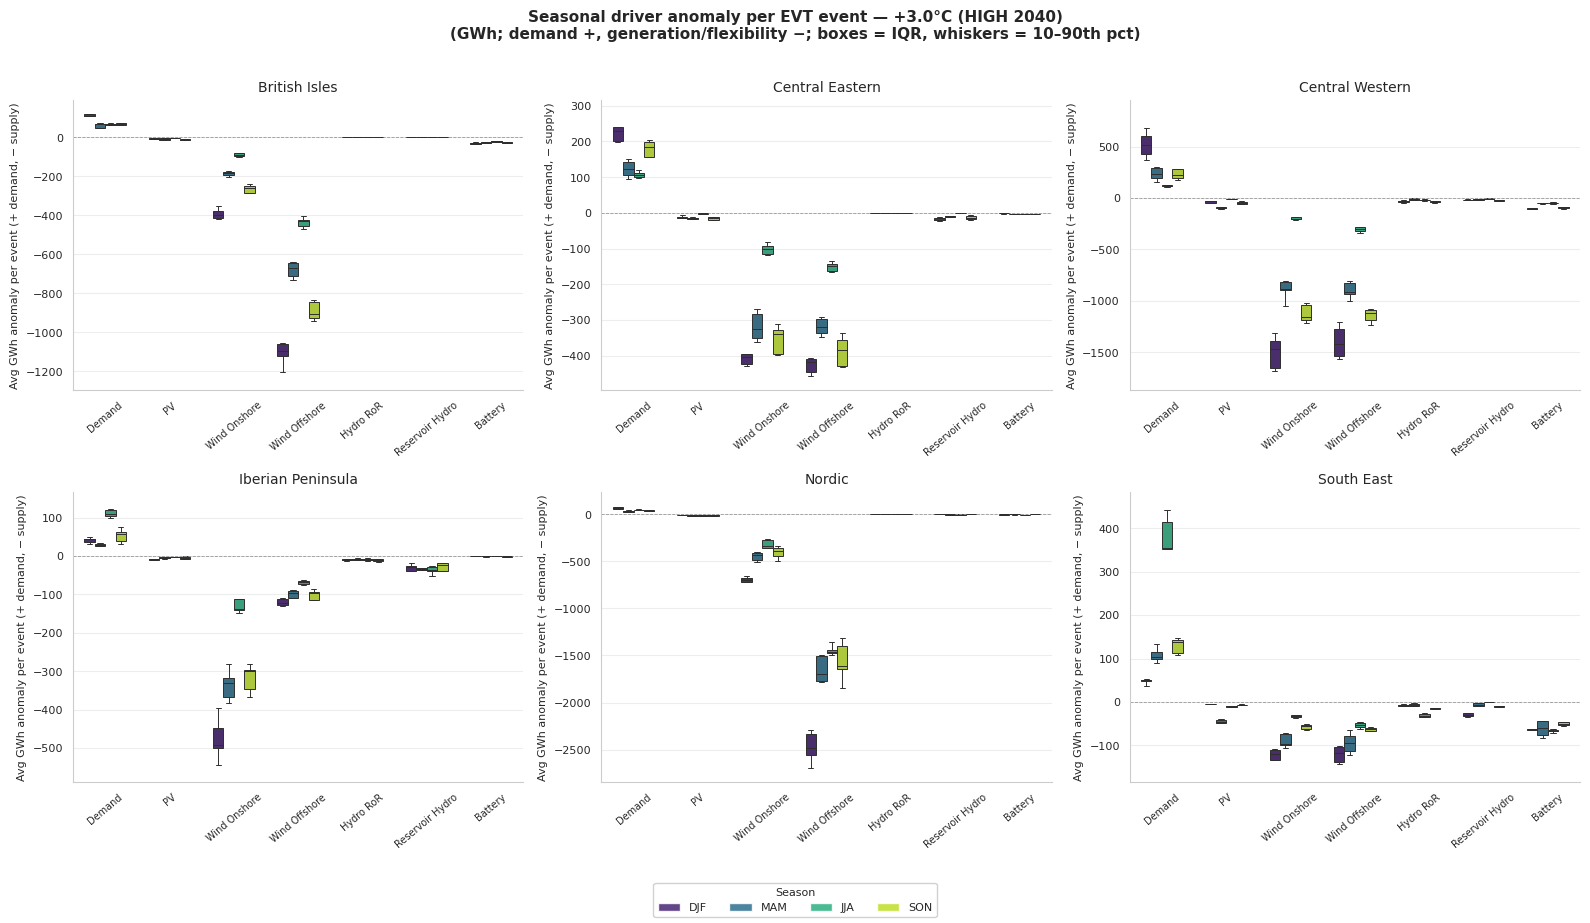

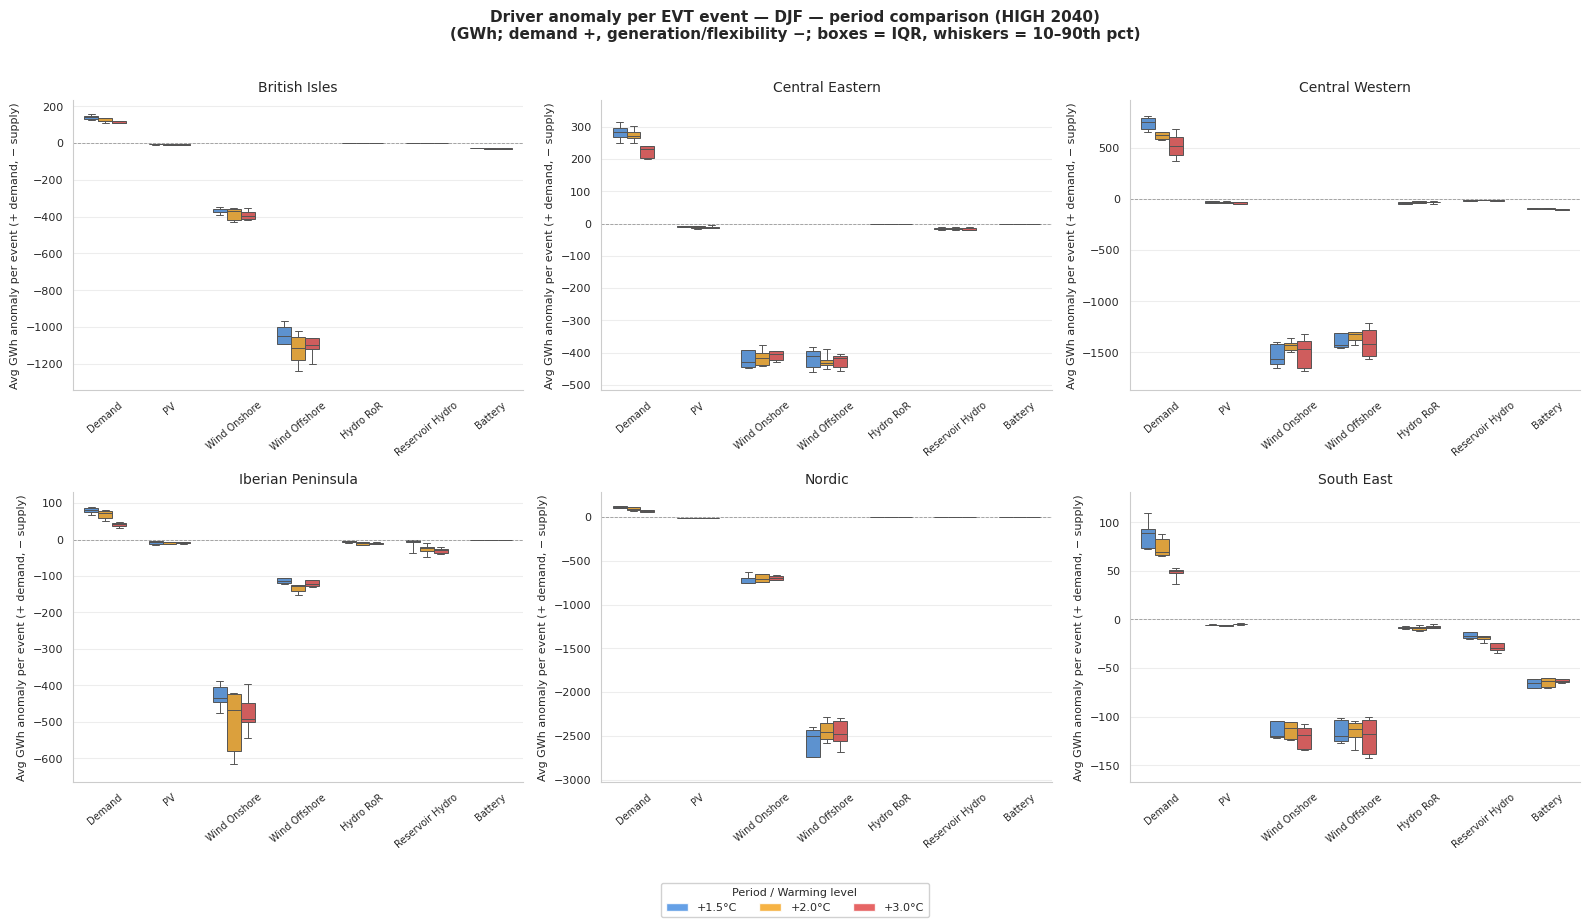

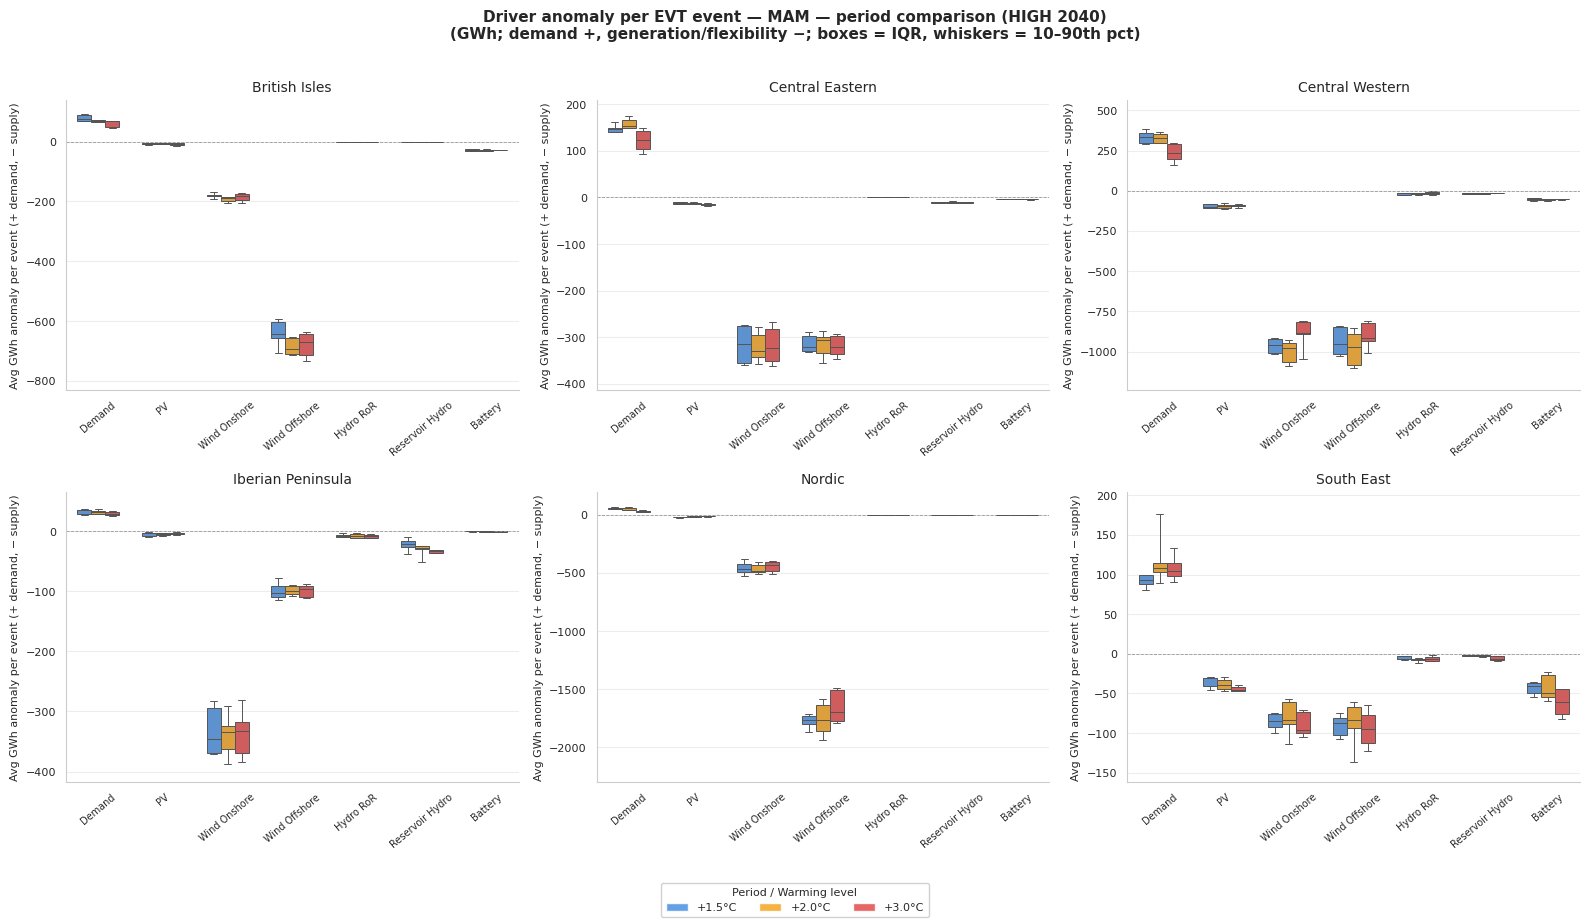

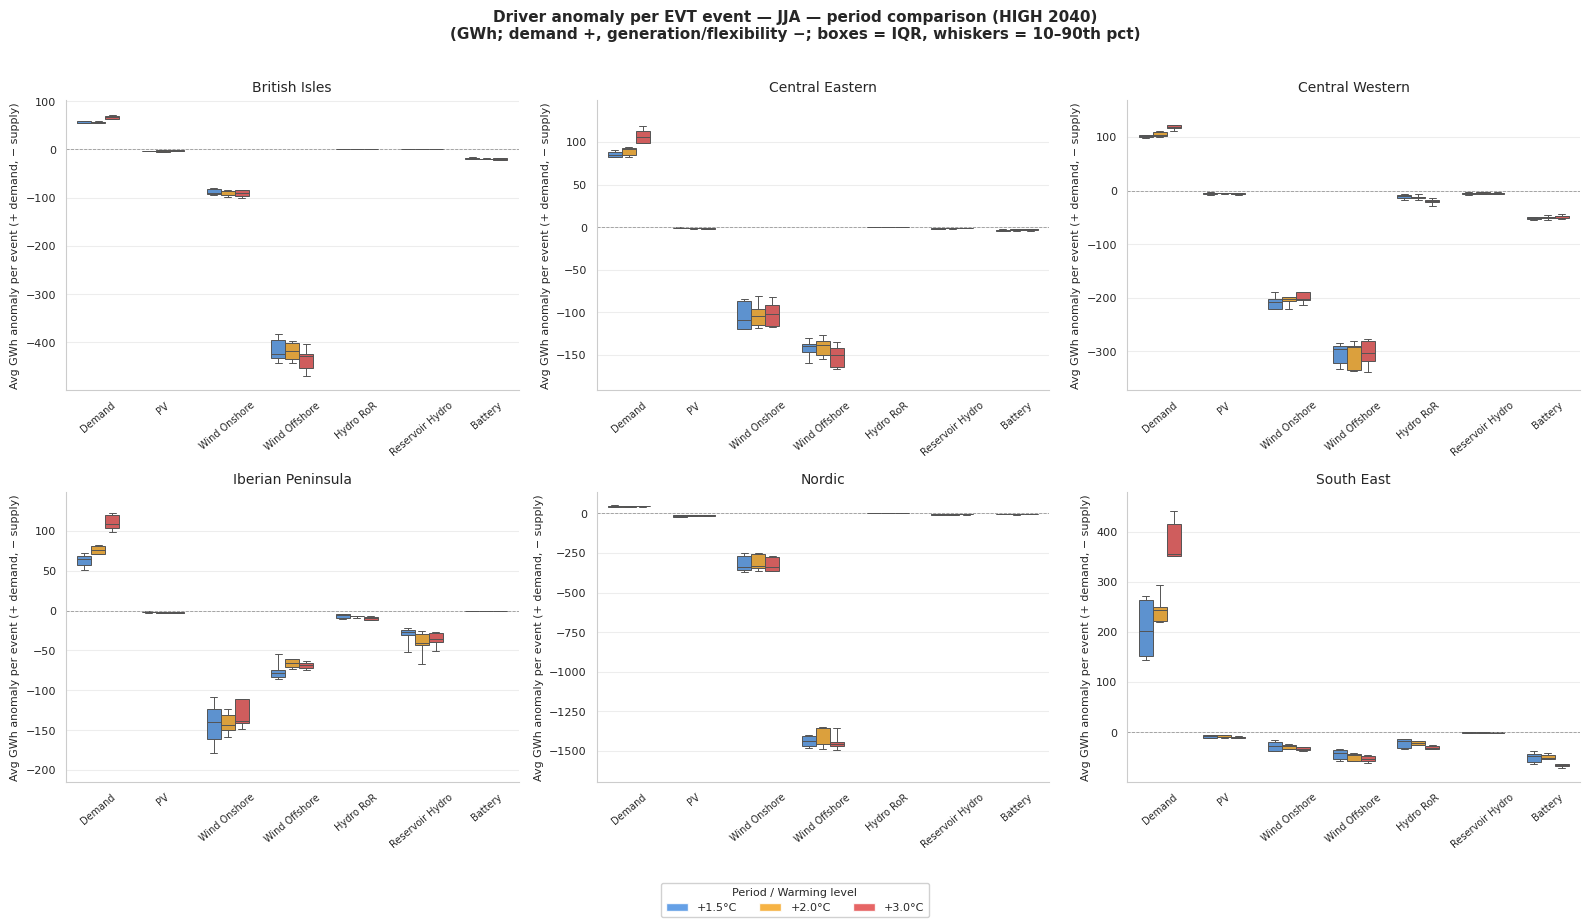

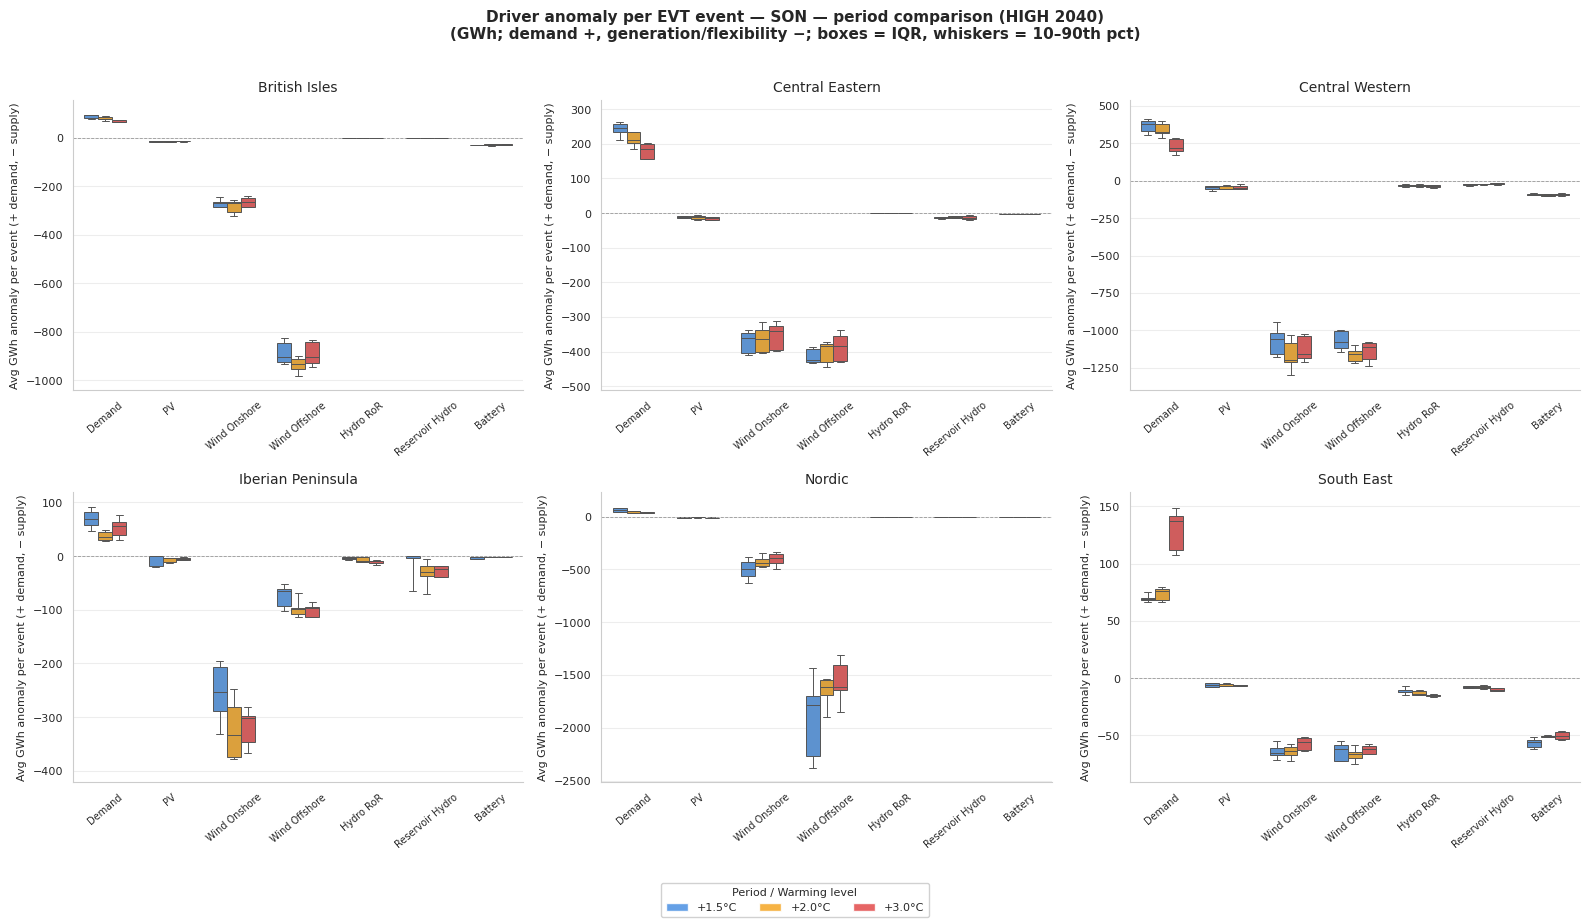


── Driver anomaly distributions (seasonal): 'multi_day' events


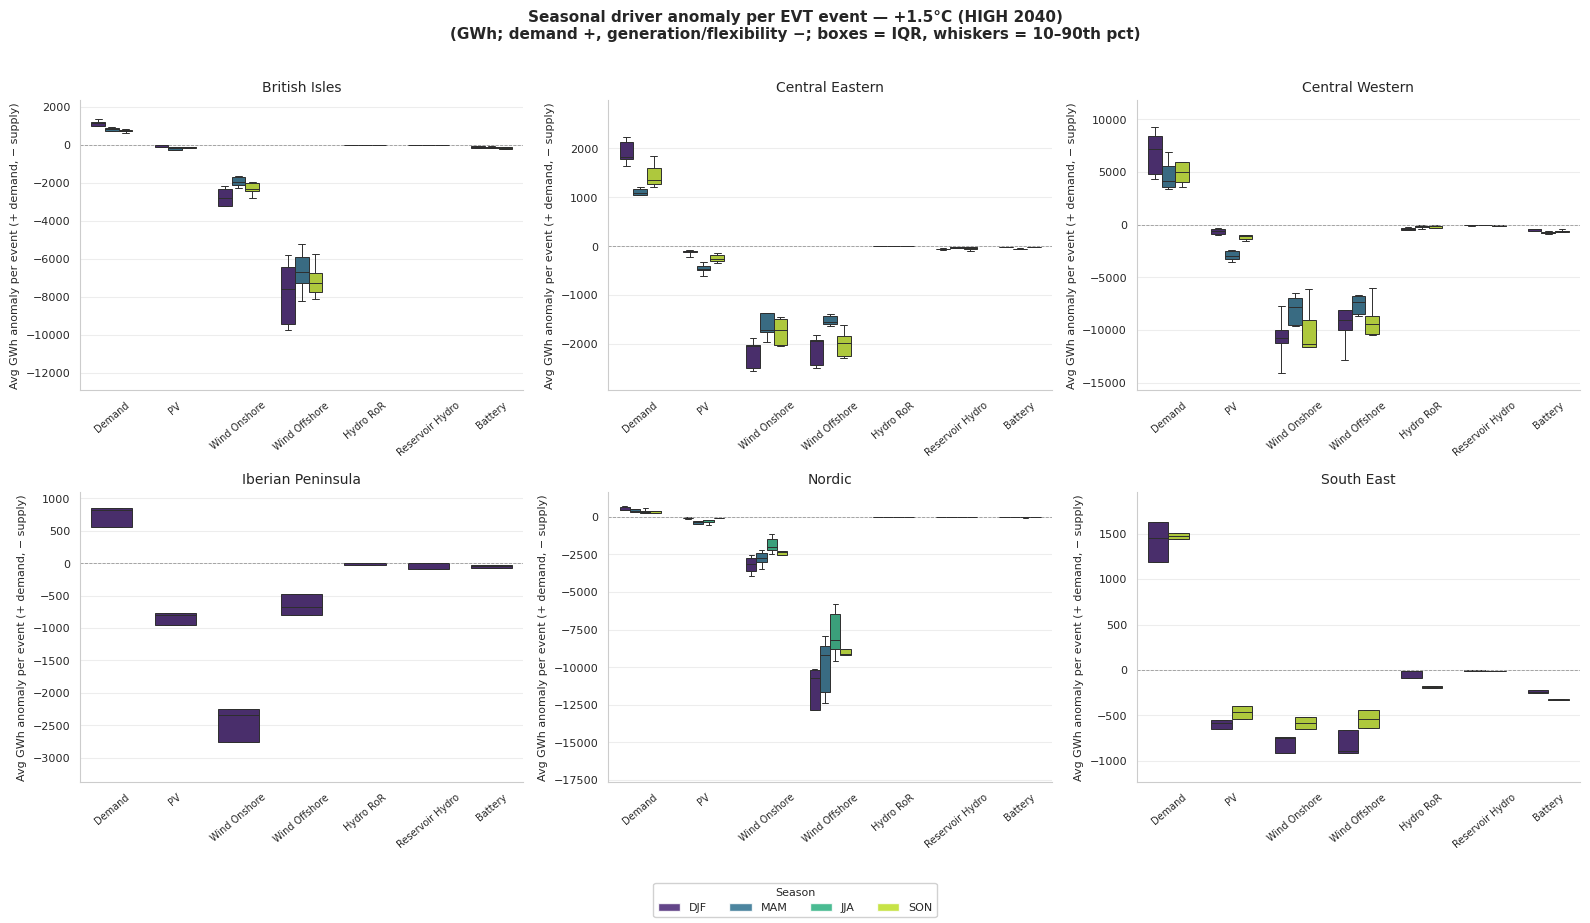

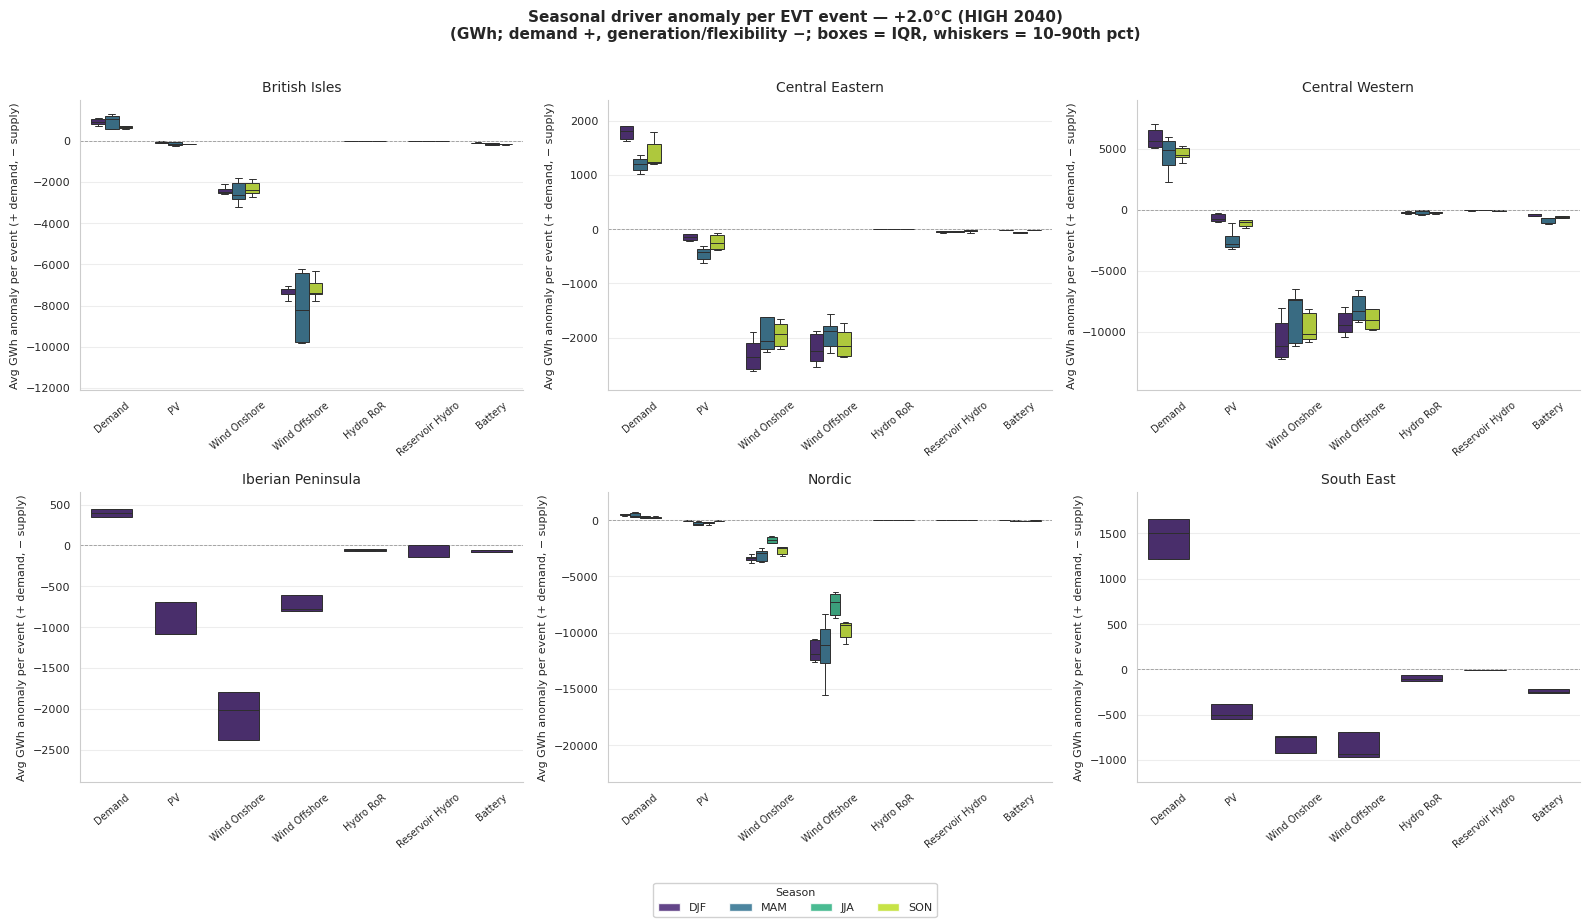

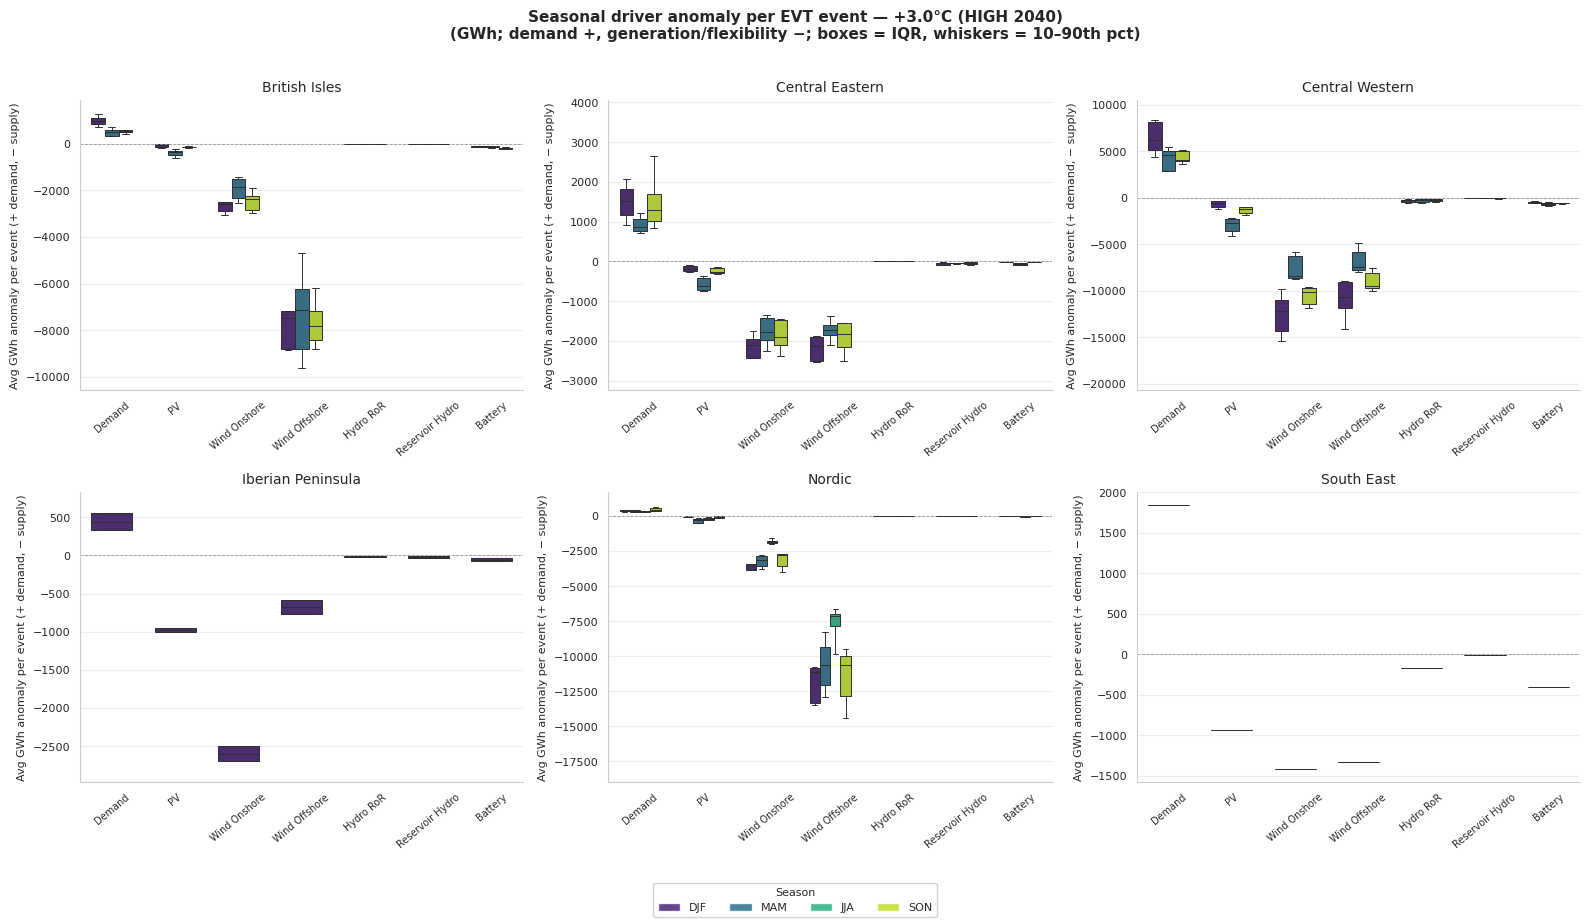

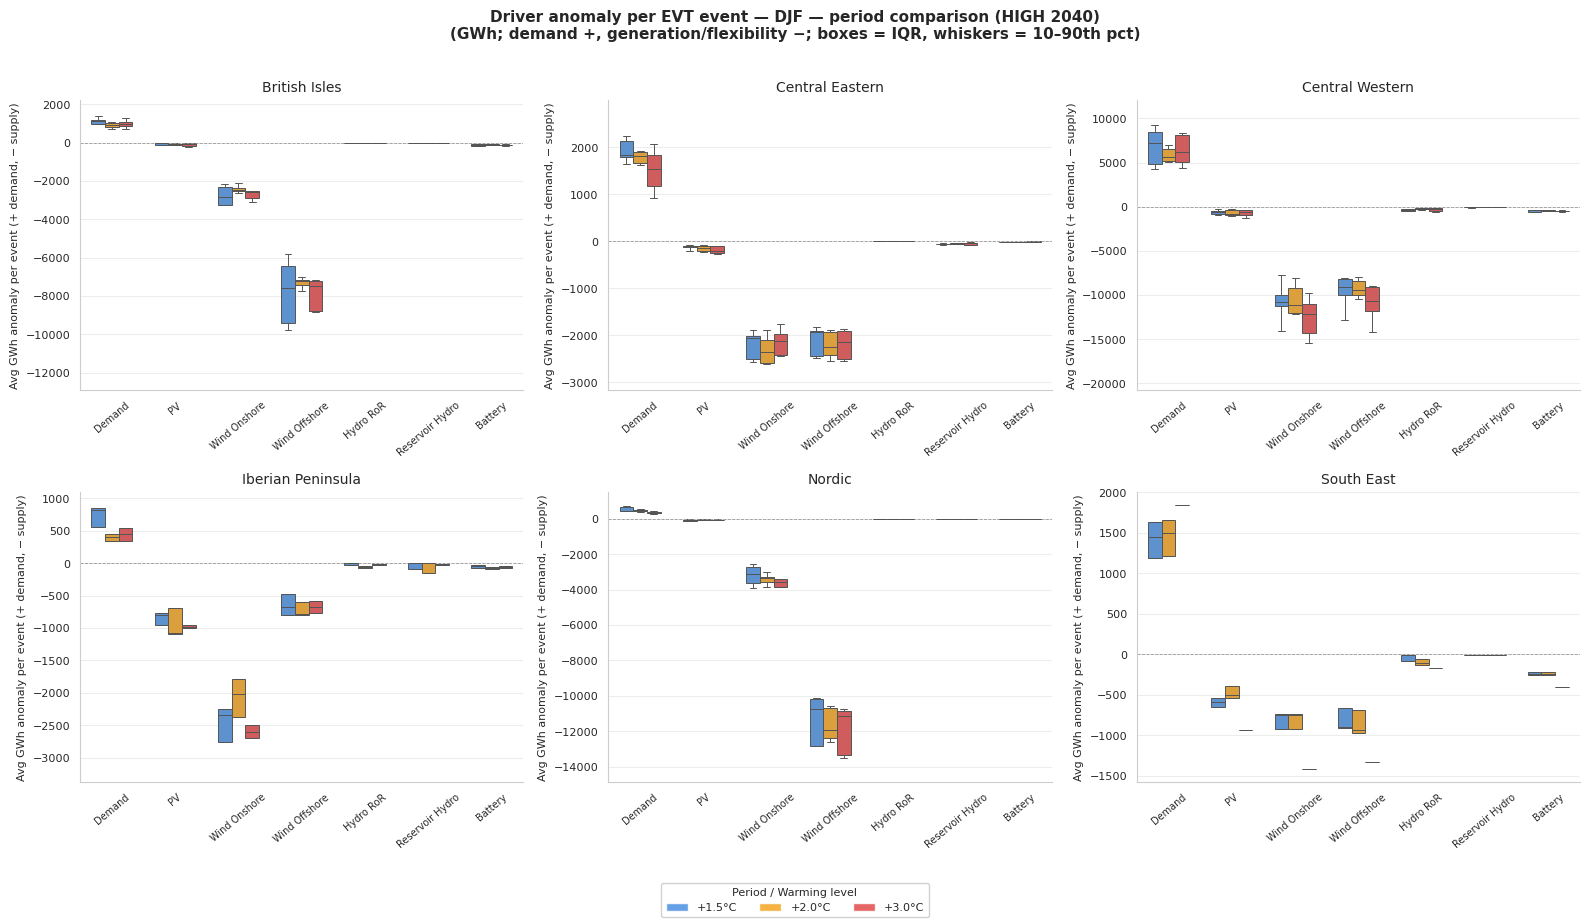

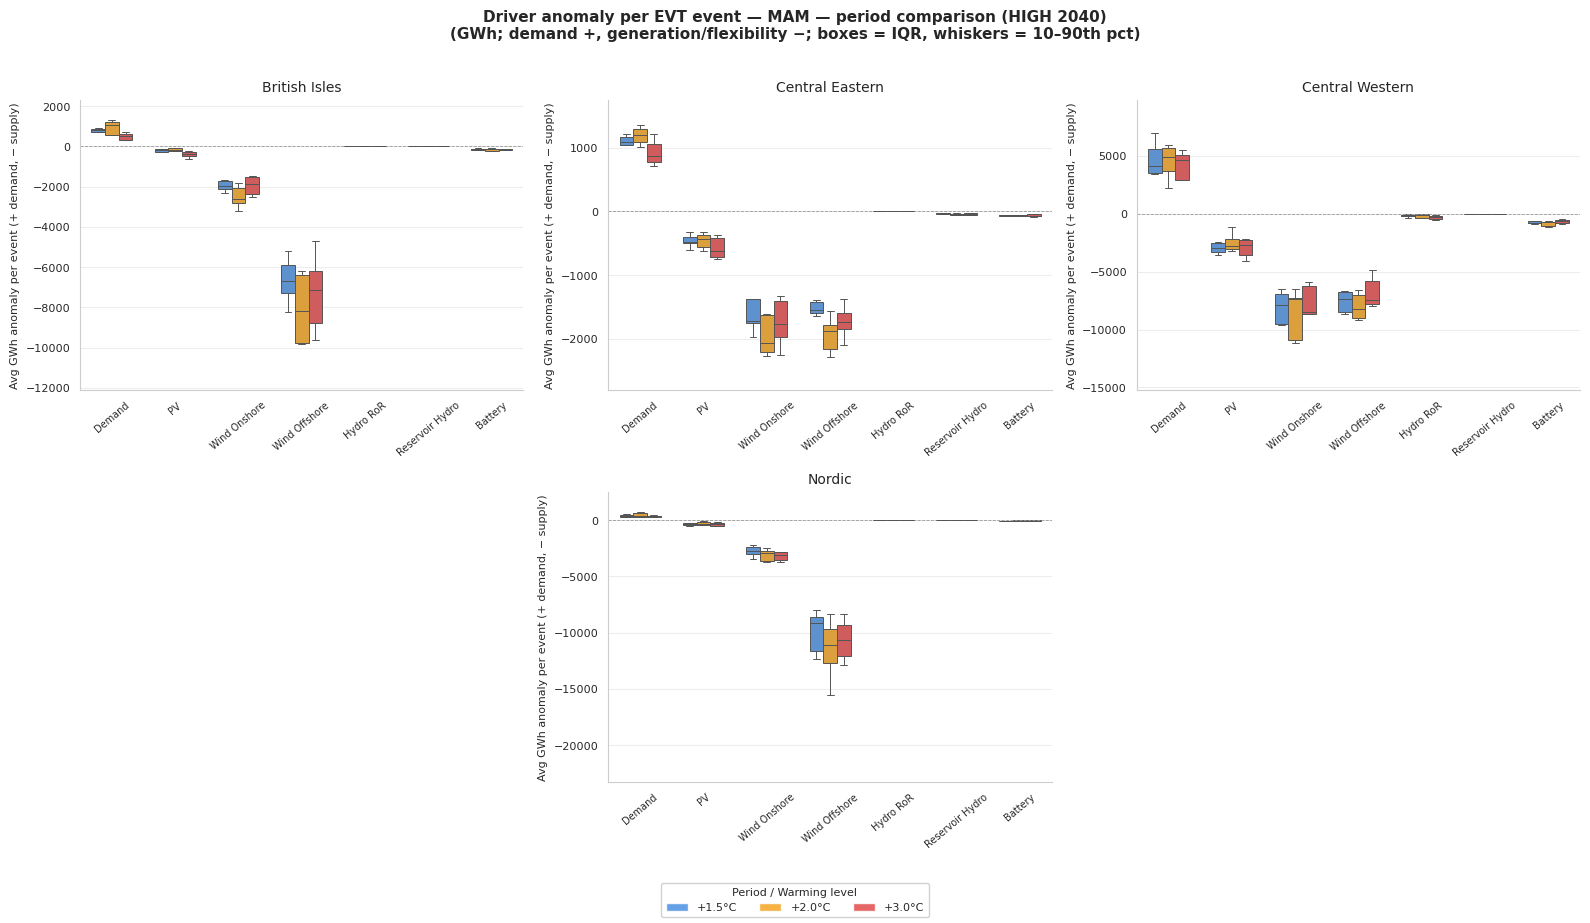

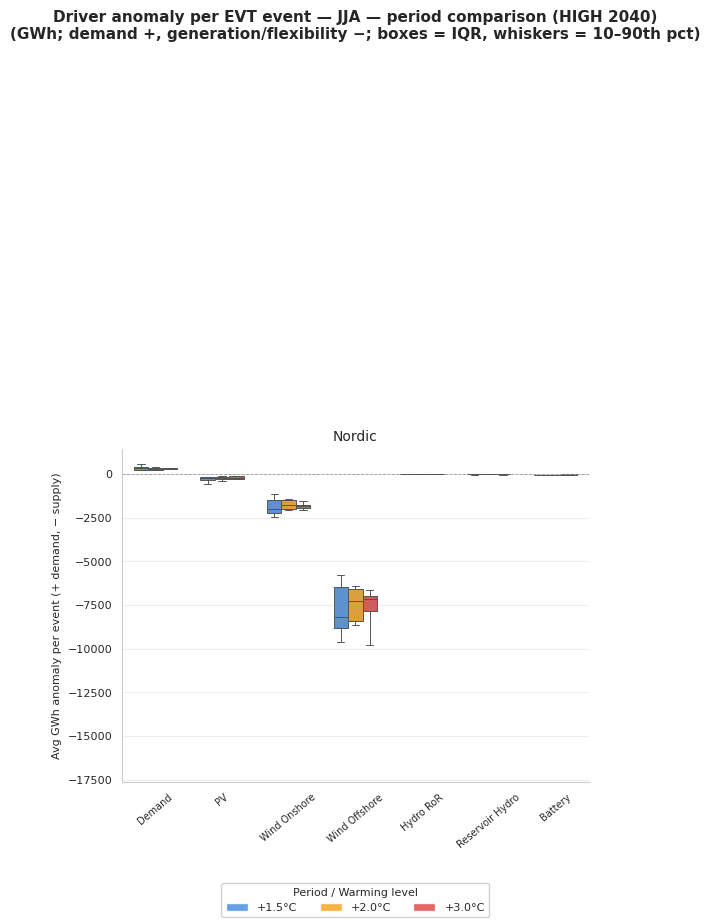

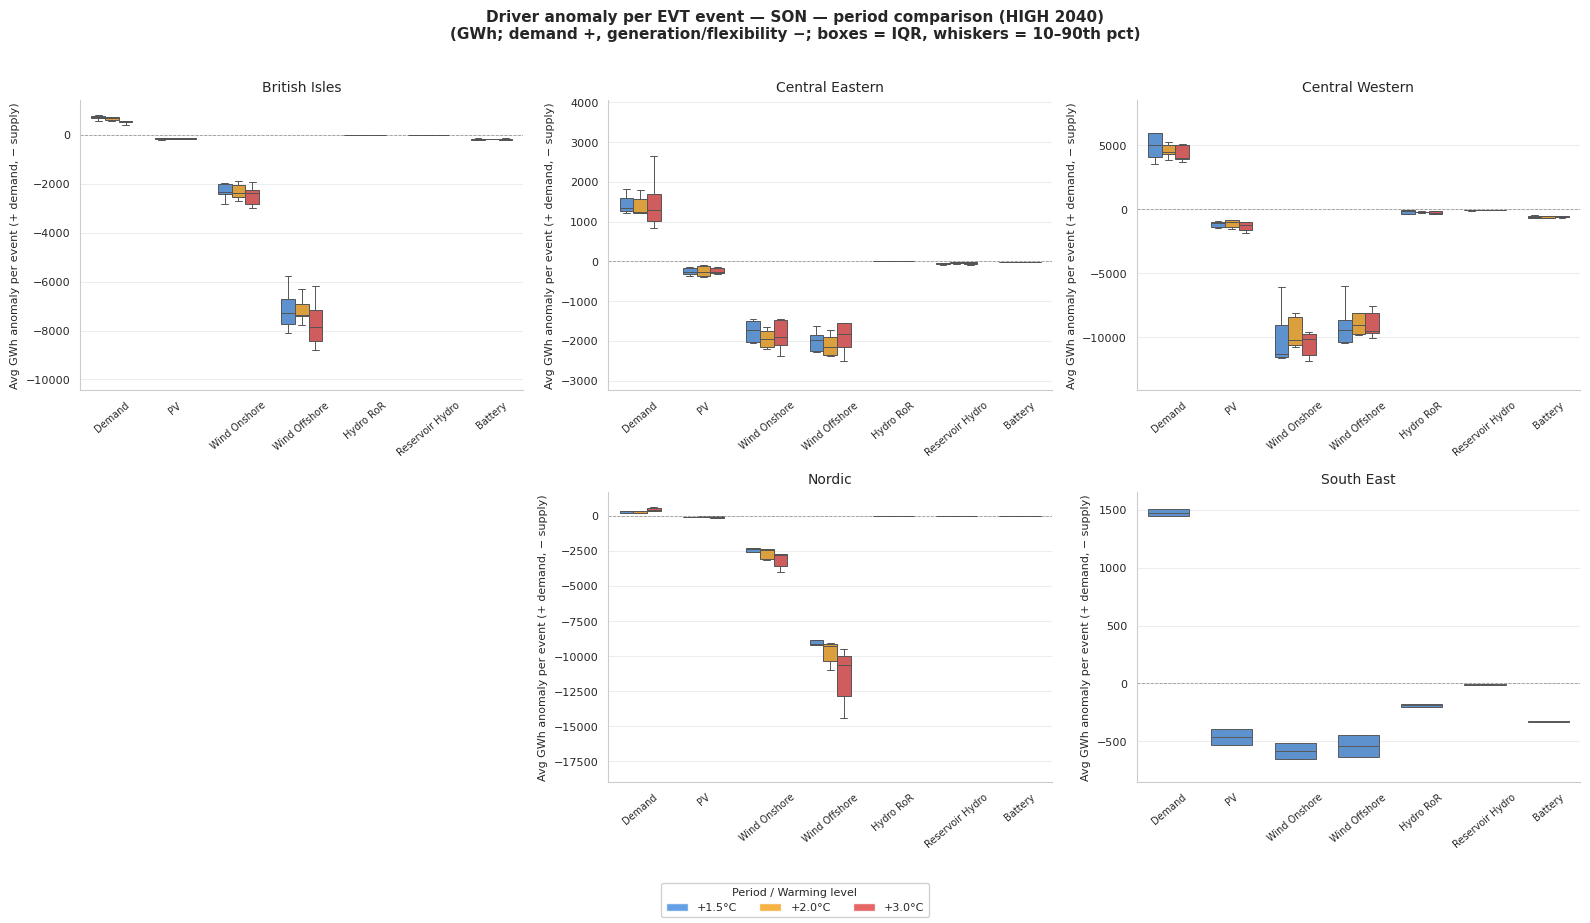

In [36]:
for dc in DURATION_CLASS_ORDER:
    df_dc = df_seasonal[
        (df_seasonal["duration_class"] == dc) & (df_seasonal["n_events"] > 0)
    ].copy()
    if df_dc.empty:
        print(f"  [skip {dc}: no events]")
        continue
    print(f"\n── Driver anomaly distributions (seasonal): '{dc}' events")
    plot_seasonal_component_anomaly_distributions(
        df_dc,
        zones=zones,
        season_order=season_order,
        period_defs=period_defs,
        component_cols=anomaly_component_cols,
        component_palette=driver_palette,
        period_palette=period_colors,
        supply_scenario=supply_scenario,
        supply_year=supply_year,
    )

## B4 — Season × duration-class heatmap: event fraction

For each zone and warming level: what fraction of events in each (season, duration_class)
cell relative to total events in that zone/period?  This summarises the joint
season–duration structure in one panel.

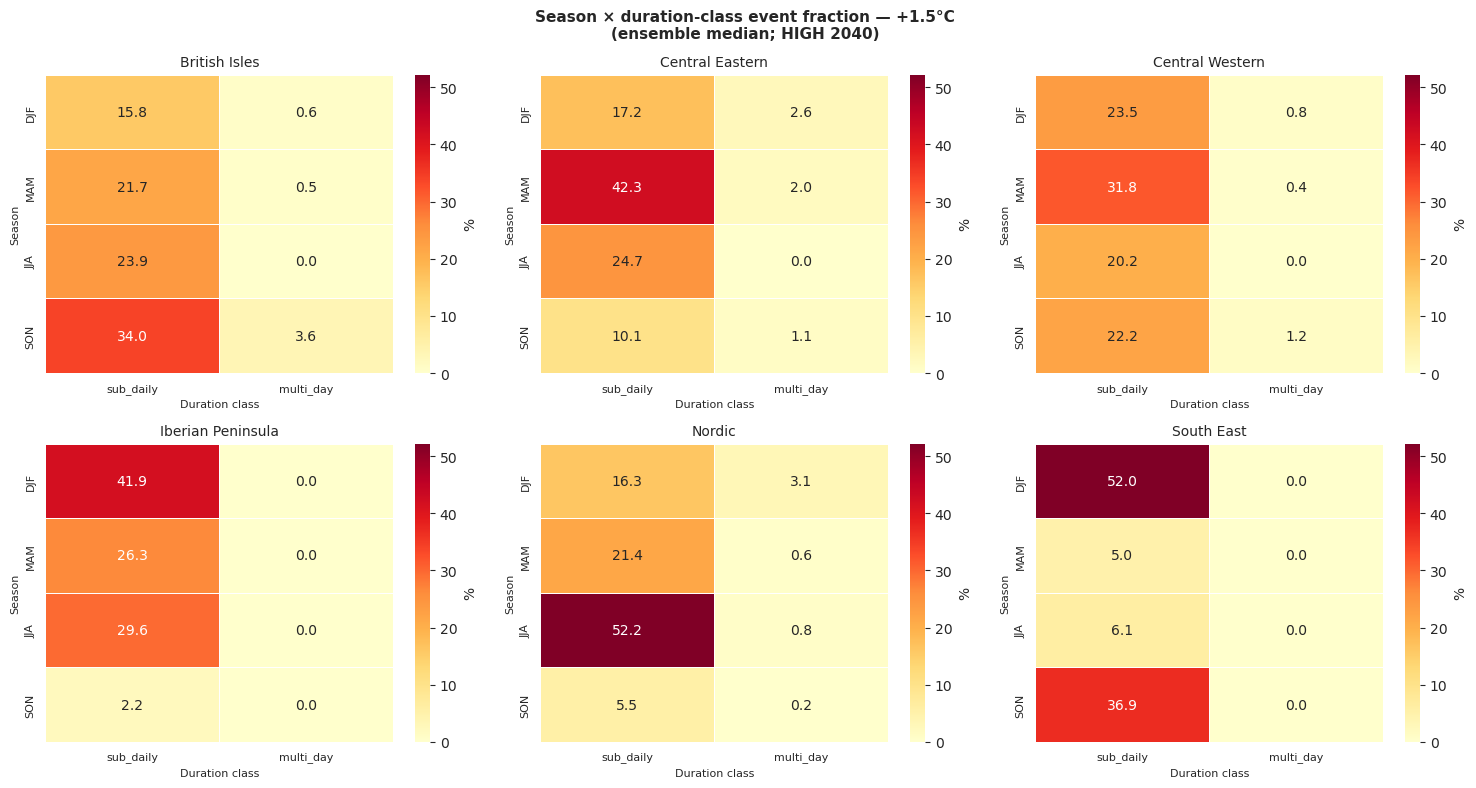

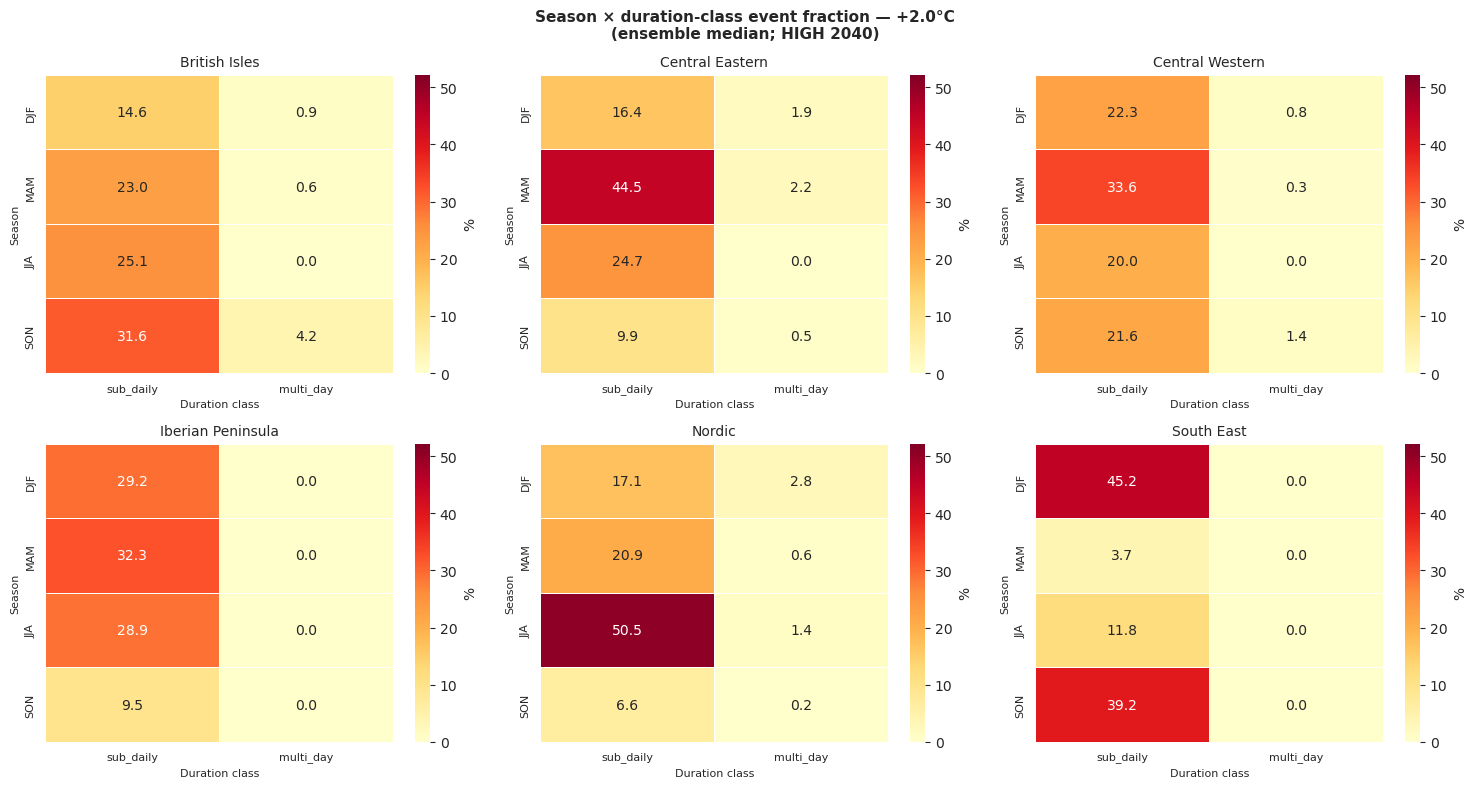

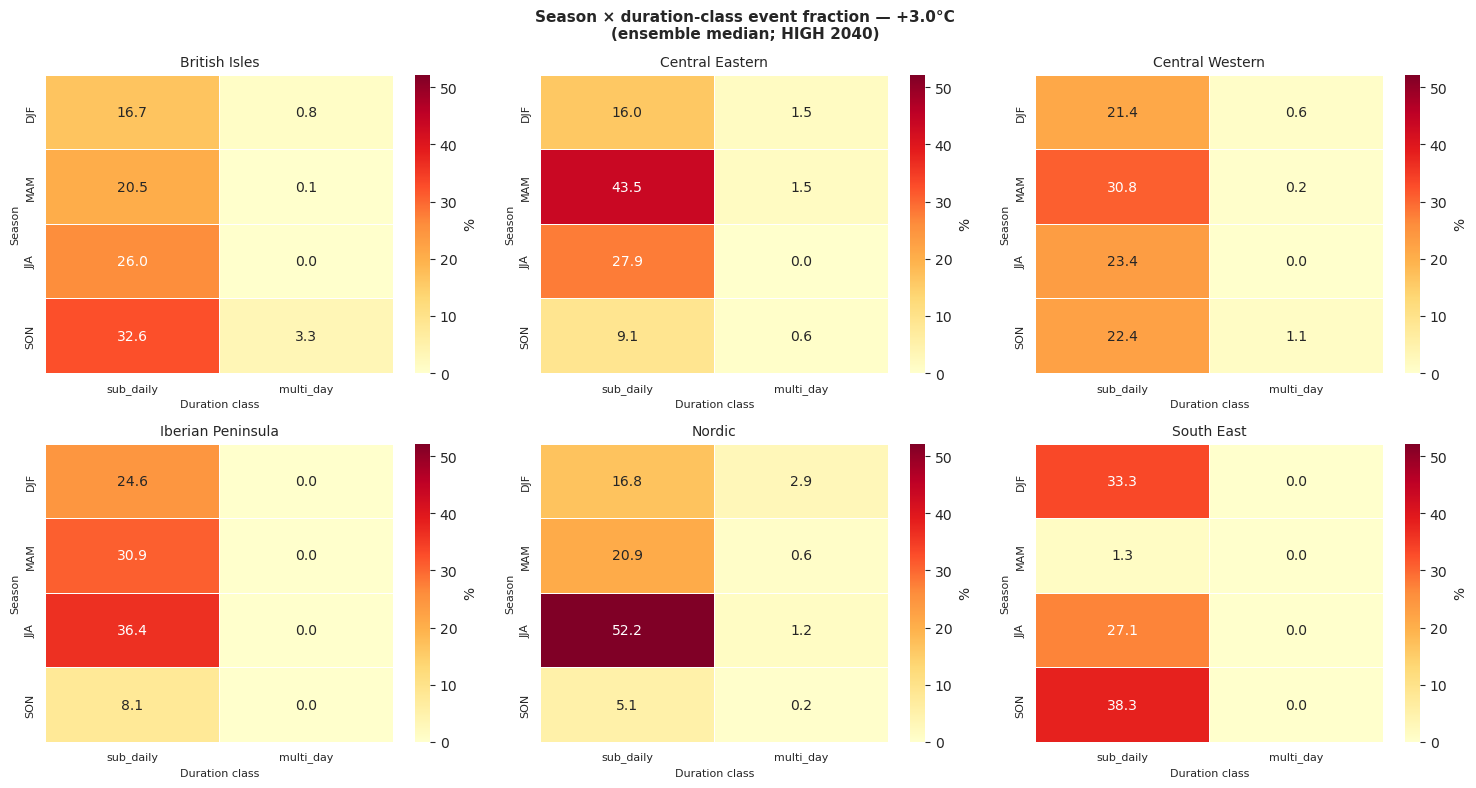

In [40]:
# Pre-compute all pivots to establish a single global vmax across periods and zones
_pct_count = {}
for _pn in list(period_defs.keys()):
    df_p = df_seasonal[df_seasonal["period"] == _pn]
    for _z in zones:
        df_z = df_p[df_p["zone"] == str(_z)]
        pivot = (
            df_z.groupby(["season", "duration_class"])["n_events"]
            .median()
            .unstack("duration_class")
            .reindex(index=season_order, columns=DURATION_CLASS_ORDER, fill_value=0)
        )
        total = pivot.values.sum()
        _pct_count[(_pn, str(_z))] = pivot / total * 100 if total > 0 else pivot * 0

_vmax_count = float(np.nanmax([v.values.max() for v in _pct_count.values()]))

for period_name in list(period_defs.keys()):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    fig.suptitle(
        f"Season × duration-class event fraction — {period_name}\n"
        f"(ensemble median; {supply_scenario} {supply_year})",
        fontsize=11, fontweight="bold",
    )

    for ax, zone in zip(axes.flat, zones):
        pct = _pct_count[(period_name, str(zone))]
        sns.heatmap(
            pct, ax=ax, annot=True, fmt=".1f", cmap="YlOrRd",
            vmin=0, vmax=_vmax_count,
            cbar_kws={"label": "%"},
            linewidths=0.5, linecolor="white",
        )
        ax.set_title(str(zone).replace("_", " "), fontsize=10)
        ax.set_xlabel("Duration class", fontsize=8)
        ax.set_ylabel("Season", fontsize=8)
        ax.tick_params(labelsize=8)

    plt.tight_layout()
    plt.show()

## B5 — Severity-weighted duration-class composition by season

Same concept as B4 but weighted by **total annual energy severity** rather than event count.
Reveals which duration class drives the bulk of unserved energy within each season.

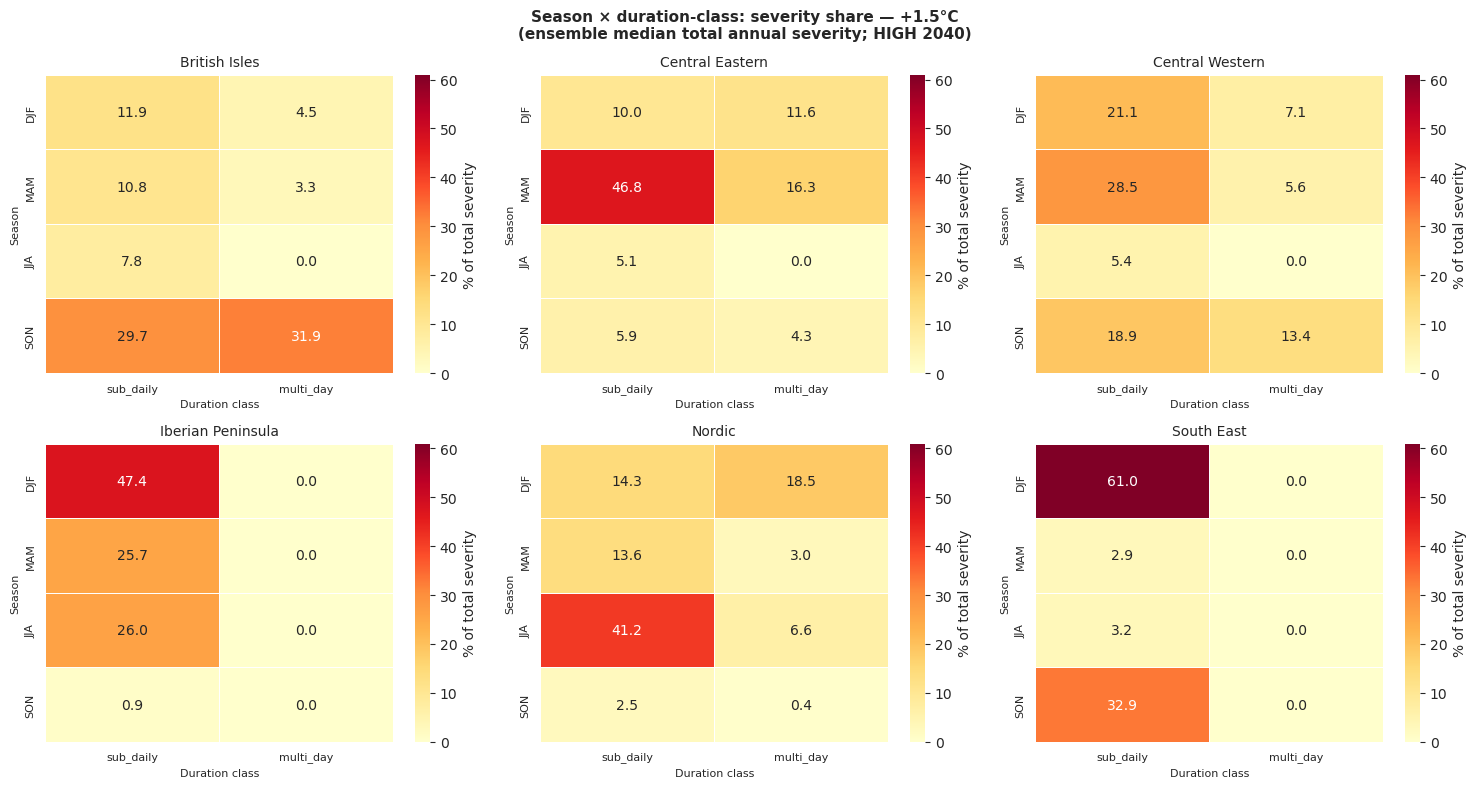

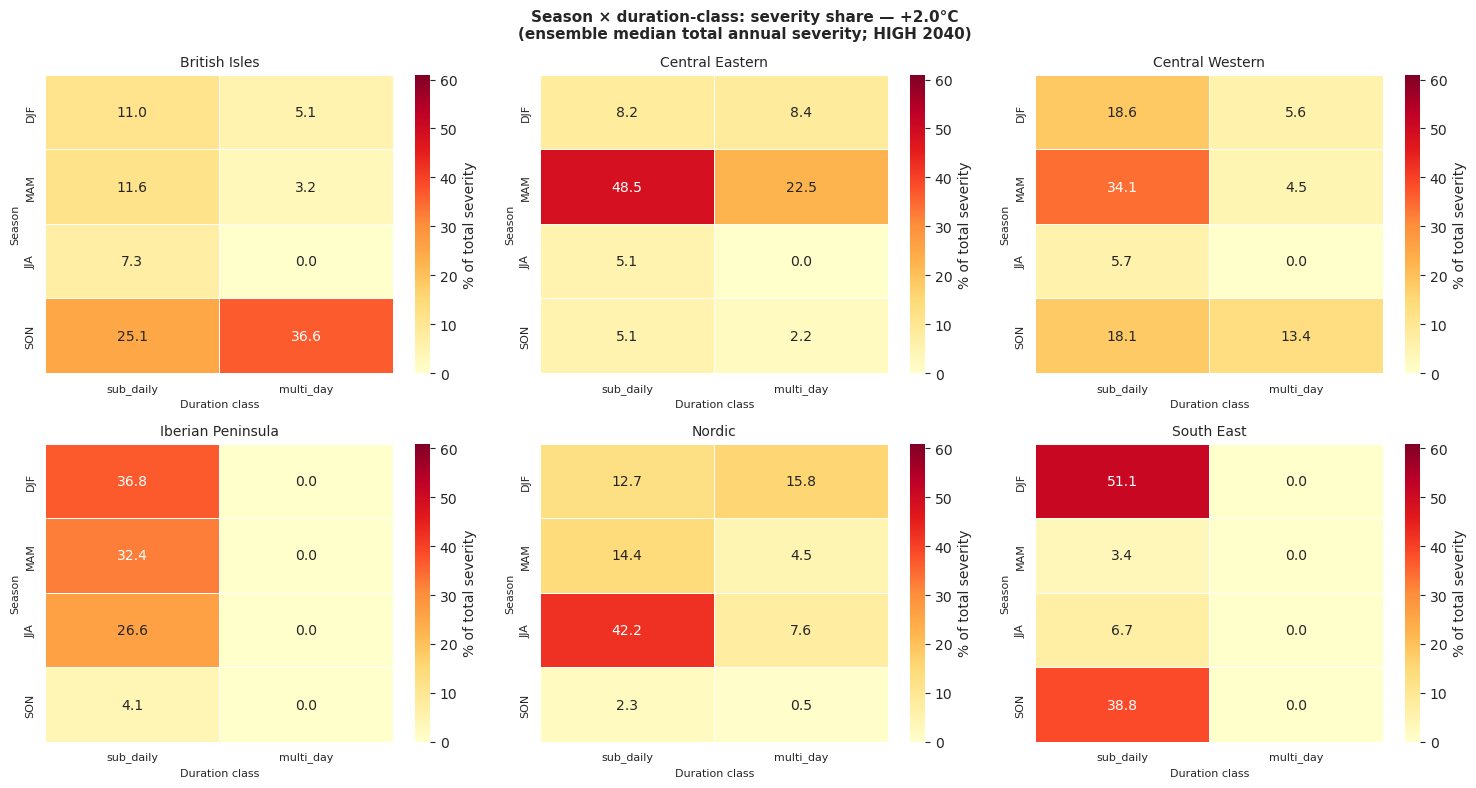

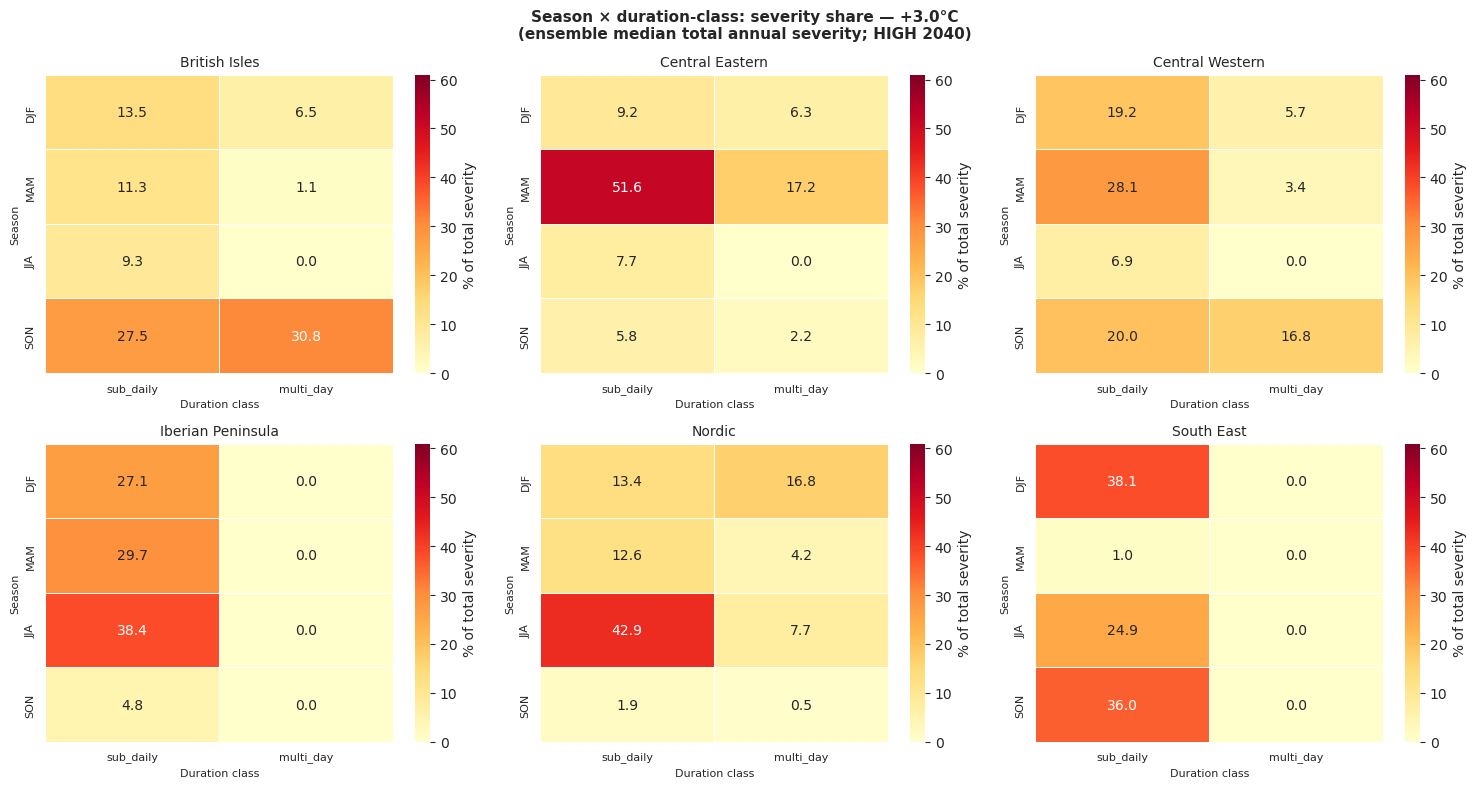

In [41]:
# Pre-compute all pivots to establish a single global vmax across periods and zones
_pct_sev = {}
for _pn in list(period_defs.keys()):
    df_p = df_seasonal[df_seasonal["period"] == _pn]
    for _z in zones:
        df_z = df_p[df_p["zone"] == str(_z)]
        pivot = (
            df_z.groupby(["season", "duration_class"])["total_annual_severity_gwh"]
            .median()
            .unstack("duration_class")
            .reindex(index=season_order, columns=DURATION_CLASS_ORDER, fill_value=0)
        )
        total = pivot.values.sum()
        _pct_sev[(_pn, str(_z))] = pivot / total * 100 if total > 0 else pivot * 0

_vmax_sev = float(np.nanmax([v.values.max() for v in _pct_sev.values()]))

for period_name in list(period_defs.keys()):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    fig.suptitle(
        f"Season × duration-class: severity share — {period_name}\n"
        f"(ensemble median total annual severity; {supply_scenario} {supply_year})",
        fontsize=11, fontweight="bold",
    )

    for ax, zone in zip(axes.flat, zones):
        pct = _pct_sev[(period_name, str(zone))]
        sns.heatmap(
            pct, ax=ax, annot=True, fmt=".1f", cmap="YlOrRd",
            vmin=0, vmax=_vmax_sev,
            cbar_kws={"label": "% of total severity"},
            linewidths=0.5, linecolor="white",
        )
        ax.set_title(str(zone).replace("_", " "), fontsize=10)
        ax.set_xlabel("Duration class", fontsize=8)
        ax.set_ylabel("Season", fontsize=8)
        ax.tick_params(labelsize=8)

    plt.tight_layout()
    plt.show()

---
# Section C — Significance and robustness

With only 9 GCM-RCM chains the ensemble is too small for conventional frequentist
inference on individual model runs, but three complementary approaches provide
meaningful robustness information:

| Test | What it measures | Appropriate for |
|---|---|---|
| **Ensemble agreement (sign test)** | Fraction of models showing the same direction of change | All metrics; shown as stippling in B1b |
| **Wilcoxon signed-rank (paired)** | Whether the paired ref → comp differences are systematically non-zero across models | n_events, severity, driver shares |
| **Leave-one-out (LOO) stability** | Whether any single GCM-RCM chain dominates the ensemble median signal | Zones where agreement is borderline |
| **Duration-bin sensitivity** | Whether key conclusions change if the sub_daily / multi_day boundary is shifted ±6 h | All duration-class comparisons |

**Interpretation guidance:**
- Stippled cells (B1b) = signal direction is not robust: fewer than 7/9 models agree.
- *p* < 0.05 (Wilcoxon, two-sided) = the shift in distribution between warming levels is
  statistically detectable at ensemble scale, but with *n* = 9 this requires near-unanimous agreement.
- LOO range narrower than the ensemble IQR → no single model is an outlier driver.
- Conclusions stable across ±6 h boundary shift → not artefacts of the 24 h cut.

## C1 — Wilcoxon signed-rank tests and ensemble agreement table

In [44]:
from scipy import stats as _stats

_sig_rows = []
_metrics  = ["n_events", "avg_severity_gwh", "total_annual_severity_gwh"]
_period_names_c = list(period_defs.keys())
_ref_c          = _period_names_c[0]
_comps_c        = [p for p in _period_names_c if p != _ref_c]

for dc in DURATION_CLASS_ORDER:
    df_dc = df_seasonal[df_seasonal["duration_class"] == dc]
    for zone in zones:
        for season in season_order:
            for comp in _comps_c:
                for metric in _metrics:
                    ref_s = (
                        df_dc[(df_dc["zone"] == str(zone)) & (df_dc["season"] == season)
                              & (df_dc["period"] == _ref_c)]
                        .set_index("model")[metric]
                    )
                    cmp_s = (
                        df_dc[(df_dc["zone"] == str(zone)) & (df_dc["season"] == season)
                              & (df_dc["period"] == comp)]
                        .set_index("model")[metric]
                    )
                    common = ref_s.index.intersection(cmp_s.index)
                    if len(common) < 3:
                        continue
                    x_ref  = ref_s.loc[common].values.astype(float)
                    x_comp = cmp_s.loc[common].values.astype(float)
                    diffs  = x_comp - x_ref
                    n_pos  = int((diffs > 0).sum())
                    n_neg  = int((diffs < 0).sum())
                    n_tot  = len(common)
                    agree_n = max(n_pos, n_neg)

                    try:
                        _, pval = _stats.wilcoxon(x_comp, x_ref, alternative="two-sided")
                    except Exception:
                        pval = np.nan

                    med_ref  = float(np.median(x_ref))
                    med_comp = float(np.median(x_comp))
                    pct_chg  = (med_comp - med_ref) / med_ref * 100 if med_ref > 0 else np.nan

                    _sig_rows.append({
                        "duration_class": dc,
                        "zone":           str(zone),
                        "season":         season,
                        "comparison":     f"{_ref_c}→{comp}",
                        "metric":         metric,
                        "median_ref":     med_ref,
                        "median_comp":    med_comp,
                        "pct_change":     pct_chg,
                        "n_agree":        agree_n,
                        "n_models":       n_tot,
                        "agree_frac":     agree_n / n_tot,
                        "p_wilcoxon":     pval,
                        "robust_7of9":    agree_n >= 7,
                        "sig_05":         pval < 0.05 if not np.isnan(pval) else False,
                    })

df_sig = pd.DataFrame(_sig_rows)
print(f"Total tests: {len(df_sig)}")

# Summary: robust AND significant results for n_events
_summary = (
    df_sig[(df_sig["metric"] == "n_events") & df_sig["robust_7of9"] & df_sig["sig_05"]]
    [["duration_class", "zone", "season", "comparison", "pct_change", "n_agree", "p_wilcoxon"]]
    .sort_values(["duration_class", "comparison", "pct_change"])
    .reset_index(drop=True)
)
print(f"\nRobust (≥7/9 models) AND significant (p<0.05) n_events changes:")
_summary.style.format({"pct_change": "{:+.1f}%", "p_wilcoxon": "{:.3f}"})

/home/yhaddad/.conda/envs/c2e-analysis/lib/python3.14/site-packages/scipy/stats/_wilcoxon.py:192: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/home/yhaddad/.conda/envs/c2e-analysis/lib/python3.14/site-packages/scipy/stats/_wilcoxon.py:192: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/home/yhaddad/.conda/envs/c2e-analysis/lib/python3.14/site-packages/scipy/stats/_wilcoxon.py:192: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/home/yhaddad/.conda/envs/c2e-analysis/lib/python3.14/site-packages/scipy/stats/_wilcoxon.py:192: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/home/yhaddad/.conda/envs/c2e-analysis/lib/python3.14/site-packages/scipy/stats/_wilcoxon.py:192: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/home/yhaddad/.conda/envs/c2e-analysis/lib/python3.14/site-packages/scipy/stats/_wilcoxon.

Total tests: 288

Robust (≥7/9 models) AND significant (p<0.05) n_events changes:


/home/yhaddad/.conda/envs/c2e-analysis/lib/python3.14/site-packages/scipy/stats/_wilcoxon.py:192: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/home/yhaddad/.conda/envs/c2e-analysis/lib/python3.14/site-packages/scipy/stats/_wilcoxon.py:192: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/home/yhaddad/.conda/envs/c2e-analysis/lib/python3.14/site-packages/scipy/stats/_wilcoxon.py:192: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/home/yhaddad/.conda/envs/c2e-analysis/lib/python3.14/site-packages/scipy/stats/_wilcoxon.py:192: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/home/yhaddad/.conda/envs/c2e-analysis/lib/python3.14/site-packages/scipy/stats/_wilcoxon.py:192: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/home/yhaddad/.conda/envs/c2e-analysis/lib/python3.14/site-packages/scipy/stats/_wilcoxon.

,duration_class,zone,season,comparison,pct_change,n_agree,p_wilcoxon
0,multi_day,Central_Eastern,SON,+1.5°C→+2.0°C,-57.1%,8,0.008
1,multi_day,Central_Eastern,SON,+1.5°C→+3.0°C,-57.1%,8,0.008
2,multi_day,Central_Eastern,DJF,+1.5°C→+3.0°C,-50.0%,9,0.004
3,sub_daily,South_East,MAM,+1.5°C→+2.0°C,-19.4%,8,0.023
4,sub_daily,Iberian_Peninsula,JJA,+1.5°C→+2.0°C,+49.4%,7,0.027
5,sub_daily,Iberian_Peninsula,MAM,+1.5°C→+2.0°C,+88.2%,7,0.039
6,sub_daily,South_East,JJA,+1.5°C→+2.0°C,+109.1%,8,0.008
7,sub_daily,South_East,MAM,+1.5°C→+3.0°C,-58.3%,8,0.012
8,sub_daily,Central_Eastern,SON,+1.5°C→+3.0°C,-21.0%,8,0.008
9,sub_daily,Central_Eastern,DJF,+1.5°C→+3.0°C,-18.9%,9,0.004


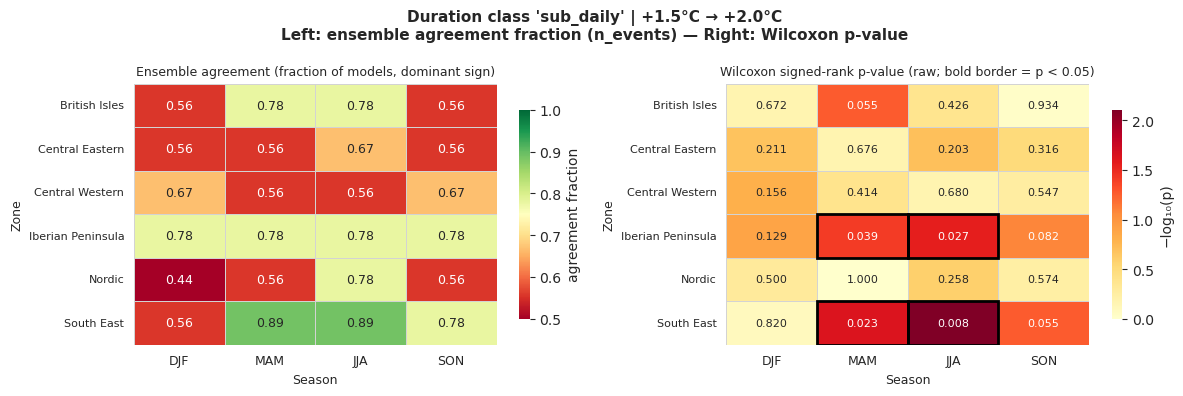

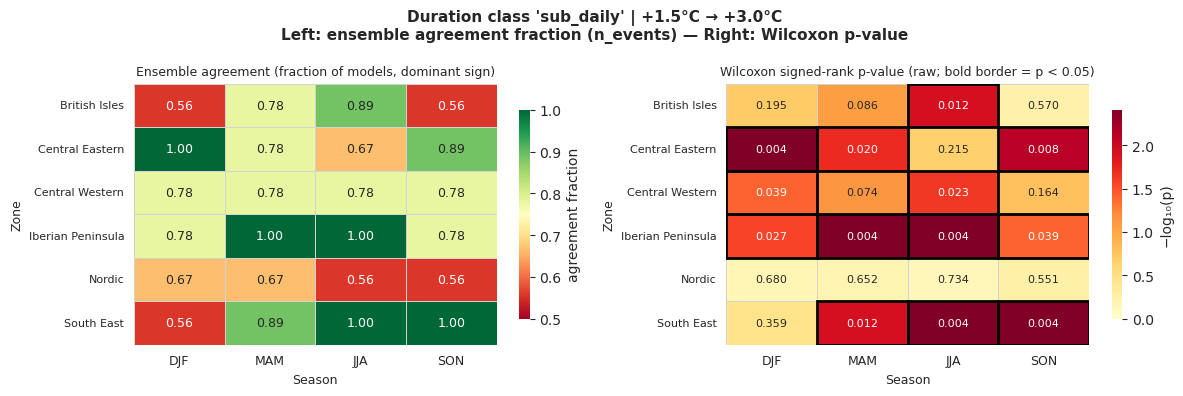

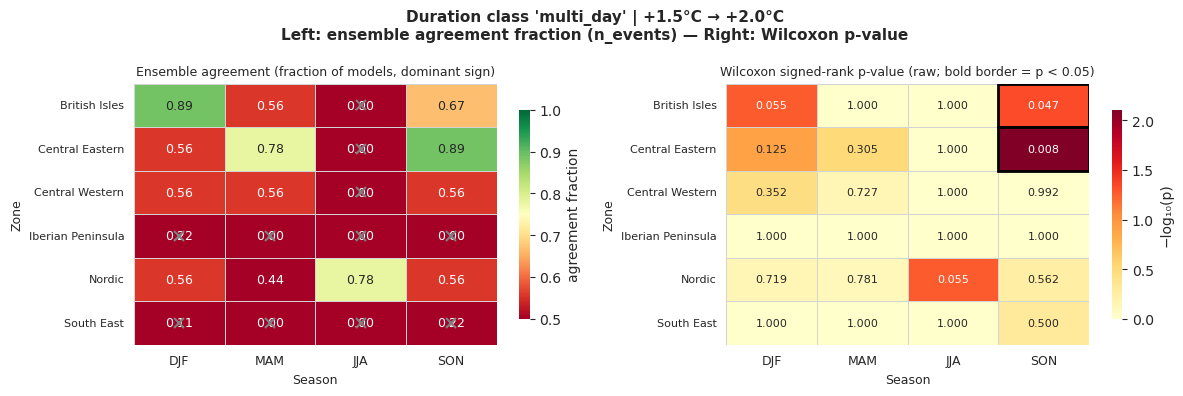

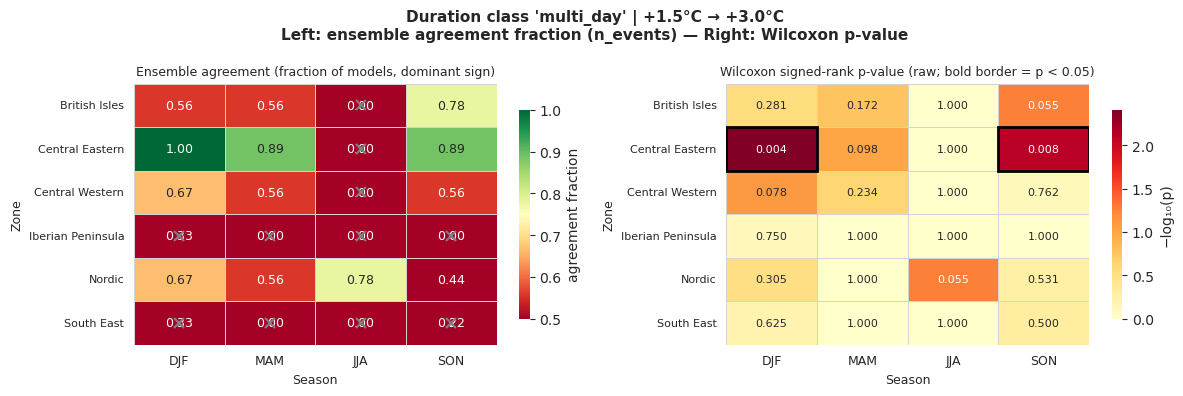

In [45]:
# Heatmap of ensemble agreement fraction (n_events) — one figure per (dc, comparison)
_zone_labels_c = [str(z) for z in zones]

for dc in DURATION_CLASS_ORDER:
    for comp in _comps_c:
        _sub = df_sig[
            (df_sig["duration_class"] == dc) &
            (df_sig["comparison"] == f"{_ref_c}→{comp}") &
            (df_sig["metric"] == "n_events")
        ]

        agree_piv = _sub.pivot(index="zone", columns="season", values="agree_frac") \
                        .reindex(index=_zone_labels_c, columns=season_order)
        sig_piv   = _sub.pivot(index="zone", columns="season", values="sig_05") \
                        .reindex(index=_zone_labels_c, columns=season_order)
        pct_piv   = _sub.pivot(index="zone", columns="season", values="pct_change") \
                        .reindex(index=_zone_labels_c, columns=season_order)

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        fig.suptitle(
            f"Duration class '{dc}' | {_ref_c} → {comp}\n"
            f"Left: ensemble agreement fraction (n_events) — Right: Wilcoxon p-value",
            fontsize=11, fontweight="bold",
        )

        # Agreement heatmap
        ax = axes[0]
        sns.heatmap(
            agree_piv, ax=ax,
            annot=True, fmt=".2f", cmap="RdYlGn",
            vmin=0.5, vmax=1.0,
            linewidths=0.5, linecolor="lightgray",
            cbar_kws={"label": "agreement fraction", "shrink": 0.8},
            annot_kws={"size": 9},
        )
        # Mark cells where the sign of the median change conflicts with majority direction
        for i, z in enumerate(agree_piv.index):
            for j, s in enumerate(agree_piv.columns):
                pct_v = pct_piv.loc[z, s]
                if not np.isfinite(pct_v):
                    ax.plot(j + 0.5, i + 0.5, "x", color="gray",
                            markersize=7, markeredgewidth=1.5, zorder=5)
        ax.set_title("Ensemble agreement (fraction of models, dominant sign)", fontsize=9)
        ax.set_yticklabels([z.replace("_", " ") for z in _zone_labels_c], rotation=0, fontsize=8)
        ax.set_xticklabels(season_order, rotation=0, fontsize=9)
        ax.set_xlabel("Season", fontsize=9); ax.set_ylabel("Zone", fontsize=9)

        # p-value heatmap (log scale via –log10)
        ax = axes[1]
        _sig_df = df_sig[
            (df_sig["duration_class"] == dc) &
            (df_sig["comparison"] == f"{_ref_c}→{comp}") &
            (df_sig["metric"] == "n_events")
        ].copy()
        _sig_df["neg_log10_p"] = -np.log10(_sig_df["p_wilcoxon"].clip(lower=1e-6))
        pval_piv = _sig_df.pivot(index="zone", columns="season", values="neg_log10_p") \
                          .reindex(index=_zone_labels_c, columns=season_order)

        annot_p = pval_piv.copy().astype(object)
        raw_piv = _sig_df.pivot(index="zone", columns="season", values="p_wilcoxon") \
                         .reindex(index=_zone_labels_c, columns=season_order)
        for r in annot_p.index:
            for c in annot_p.columns:
                v = raw_piv.loc[r, c]
                annot_p.loc[r, c] = f"{v:.3f}" if np.isfinite(v) else "—"

        sns.heatmap(
            pval_piv, ax=ax,
            annot=annot_p, fmt="",
            cmap="YlOrRd",
            vmin=0, vmax=max(float(pval_piv.values[np.isfinite(pval_piv.values)].max()), 1.3),
            linewidths=0.5, linecolor="lightgray",
            cbar_kws={"label": "−log₁₀(p)", "shrink": 0.8},
            annot_kws={"size": 8},
        )
        # Hatching for p < 0.05 threshold (−log10 > 1.3)
        for i, z in enumerate(pval_piv.index):
            for j, s in enumerate(pval_piv.columns):
                if sig_piv.loc[z, s]:
                    ax.add_patch(plt.Rectangle(
                        (j, i), 1, 1, fill=False, edgecolor="black",
                        linewidth=2, zorder=5,
                    ))
        ax.set_title("Wilcoxon signed-rank p-value (raw; bold border = p < 0.05)", fontsize=9)
        ax.set_yticklabels([z.replace("_", " ") for z in _zone_labels_c], rotation=0, fontsize=8)
        ax.set_xticklabels(season_order, rotation=0, fontsize=9)
        ax.set_xlabel("Season", fontsize=9); ax.set_ylabel("Zone", fontsize=9)

        plt.tight_layout()
        plt.show()

## C2 — Leave-one-out (LOO) stability

For each (zone, duration_class, comparison), remove one GCM-RCM chain at a time
and recompute the ensemble-median % change in n_events.  A narrow LOO range
(relative to the ensemble spread) indicates no single model dominates the signal.

The dot-and-whisker format shows: ensemble median (circle), IQR (thick bar),
and the range of LOO medians (thin bar).  If the LOO range falls inside the IQR,
the result is stable to individual model exclusion.

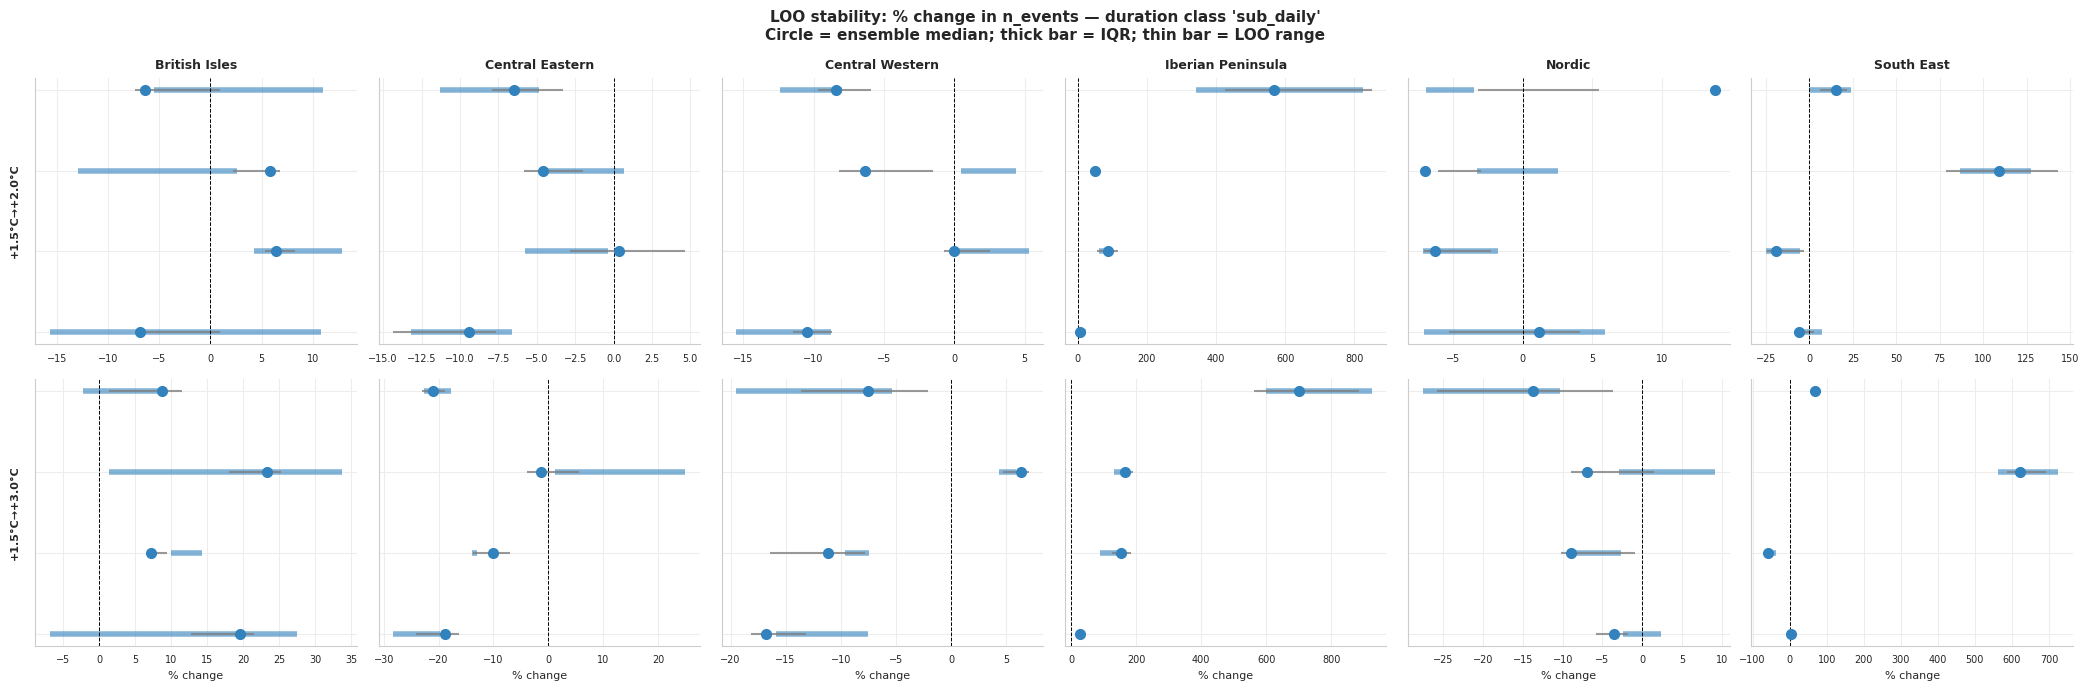

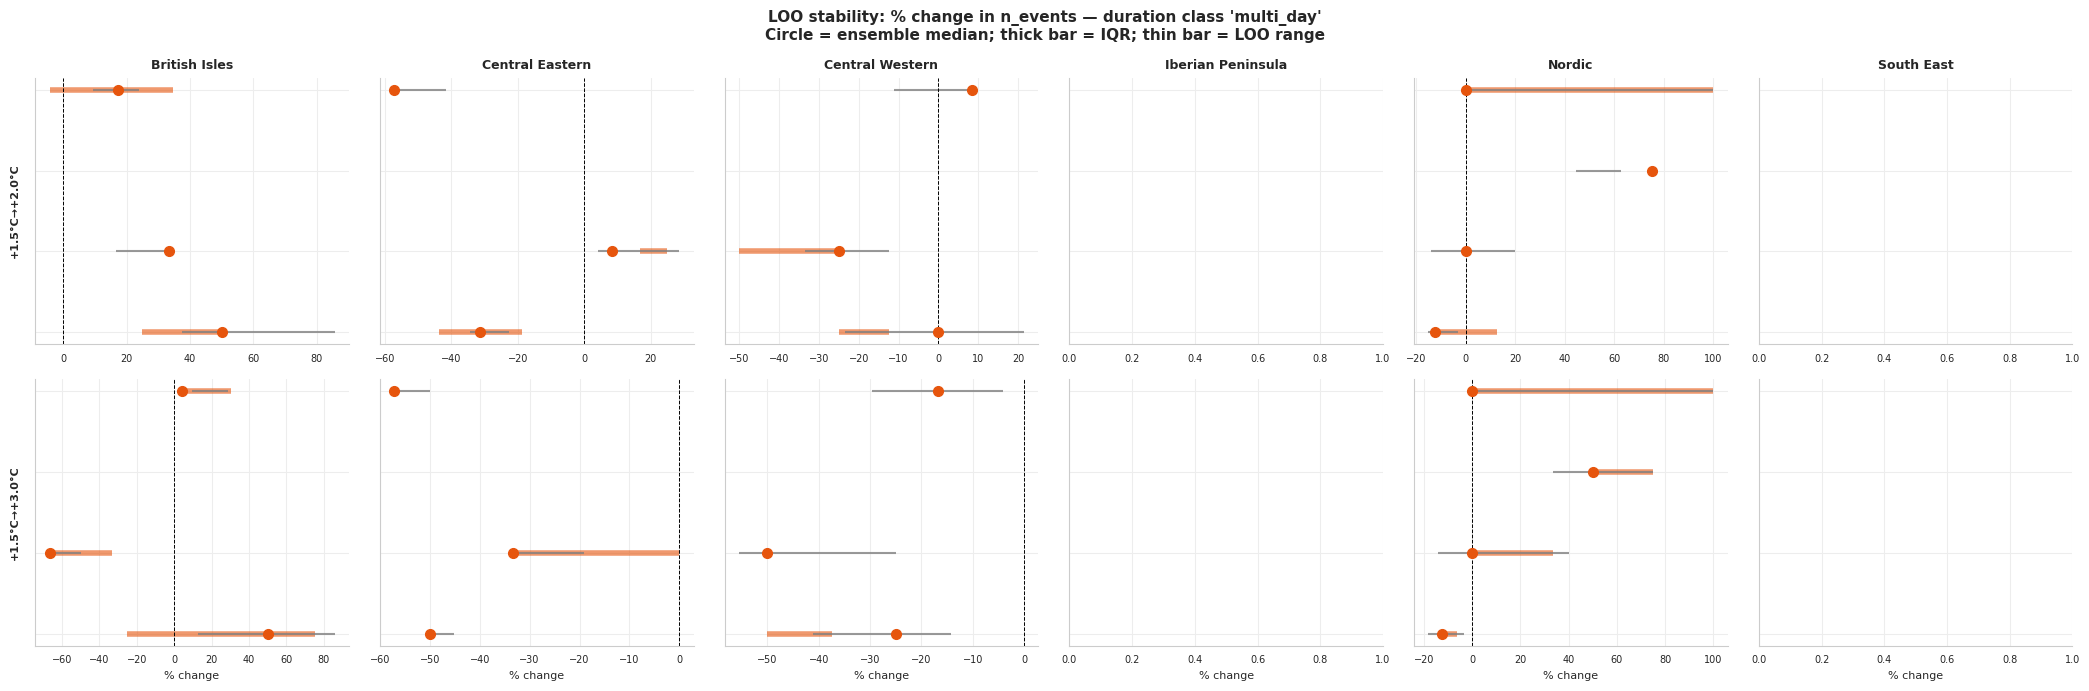

In [46]:
_zone_labels_c = [str(z) for z in zones]

for dc in DURATION_CLASS_ORDER:
    df_dc = df_seasonal[df_seasonal["duration_class"] == dc]

    fig, axes = plt.subplots(
        len(_comps_c), len(_zone_labels_c),
        figsize=(3.5 * len(_zone_labels_c), 3.5 * len(_comps_c)),
        sharey="row", squeeze=False,
    )
    fig.suptitle(
        f"LOO stability: % change in n_events — duration class '{dc}'\n"
        f"Circle = ensemble median; thick bar = IQR; thin bar = LOO range",
        fontsize=11, fontweight="bold",
    )

    for row_i, comp in enumerate(_comps_c):
        for col_i, zone in enumerate(_zone_labels_c):
            ax = axes[row_i][col_i]

            # Per-season median % change for the full ensemble and each LOO subset
            loo_data = {s: [] for s in season_order}
            full_data = {s: None for s in season_order}

            for season in season_order:
                ref_s = (
                    df_dc[(df_dc["zone"] == zone) & (df_dc["season"] == season)
                          & (df_dc["period"] == _ref_c)]
                    .set_index("model")["n_events"]
                )
                cmp_s = (
                    df_dc[(df_dc["zone"] == zone) & (df_dc["season"] == season)
                          & (df_dc["period"] == comp)]
                    .set_index("model")["n_events"]
                )
                common = ref_s.index.intersection(cmp_s.index)
                if len(common) < 3:
                    continue
                r = ref_s.loc[common]; c = cmp_s.loc[common]
                ref_med = float(r.median())
                if ref_med <= 0:
                    continue
                full_pct = (float(c.median()) - ref_med) / ref_med * 100
                full_data[season] = (
                    full_pct,
                    float(c.quantile(0.25) - r.quantile(0.25)) / ref_med * 100,
                    float(c.quantile(0.75) - r.quantile(0.75)) / ref_med * 100,
                )
                for m in common:
                    loo_models = [mm for mm in common if mm != m]
                    loo_pct = (float(c.loc[loo_models].median()) - float(r.loc[loo_models].median())) \
                              / float(r.loc[loo_models].median()) * 100 \
                              if float(r.loc[loo_models].median()) > 0 else np.nan
                    loo_data[season].append(loo_pct)

            y_pos = np.arange(len(season_order))
            for yi, season in enumerate(season_order):
                fd = full_data[season]
                ld = [v for v in loo_data[season] if np.isfinite(v)]
                if fd is None or not ld:
                    continue
                ax.plot(fd[0], yi, "o", color=duration_palette[dc], zorder=5, markersize=7)
                ax.hlines(yi, fd[1], fd[2], colors=duration_palette[dc], linewidth=4, alpha=0.6)
                ax.hlines(yi, min(ld), max(ld), colors="gray", linewidth=1.5, alpha=0.8)

            ax.axvline(0, color="black", linewidth=0.7, linestyle="--")
            ax.set_yticks(y_pos)
            ax.set_yticklabels(season_order if col_i == 0 else [], fontsize=8)
            ax.set_xlabel("% change" if row_i == len(_comps_c) - 1 else "", fontsize=8)
            if row_i == 0:
                ax.set_title(zone.replace("_", " "), fontsize=9, fontweight="bold")
            if col_i == 0:
                ax.set_ylabel(f"{_ref_c}→{comp}", fontsize=8, fontweight="bold")
            ax.tick_params(labelsize=7)
            sns.despine(ax=ax)

    plt.tight_layout()
    plt.show()

## C3 — Duration-bin sensitivity

The 24 h boundary between `sub_daily` and `multi_day` is physically motivated but
arbitrary at the margin.  Events lasting 20–28 h could fall into either class.
This cell recomputes ensemble-median n_events for three alternative boundaries
(18 h, 24 h, 30 h) and plots how the class-level counts change, for each zone and period.

A conclusion is **boundary-robust** if it holds for all three boundaries.

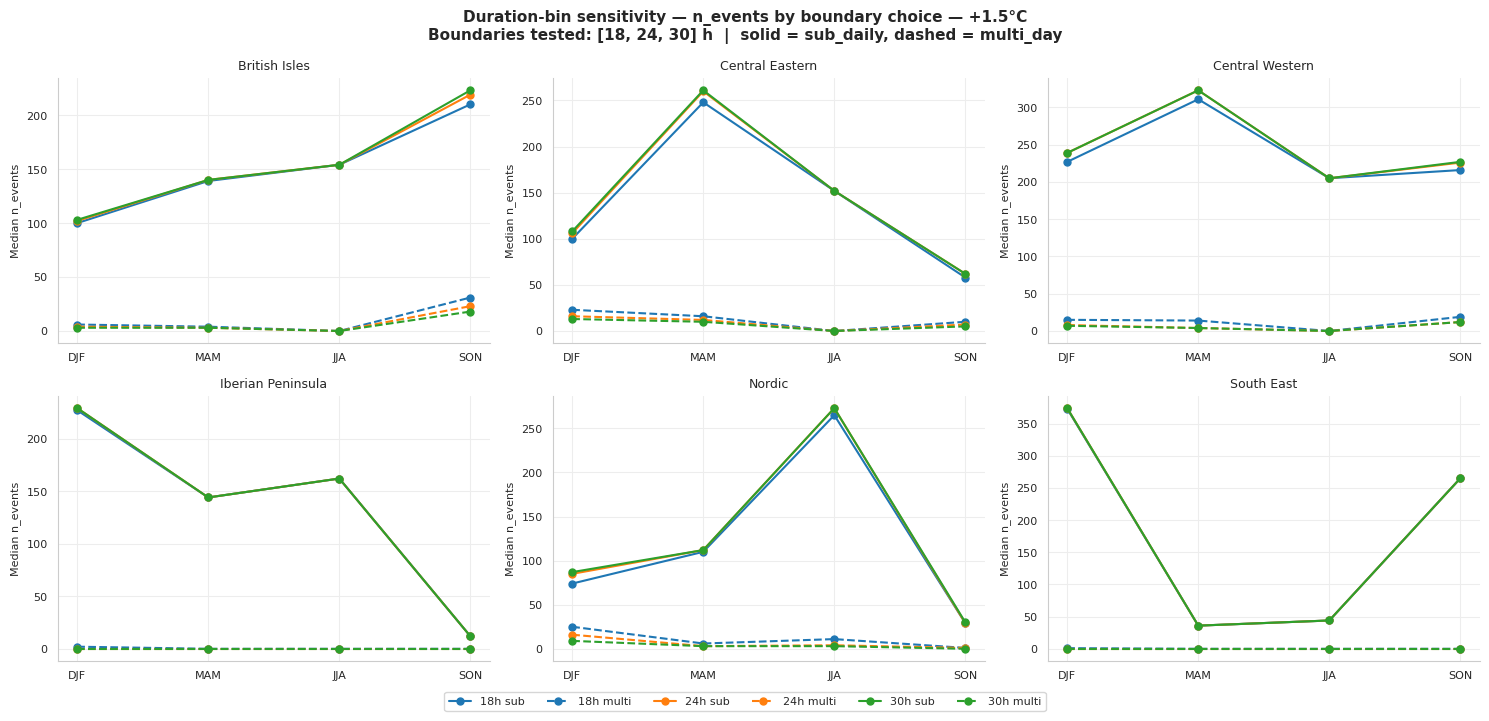

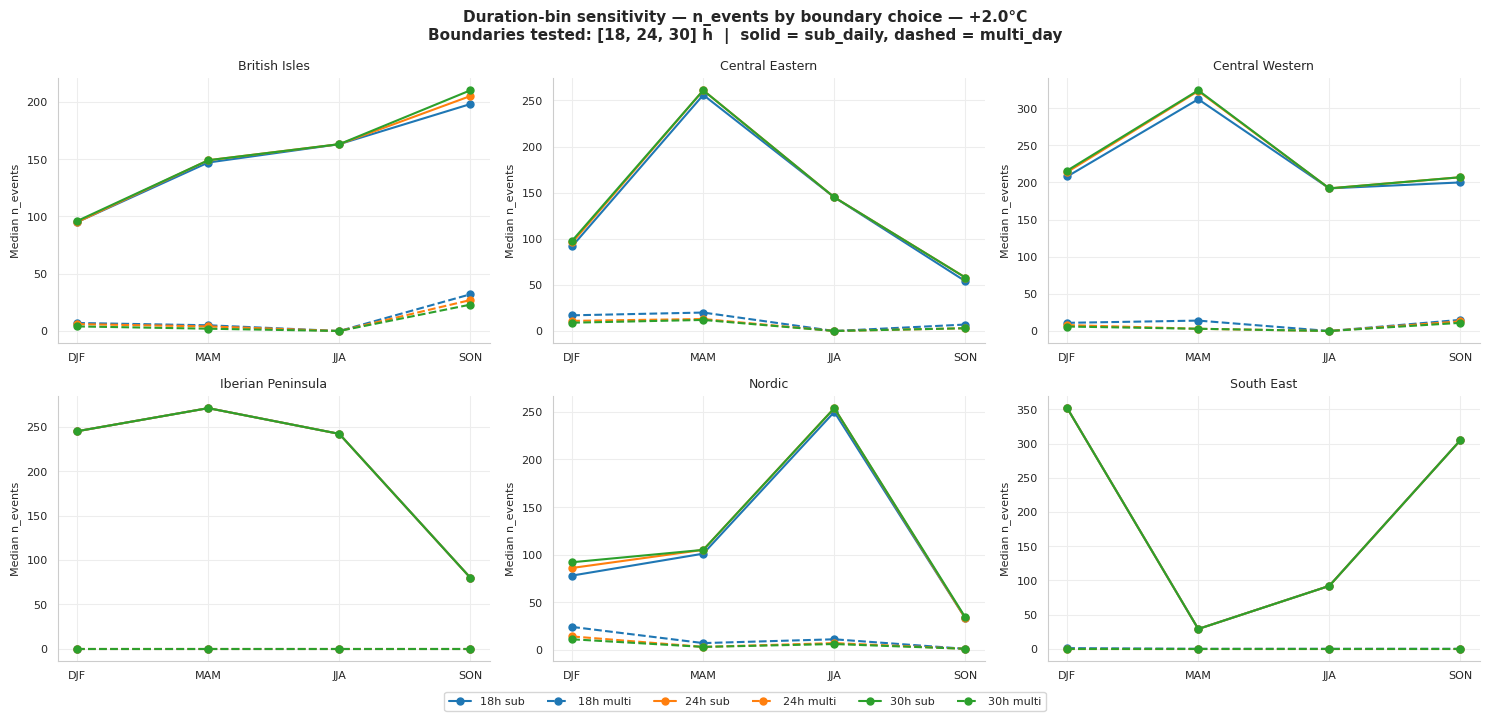

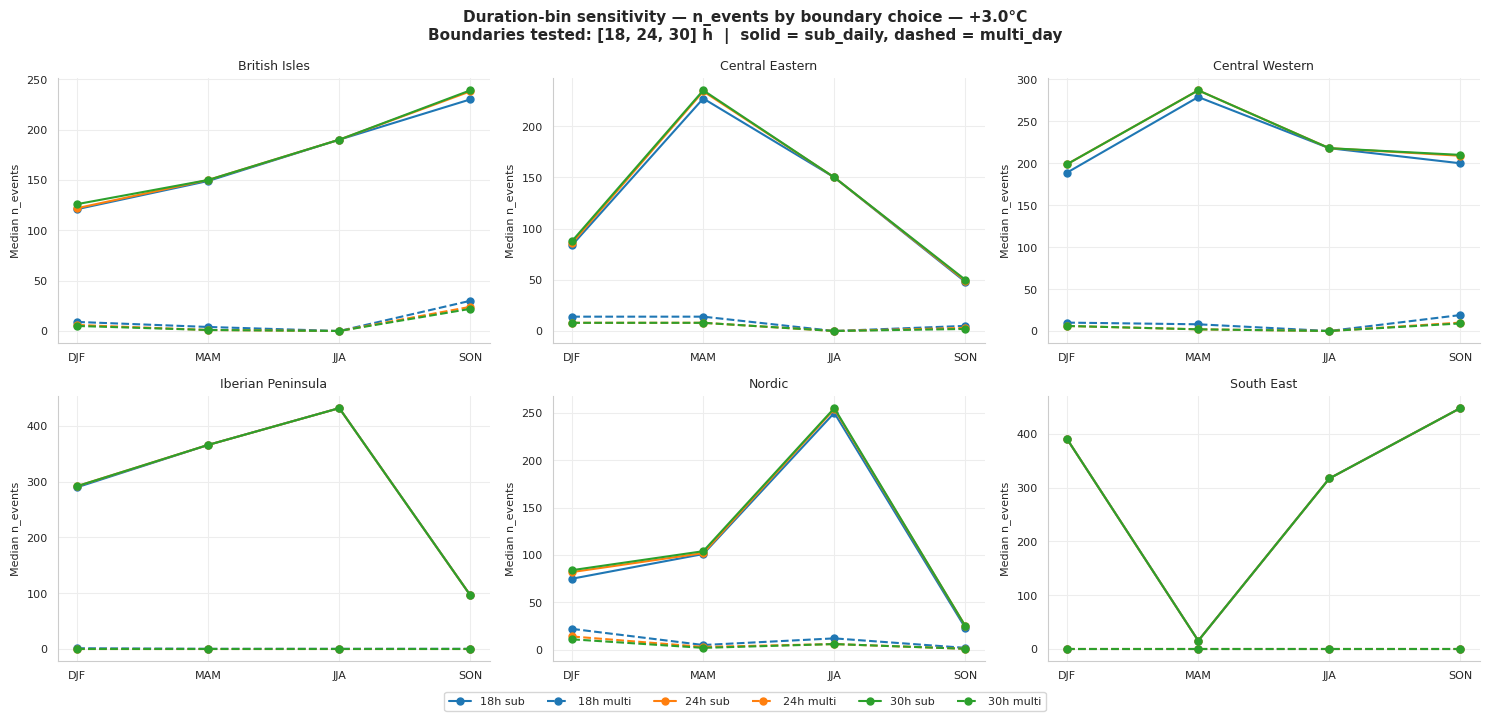

In [47]:
from cordex2energy_analysis.extremes_analysis import compute_seasonal_duration_stratified_metrics as _csdm

_boundaries  = [18, 24, 30]   # hours
_period_list = list(period_defs.keys())

# Recompute df_seasonal for each alternative boundary
_bin_results = {}
for _bnd in _boundaries:
    _bins = {"sub_daily": (0, _bnd), "multi_day": (_bnd, float("inf"))}
    _df = _csdm(
        _cache_rl, _cache_met, season_active_thresholds, period_defs,
        models, zones, season_order, season_months,
        method=EVENT_DETECTION_METHOD, duration_bins=_bins,
    )
    _bin_results[_bnd] = _df

# Plot: for each zone and period, how does ensemble-median sub_daily and multi_day
# n_events change across boundary choices?
_zone_labels_s = [str(z) for z in zones]

for period_name in _period_list:
    fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=False)
    fig.suptitle(
        f"Duration-bin sensitivity — n_events by boundary choice — {period_name}\n"
        f"Boundaries tested: {_boundaries} h  |  solid = sub_daily, dashed = multi_day",
        fontsize=11, fontweight="bold",
    )

    _bnd_colors = {18: "#1f77b4", 24: "#ff7f0e", 30: "#2ca02c"}

    for ax, zone in zip(axes.flat, _zone_labels_s):
        for _bnd, _df in _bin_results.items():
            _df_p = _df[(_df["period"] == period_name) & (_df["zone"] == zone)]
            for dc, ls in [("sub_daily", "-"), ("multi_day", "--")]:
                _vals = (
                    _df_p[_df_p["duration_class"] == dc]
                    .groupby("season")["n_events"]
                    .median()
                    .reindex(season_order, fill_value=0)
                )
                ax.plot(
                    season_order, _vals.values,
                    linestyle=ls, color=_bnd_colors[_bnd],
                    marker="o", markersize=5, linewidth=1.5,
                    label=f"{_bnd}h {'sub' if dc=='sub_daily' else 'multi'}",
                )

        ax.set_title(zone.replace("_", " "), fontsize=9)
        ax.set_ylabel("Median n_events", fontsize=8)
        ax.tick_params(labelsize=8)
        sns.despine(ax=ax)

    # Shared legend
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=6,
               fontsize=8, bbox_to_anchor=(0.5, -0.03))
    plt.tight_layout()
    plt.show()